## Загрузка и описание данных

In [1]:
# pip install phik

In [2]:
# импортируем необходимые библиотеки
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats as st
import numpy as np
import re
# import phik
# from phik.report import plot_correlation_matrix
# from phik import report

In [3]:
# отключаем предупреджения
import warnings
warnings.simplefilter('ignore')
pd.set_option('display.max_columns', None)

In [4]:
try:
    df = pd.read_csv("https://datahub.io/core/speed-dating/_r/-/data/speed-dating.csv")
except:
    df = pd.read_csv("speed-dating.csv")

In [5]:
df.head(5)

,has_null,wave,gender,age,age_o,d_age,d_d_age,race,race_o,samerace,importance_same_race,importance_same_religion,d_importance_same_race,d_importance_same_religion,field,pref_o_attractive,pref_o_sincere,pref_o_intelligence,pref_o_funny,pref_o_ambitious,pref_o_shared_interests,d_pref_o_attractive,d_pref_o_sincere,d_pref_o_intelligence,d_pref_o_funny,d_pref_o_ambitious,d_pref_o_shared_interests,attractive_o,sinsere_o,intelligence_o,funny_o,ambitous_o,shared_interests_o,d_attractive_o,d_sinsere_o,d_intelligence_o,d_funny_o,d_ambitous_o,d_shared_interests_o,attractive_important,sincere_important,intellicence_important,funny_important,ambtition_important,shared_interests_important,d_attractive_important,d_sincere_important,d_intellicence_important,d_funny_important,d_ambtition_important,d_shared_interests_important,attractive,sincere,intelligence,funny,ambition,d_attractive,d_sincere,d_intelligence,d_funny,d_ambition,attractive_partner,sincere_partner,intelligence_partner,funny_partner,ambition_partner,shared_interests_partner,d_attractive_partner,d_sincere_partner,d_intelligence_partner,d_funny_partner,d_ambition_partner,d_shared_interests_partner,sports,tvsports,exercise,dining,museums,art,hiking,gaming,clubbing,reading,tv,theater,movies,concerts,music,shopping,yoga,d_sports,d_tvsports,d_exercise,d_dining,d_museums,d_art,d_hiking,d_gaming,d_clubbing,d_reading,d_tv,d_theater,d_movies,d_concerts,d_music,d_shopping,d_yoga,interests_correlate,d_interests_correlate,expected_happy_with_sd_people,expected_num_interested_in_me,expected_num_matches,d_expected_happy_with_sd_people,d_expected_num_interested_in_me,d_expected_num_matches,like,guess_prob_liked,d_like,d_guess_prob_liked,met,decision,decision_o,match
0,0,1,female,21.0,27.0,6,[4-6],'asian/pacific islander/asian-american',european/caucasian-american,0,2.0,4.0,[2-5],[2-5],law,35.0,20.0,20.0,20.0,0.0,5.0,[21-100],[16-20],[16-20],[16-20],[0-15],[0-15],6.0,8.0,8.0,8.0,8.0,6.0,[6-8],[6-8],[6-8],[6-8],[6-8],[6-8],15.0,20.0,20.0,15.0,15.0,15.0,[0-15],[16-20],[16-20],[0-15],[0-15],[0-15],6.0,8.0,8.0,8.0,7.0,[6-8],[6-8],[6-8],[6-8],[6-8],6.0,9.0,7.0,7.0,6.0,5.0,[6-8],[9-10],[6-8],[6-8],[6-8],[0-5],9.0,2.0,8.0,9.0,1.0,1.0,5.0,1.0,5.0,6.0,9.0,1.0,10.0,10.0,9.0,8.0,1.0,[9-10],[0-5],[6-8],[9-10],[0-5],[0-5],[0-5],[0-5],[0-5],[6-8],[9-10],[0-5],[9-10],[9-10],[9-10],[6-8],[0-5],0.14,[0-0.33],3.0,2.0,4.0,[0-4],[0-3],[3-5],7.0,6.0,[6-8],[5-6],0.0,1,0,0
1,0,1,female,21.0,22.0,1,[0-1],'asian/pacific islander/asian-american',european/caucasian-american,0,2.0,4.0,[2-5],[2-5],law,60.0,0.0,0.0,40.0,0.0,0.0,[21-100],[0-15],[0-15],[21-100],[0-15],[0-15],7.0,8.0,10.0,7.0,7.0,5.0,[6-8],[6-8],[9-10],[6-8],[6-8],[0-5],15.0,20.0,20.0,15.0,15.0,15.0,[0-15],[16-20],[16-20],[0-15],[0-15],[0-15],6.0,8.0,8.0,8.0,7.0,[6-8],[6-8],[6-8],[6-8],[6-8],7.0,8.0,7.0,8.0,5.0,6.0,[6-8],[6-8],[6-8],[6-8],[0-5],[6-8],9.0,2.0,8.0,9.0,1.0,1.0,5.0,1.0,5.0,6.0,9.0,1.0,10.0,10.0,9.0,8.0,1.0,[9-10],[0-5],[6-8],[9-10],[0-5],[0-5],[0-5],[0-5],[0-5],[6-8],[9-10],[0-5],[9-10],[9-10],[9-10],[6-8],[0-5],0.54,[0.33-1],3.0,2.0,4.0,[0-4],[0-3],[3-5],7.0,5.0,[6-8],[5-6],1.0,1,0,0
2,1,1,female,21.0,22.0,1,[0-1],'asian/pacific islander/asian-american','asian/pacific islander/asian-american',1,2.0,4.0,[2-5],[2-5],law,19.0,18.0,19.0,18.0,14.0,12.0,[16-20],[16-20],[16-20],[16-20],[0-15],[0-15],10.0,10.0,10.0,10.0,10.0,10.0,[9-10],[9-10],[9-10],[9-10],[9-10],[9-10],15.0,20.0,20.0,15.0,15.0,15.0,[0-15],[16-20],[16-20],[0-15],[0-15],[0-15],6.0,8.0,8.0,8.0,7.0,[6-8],[6-8],[6-8],[6-8],[6-8],5.0,8.0,9.0,8.0,5.0,7.0,[0-5],[6-8],[9-10],[6-8],[0-5],[6-8],9.0,2.0,8.0,9.0,1.0,1.0,5.0,1.0,5.0,6.0,9.0,1.0,10.0,10.0,9.0,8.0,1.0,[9-10],[0-5],[6-8],[9-10],[0-5],[0-5],[0-5],[0-5],[0-5],[6-8],[9-10],[0-5],[9-10],[9-10],[9-10],[6-8],[0-5],0.16,[0-0.33],3.0,2.0,4.0,[0-4],[0-3],[3-5],7.0,NaN,[6-8],[0-4],1.0,1,1,1
3,0,1,female,21.0,23.0,2,[2-3],'asian/pacific islander/asian-american',european/caucasian-american,0,2.0,4.0,[2-5],[2-5],law,30.0,5.0,15.0,40.0,5.0,5.0,[21-100

<table>
    <tbody>
        <tr><th>Переменная</th><th>Описание</th></tr>
        <tr><td>has_null</td><td>Служебный флаг: содержит ли строка пропуски (1 — есть, 0 — нет)</td></tr>
        <tr><td>wave</td><td>Номер волны (серии) эксперимента</td></tr>
        <tr><td>gender</td><td>Пол участника (female / male)</td></tr>
        <tr><td>age</td><td>Возраст участника</td></tr>
        <tr><td>age_o</td><td>Возраст партнёра</td></tr>
        <tr><td>d_age</td><td>Разница в возрасте (участник − партнёр), представлена диапазоном</td></tr>
        <tr><td>d_d_age</td><td>Разностная (нормированная) версия разницы в возрасте, диапазон</td></tr>
        <tr><td>race</td><td>Раса участника (текстовая категория)</td></tr>
        <tr><td>race_o</td><td>Раса партнёра (текстовая категория)</td></tr>
        <tr><td>samerace</td><td>Совпадает ли раса участников: 1 — да, 0 — нет</td></tr>
        <tr><td>importance_same_race</td><td>Важность того, чтобы партнёр был той же расы (шкала)</td></tr>
        <tr><td>importance_same_religion</td><td>Важность того, чтобы партнёр исповедовал ту же религию (шкала)</td></tr>
        <tr><td>d_importance_same_race</td><td>Разностная версия важности совпадения расы, диапазон</td></tr>
        <tr><td>d_importance_same_religion</td><td>Разностная версия важности совпадения религии, диапазон</td></tr>
        <tr><td>field</td><td>Область обучения / специальность (категория)</td></tr>
        <tr><td>pref_o_attractive</td><td>Предпочтение партнёра: важность привлекательности (шкала)</td></tr>
        <tr><td>pref_o_sincere</td><td>Предпочтение партнёра: важность искренности (шкала)</td></tr>
        <tr><td>pref_o_intelligence</td><td>Предпочтение партнёра: важность интеллекта (шкала)</td></tr>
        <tr><td>pref_o_funny</td><td>Предпочтение партнёра: важность чувства юмора (шкала)</td></tr>
        <tr><td>pref_o_ambitious</td><td>Предпочтение партнёра: важность амбициозности (шкала)</td></tr>
        <tr><td>pref_o_shared_interests</td><td>Предпочтение партнёра: важность общих интересов (шкала)</td></tr>
        <tr><td>d_pref_o_attractive</td><td>Разностная версия предпочтения партнёра (привлекательность), диапазон</td></tr>
        <tr><td>d_pref_o_sincere</td><td>Разностная версия предпочтения партнёра (искренность), диапазон</td></tr>
        <tr><td>d_pref_o_intelligence</td><td>Разностная версия предпочтения партнёра (интеллект), диапазон</td></tr>
        <tr><td>d_pref_o_funny</td><td>Разностная версия предпочтения партнёра (юмор), диапазон</td></tr>
        <tr><td>d_pref_o_ambitious</td><td>Разностная версия предпочтения партнёра (амбициозность), диапазон</td></tr>
        <tr><td>d_pref_o_shared_interests</td><td>Разностная версия предпочтения партнёра (общие интересы), диапазон</td></tr>
        <tr><td>attractive_o</td><td>Оценка, которую партнёр дал моей привлекательности (вечер мероприятия)</td></tr>
        <tr><td>sinsere_o</td><td>Оценка, которую партнёр дал моей искренности (вечер мероприятия)</td></tr>
        <tr><td>intelligence_o</td><td>Оценка, которую партнёр дал моему интеллекту (вечер мероприятия)</td></tr>
        <tr><td>funny_o</td><td>Оценка, которую партнёр дал моему чувству юмора (вечер мероприятия)</td></tr>
        <tr><td>ambitous_o</td><td>Оценка, которую партнёр дал моей амбициозности (вечер мероприятия)</td></tr>
        <tr><td>shared_interests_o</td><td>Оценка, которую партнёр дал нашим общим интересам (вечер мероприятия)</td></tr>
        <tr><td>d_attractive_o</td><td>Разностная версия оценки партнёром привлекательности, диапазон</td></tr>
        <tr><td>d_sinsere_o</td><td>Разностная версия оценки партнёром искренности, диапазон</td></tr>
        <tr><td>d_intelligence_o</td><td>Разностная версия оценки партнёром интеллекта, диапазон</td></tr>
        <tr><td>d_funny_o</td><td>Разностная версия оценки партнёром юмора, диапазон</td></tr>
        <tr><td>d_ambitous_o</td><td>Разностная версия оценки партнёром амбициозности, диапазон</td></tr>
        <tr><td>d_shared_interests_o</td><td>Разностная версия оценки партнёром общих интересов, диапазон</td></tr>
        <tr><td>attractive_important</td><td>Важность привлекательности при моём выборе партнёра (шкала)</td></tr>
        <tr><td>sincere_important</td><td>Важность искренности при моём выборе партнёра (шкала)</td></tr>
        <tr><td>intellicence_important</td><td>Важность интеллекта при моём выборе партнёра (шкала)</td></tr>
        <tr><td>funny_important</td><td>Важность чувства юмора при моём выборе партнёра (шкала)</td></tr>
        <tr><td>ambtition_important</td><td>Важность амбициозности при моём выборе партнёра (шкала)</td></tr>
        <tr><td>shared_interests_important</td><td>Важность общих интересов при моём выборе партнёра (шкала)</td></tr>
        <tr><td>d_attractive_important</td><td>Разностная версия важности привлекательности, диапазон</td></tr>
        <tr><td>d_sincere_important</td><td>Разностная версия важности искренности, диапазон</td></tr>
        <tr><td>d_intellicence_important</td><td>Разностная версия важности интеллекта, диапазон</td></tr>
        <tr><td>d_funny_important</td><td>Разностная версия важности юмора, диапазон</td></tr>
        <tr><td>d_ambtition_important</td><td>Разностная версия важности амбициозности, диапазон</td></tr>
        <tr><td>d_shared_interests_important</td><td>Разностная версия важности общих интересов, диапазон</td></tr>
        <tr><td>attractive</td><td>Моя самооценка по привлекательности (до мероприятия)</td></tr>
        <tr><td>sincere</td><td>Моя самооценка по искренности</td></tr>
        <tr><td>intelligence</td><td>Моя самооценка по интеллекту</td></tr>
        <tr><td>funny</td><td>Моя самооценка по чувству юмора</td></tr>
        <tr><td>ambition</td><td>Моя самооценка по амбициозности</td></tr>
        <tr><td>d_attractive</td><td>Разностная версия самооценки привлекательности, диапазон</td></tr>
        <tr><td>d_sincere</td><td>Разностная версия самооценки искренности, диапазон</td></tr>
        <tr><td>d_intelligence</td><td>Разностная версия самооценки интеллекта, диапазон</td></tr>
        <tr><td>d_funny</td><td>Разностная версия самооценки юмора, диапазон</td></tr>
        <tr><td>d_ambition</td><td>Разностная версия самооценки амбициозности, диапазон</td></tr>
        <tr><td>attractive_partner</td><td>Моя оценка привлекательности партнёра</td></tr>
        <tr><td>sincere_partner</td><td>Моя оценка искренности партнёра</td></tr>
        <tr><td>intelligence_partner</td><td>Моя оценка интеллекта партнёра</td></tr>
        <tr><td>funny_partner</td><td>Моя оценка чувства юмора партнёра</td></tr>
        <tr><td>ambition_partner</td><td>Моя оценка амбициозности партнёра</td></tr>
        <tr><td>shared_interests_partner</td><td>Моя оценка общих интересов с партнёром</td></tr>
        <tr><td>d_attractive_partner</td><td>Разностная версия моей оценки привлекательности партнёра, диапазон</td></tr>
        <tr><td>d_sincere_partner</td><td>Разностная версия моей оценки искренности партнёра, диапазон</td></tr>
        <tr><td>d_intelligence_partner</td><td>Разностная версия моей оценки интеллекта партнёра, диапазон</td></tr>
        <tr><td>d_funny_partner</td><td>Разностная версия моей оценки юмора партнёра, диапазон</td></tr>
        <tr><td>d_ambition_partner</td><td>Разностная версия моей оценки амбициозности партнёра, диапазон</td></tr>
        <tr><td>d_shared_interests_partner</td><td>Разностная версия моей оценки общих интересов партнёра, диапазон</td></tr>
        <tr><td>sports</td><td>Мой интерес к спорту (шкала 1–10)</td></tr>
        <tr><td>tvsports</td><td>Мой интерес к спортивным трансляциям (шкала 1–10)</td></tr>
        <tr><td>exercise</td><td>Мой интерес к фитнесу/упражнениям (шкала 1–10)</td></tr>
        <tr><td>dining</td><td>Мой интерес к ресторанам/кулинарии (шкала 1–10)</td></tr>
        <tr><td>museums</td><td>Мой интерес к музеям (шкала 1–10)</td></tr>
        <tr><td>art</td><td>Мой интерес к искусству (шкала 1–10)</td></tr>
        <tr><td>hiking</td><td>Мой интерес к походам (шкала 1–10)</td></tr>
        <tr><td>gaming</td><td>Мой интерес к видеоиграм (шкала 1–10)</td></tr>
        <tr><td>clubbing</td><td>Мой интерес к клубам (шкала 1–10)</td></tr>
        <tr><td>reading</td><td>Мой интерес к чтению (шкала 1–10)</td></tr>
        <tr><td>tv</td><td>Мой интерес к телевидению (шкала 1–10)</td></tr>
        <tr><td>theater</td><td>Мой интерес к театру (шкала 1–10)</td></tr>
        <tr><td>movies</td><td>Мой интерес к кино (шкала 1–10)</td></tr>
        <tr><td>concerts</td><td>Мой интерес к концертам (шкала 1–10)</td></tr>
        <tr><td>music</td><td>Мой интерес к музыке (шкала 1–10)</td></tr>
        <tr><td>shopping</td><td>Мой интерес к шопингу (шкала 1–10)</td></tr>
        <tr><td>yoga</td><td>Мой интерес к йоге (шкала 1–10)</td></tr>
        <tr><td>d_sports</td><td>Разностная версия интереса к спорту, диапазон</td></tr>
        <tr><td>d_tvsports</td><td>Разностная версия интереса к спортивным трансляциям, диапазон</td></tr>
        <tr><td>d_exercise</td><td>Разностная версия интереса к фитнесу, диапазон</td></tr>
        <tr><td>d_dining</td><td>Разностная версия интереса к ресторанам, диапазон</td></tr>
        <tr><td>d_museums</td><td>Разностная версия интереса к музеям, диапазон</td></tr>
        <tr><td>d_art</td><td>Разностная версия интереса к искусству, диапазон</td></tr>
        <tr><td>d_hiking</td><td>Разностная версия интереса к походам, диапазон</td></tr>
        <tr><td>d_gaming</td><td>Разностная версия интереса к видеоиграм, диапазон</td></tr>
        <tr><td>d_clubbing</td><td>Разностная версия интереса к клубам, диапазон</td></tr>
        <tr><td>d_reading</td><td>Разностная версия интереса к чтению, диапазон</td></tr>
        <tr><td>d_tv</td><td>Разностная версия интереса к телевидению, диапазон</td></tr>
        <tr><td>d_theater</td><td>Разностная версия интереса к театру, диапазон</td></tr>
        <tr><td>d_movies</td><td>Разностная версия интереса к кино, диапазон</td></tr>
        <tr><td>d_concerts</td><td>Разностная версия интереса к концертам, диапазон</td></tr>
        <tr><td>d_music</td><td>Разностная версия интереса к музыке, диапазон</td></tr>
        <tr><td>d_shopping</td><td>Разностная версия интереса к шопингу, диапазон</td></tr>
        <tr><td>d_yoga</td><td>Разностная версия интереса к йоге, диапазон</td></tr>
        <tr><td>interests_correlate</td><td>Корреляция между моими интересами и интересами партнёра ([-1; 1])</td></tr>
        <tr><td>d_interests_correlate</td><td>Разностная версия корреляции интересов, диапазон</td></tr>
        <tr><td>expected_happy_with_sd_people</td><td>Ожидаемый уровень счастья от общения с участниками быстрых свиданий (шкала)</td></tr>
        <tr><td>expected_num_interested_in_me</td><td>Сколько из 20 участников, по моему мнению, будут заинтересованы во мне</td></tr>
        <tr><td>expected_num_matches</td><td>Сколько совпадений я ожидаю получить</td></tr>
        <tr><td>d_expected_happy_with_sd_people</td><td>Разностная версия ожидаемого счастья, диапазон</td></tr>
        <tr><td>d_expected_num_interested_in_me</td><td>Разностная версия ожидаемого числа заинтересованных, диапазон</td></tr>
        <tr><td>d_expected_num_matches</td><td>Разностная версия ожидаемого числа совпадений, диапазон</td></tr>
        <tr><td>like</td><td>Понравился ли мне партнёр</td></tr>
        <tr><td>guess_prob_liked</td><td>Моя оценка вероятности, что я нравлюсь партнёру ([0; 1])</td></tr>
        <tr><td>d_like</td><td>Разностная версия признака «понравился», диапазон</td></tr>
        <tr><td>d_guess_prob_liked</td><td>Разностная версия оценки вероятности, диапазон</td></tr>
        <tr><td>met</td><td>Встречались ли мы с партнёром раньше</td></tr>
        <tr><td>decision</td><td>Моё решение: 1 — пригласить на свидание, 0 — нет</td></tr>
        <tr><td>decision_o</td><td>Решение партнёра: 1 — пригласить, 0 — нет</td></tr>
        <tr><td>match</td><td>Совпадение (оба сказали «да»): 1 — да, 0 — нет</td></tr>
    </tbody>
</table>

Таким образом, показатели можно разделить на следующие группы:

## 1. Собственные показатели (обо мне)

**Демография:**
`age`, `gender`, `race`, `field`

**Самооценка:**
`attractive`, `sincere`, `intelligence`, `funny`, `ambition`

**Мои интересы:**
`sports`, `tvsports`, `exercise`, `dining`, `museums`, `art`, `hiking`, `gaming`, `clubbing`, `reading`, `tv`, `theater`, `movies`, `concerts`, `music`, `shopping`, `yoga`

**Мои предпочтения — что я ценю в партнёре:**
`attractive_important`, `sincere_important`, `intellicence_important`, `funny_important`, `ambtition_important`, `shared_interests_important`

**Мои установки:**
`importance_same_race`, `importance_same_religion`

**Мои ожидания:**
`expected_happy_with_sd_people`, `expected_num_interested_in_me`, `expected_num_matches`

**Моя оценка партнёра:**
`attractive_partner`, `sincere_partner`, `intelligence_partner`, `funny_partner`, `ambition_partner`, `shared_interests_partner`

## 2. Показатели партнёра

**Демография партнёра:**
`age_o`, `race_o`

**Предпочтения партнёра (что партнёр ценит во мне):**

`pref_o_attractive`, `pref_o_sincere`, `pref_o_intelligence`, `pref_o_funny`, `pref_o_ambitious`, `pref_o_shared_interests`

**Оценка партнёром меня:**

`attractive_o`, `sinsere_o`, `intelligence_o`, `funny_o`, `ambitous_o`, `shared_interests_o`

## 3. Разностные версии (`d_*`)

**Возраст:**
`d_age`, `d_d_age`

**Установки:**
`d_importance_same_race`, `d_importance_same_religion`

**Предпочтения партнёра:**
`d_pref_o_attractive`, `d_pref_o_sincere`, `d_pref_o_intelligence`, `d_pref_o_funny`, `d_pref_o_ambitious`, `d_pref_o_shared_interests`

**Оценка меня партнёром:**
`d_attractive_o`, `d_sinsere_o`, `d_intelligence_o`, `d_funny_o`, `d_ambitous_o`, `d_shared_interests_o`

**Мои предпочтения:**
`d_attractive_important`, `d_sincere_important`, `d_intellicence_important`, `d_funny_important`, `d_ambtition_important`, `d_shared_interests_important`

**Самооценка:**
`d_attractive`, `d_sincere`, `d_intelligence`, `d_funny`, `d_ambition`

**Моя оценка партнёра:**
`d_attractive_partner`, `d_sincere_partner`, `d_intelligence_partner`, `d_funny_partner`, `d_ambition_partner`, `d_shared_interests_partner`

**Интересы:**
`d_sports`, `d_tvsports`, `d_exercise`, `d_dining`, `d_museums`, `d_art`, `d_hiking`, `d_gaming`, `d_clubbing`, `d_reading`, `d_tv`, `d_theater`, `d_movies`, `d_concerts`, `d_music`, `d_shopping`, `d_yoga`

**Корреляция интересов:**
`d_interests_correlate`

**Ожидания:**
`d_expected_happy_with_sd_people`, `d_expected_num_interested_in_me`, `d_expected_num_matches`

**Отношение/исход:**
`d_like`, `d_guess_prob_liked`

## 4. Прокси для прогнозируемого показателя (match)

**Моё отношение:**
`like`, `guess_prob_liked`, `decision`

**Отношение партнёра:**
`decision_o`

**Совпадения/сходства:**
`samerace`, `interests_correlate`

**История:**
`met`
    
## 5. Служебные

`has_null`, `wave`

## 6. Итог

`match`

In [6]:
# Так как столбцов много, напишем ф-ю для поиска русского описания 
col_ru = {
    "has_null": "служебный флаг пропусков",
    "wave": "номер волны эксперимента",
    "gender": "пол участника",
    "age": "возраст участника",
    "age_o": "возраст партнёра",
    "d_age": "разница в возрасте (диапазон)",
    "d_d_age": "нормированная разница в возрасте (диапазон)",
    "race": "раса участника",
    "race_o": "раса партнёра",
    "samerace": "совпадение расы (1/0)",
    "importance_same_race": "важность совпадения расы",
    "importance_same_religion": "важность совпадения религии",
    "d_importance_same_race": "разностная важность совпадения расы (диапазон)",
    "d_importance_same_religion": "разностная важность совпадения религии (диапазон)",
    "field": "область обучения / специальность",
    "pref_o_attractive": "предпочтение партнёра: привлекательность",
    "pref_o_sincere": "предпочтение партнёра: искренность",
    "pref_o_intelligence": "предпочтение партнёра: интеллект",
    "pref_o_funny": "предпочтение партнёра: юмор",
    "pref_o_ambitious": "предпочтение партнёра: амбициозность",
    "pref_o_shared_interests": "предпочтение партнёра: общие интересы",
    "d_pref_o_attractive": "разностное предпочтение партнёра: привлекательность (диапазон)",
    "d_pref_o_sincere": "разностное предпочтение партнёра: искренность (диапазон)",
    "d_pref_o_intelligence": "разностное предпочтение партнёра: интеллект (диапазон)",
    "d_pref_o_funny": "разностное предпочтение партнёра: юмор (диапазон)",
    "d_pref_o_ambitious": "разностное предпочтение партнёра: амбициозность (диапазон)",
    "d_pref_o_shared_interests": "разностное предпочтение партнёра: общие интересы (диапазон)",
    "attractive_o": "оценка партнёром моей привлекательности",
    "sinsere_o": "оценка партнёром моей искренности",
    "intelligence_o": "оценка партнёром моего интеллекта",
    "funny_o": "оценка партнёром моего юмора",
    "ambitous_o": "оценка партнёром моей амбициозности",
    "shared_interests_o": "оценка партнёром общих интересов",
    "d_attractive_o": "разностная оценка партнёром привлекательности (диапазон)",
    "d_sinsere_o": "разностная оценка партнёром искренности (диапазон)",
    "d_intelligence_o": "разностная оценка партнёром интеллекта (диапазон)",
    "d_funny_o": "разностная оценка партнёром юмора (диапазон)",
    "d_ambitous_o": "разностная оценка партнёром амбициозности (диапазон)",
    "d_shared_interests_o": "разностная оценка партнёром общих интересов (диапазон)",
    "attractive_important": "важность привлекательности при моём выборе",
    "sincere_important": "важность искренности при моём выборе",
    "intellicence_important": "важность интеллекта при моём выборе",
    "funny_important": "важность юмора при моём выборе",
    "ambtition_important": "важность амбициозности при моём выборе",
    "shared_interests_important": "важность общих интересов при моём выборе",
    "d_attractive_important": "разностная важность привлекательности (диапазон)",
    "d_sincere_important": "разностная важность искренности (диапазон)",
    "d_intellicence_important": "разностная важность интеллекта (диапазон)",
    "d_funny_important": "разностная важность юмора (диапазон)",
    "d_ambtition_important": "разностная важность амбициозности (диапазон)",
    "d_shared_interests_important": "разностная важность общих интересов (диапазон)",
    "attractive": "моя самооценка: привлекательность",
    "sincere": "моя самооценка: искренность",
    "intelligence": "моя самооценка: интеллект",
    "funny": "моя самооценка: юмор",
    "ambition": "моя самооценка: амбициозность",
    "d_attractive": "разностная самооценка привлекательности (диапазон)",
    "d_sincere": "разностная самооценка искренности (диапазон)",
    "d_intelligence": "разностная самооценка интеллекта (диапазон)",
    "d_funny": "разностная самооценка юмора (диапазон)",
    "d_ambition": "разностная самооценка амбициозности (диапазон)",
    "attractive_partner": "моя оценка привлекательности партнёра",
    "sincere_partner": "моя оценка искренности партнёра",
    "intelligence_partner": "моя оценка интеллекта партнёра",
    "funny_partner": "моя оценка юмора партнёра",
    "ambition_partner": "моя оценка амбициозности партнёра",
    "shared_interests_partner": "моя оценка общих интересов",
    "d_attractive_partner": "разностная оценка привлекательности партнёра (диапазон)",
    "d_sincere_partner": "разностная оценка искренности партнёра (диапазон)",
    "d_intelligence_partner": "разностная оценка интеллекта партнёра (диапазон)",
    "d_funny_partner": "разностная оценка юмора партнёра (диапазон)",
    "d_ambition_partner": "разностная оценка амбициозности партнёра (диапазон)",
    "d_shared_interests_partner": "разностная оценка общих интересов (диапазон)",
    "sports": "интерес к спорту",
    "tvsports": "интерес к спортивным трансляциям",
    "exercise": "интерес к фитнесу",
    "dining": "интерес к ресторанам",
    "museums": "интерес к музеям",
    "art": "интерес к искусству",
    "hiking": "интерес к походам",
    "gaming": "интерес к видеоиграм",
    "clubbing": "интерес к клубам",
    "reading": "интерес к чтению",
    "tv": "интерес к телевидению",
    "theater": "интерес к театру",
    "movies": "интерес к кино",
    "concerts": "интерес к концертам",
    "music": "интерес к музыке",
    "shopping": "интерес к шопингу",
    "yoga": "интерес к йоге",
    "d_sports": "разностный интерес к спорту (диапазон)",
    "d_tvsports": "разностный интерес к спортивным трансляциям (диапазон)",
    "d_exercise": "разностный интерес к фитнесу (диапазон)",
    "d_dining": "разностный интерес к ресторанам (диапазон)",
    "d_museums": "разностный интерес к музеям (диапазон)",
    "d_art": "разностный интерес к искусству (диапазон)",
    "d_hiking": "разностный интерес к походам (диапазон)",
    "d_gaming": "разностный интерес к видеоиграм (диапазон)",
    "d_clubbing": "разностный интерес к клубам (диапазон)",
    "d_reading": "разностный интерес к чтению (диапазон)",
    "d_tv": "разностный интерес к телевидению (диапазон)",
    "d_theater": "разностный интерес к театру (диапазон)",
    "d_movies": "разностный интерес к кино (диапазон)",
    "d_concerts": "разностный интерес к концертам (диапазон)",
    "d_music": "разностный интерес к музыке (диапазон)",
    "d_shopping": "разностный интерес к шопингу (диапазон)",
    "d_yoga": "разностный интерес к йоге (диапазон)",
    "interests_correlate": "корреляция интересов",
    "d_interests_correlate": "разностная корреляция интересов (диапазон)",
    "expected_happy_with_sd_people": "ожидаемое счастье от быстрых свиданий",
    "expected_num_interested_in_me": "ожидаемое число заинтересованных во мне",
    "expected_num_matches": "ожидаемое число совпадений",
    "d_expected_happy_with_sd_people": "разностное ожидаемое счастье (диапазон)",
    "d_expected_num_interested_in_me": "разностное ожидаемое число заинтересованных (диапазон)",
    "d_expected_num_matches": "разностное ожидаемое число совпадений (диапазон)",
    "like": "понравился ли партнёр",
    "guess_prob_liked": "оценка вероятности, что я нравлюсь партнёру",
    "d_like": "разностный признак «понравился» (диапазон)",
    "d_guess_prob_liked": "разностная оценка вероятности (диапазон)",
    "met": "встречались ли раньше",
    "decision": "моё решение (1/0)",
    "decision_o": "решение партнёра (1/0)",
    "match": "совпадение (1/0)",
}

def ru(col):
    """Возвращает русское описание столбца по его английскому имени"""
    return col_ru.get(col, f"[нет описания для '{col}']")

In [7]:
def describe_cols(cols):
    """Печатает таблицу: английское имя → русское описание"""
    rows = [{"столбец": c, "описание": ru(c)} for c in cols]
    display(pd.DataFrame(rows).set_index("столбец"))

In [8]:
describe_cols(["age", "age_o", "match", "decision", "attractive"])

,описание
столбец,
age,возраст участника
age_o,возраст партнёра
match,совпадение (1/0)
decision,моё решение (1/0)
attractive,моя самооценка: привлекательность


In [9]:
df.info(verbose=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8378 entries, 0 to 8377
Data columns (total 123 columns):
 #    Column                           Dtype  
---   ------                           -----  
 0    has_null                         int64  
 1    wave                             int64  
 2    gender                           object 
 3    age                              float64
 4    age_o                            float64
 5    d_age                            int64  
 6    d_d_age                          object 
 7    race                             object 
 8    race_o                           object 
 9    samerace                         int64  
 10   importance_same_race             float64
 11   importance_same_religion         float64
 12   d_importance_same_race           object 
 13   d_importance_same_religion       object 
 14   field                            object 
 15   pref_o_attractive                float64
 16   pref_o_sincere                   float64

In [10]:
# так как в датасете достаточно много категориальных признаков, выведем статистику сразу по количественным и категориальным
df.describe(include='all')

,has_null,wave,gender,age,age_o,d_age,d_d_age,race,race_o,samerace,importance_same_race,importance_same_religion,d_importance_same_race,d_importance_same_religion,field,pref_o_attractive,pref_o_sincere,pref_o_intelligence,pref_o_funny,pref_o_ambitious,pref_o_shared_interests,d_pref_o_attractive,d_pref_o_sincere,d_pref_o_intelligence,d_pref_o_funny,d_pref_o_ambitious,d_pref_o_shared_interests,attractive_o,sinsere_o,intelligence_o,funny_o,ambitous_o,shared_interests_o,d_attractive_o,d_sinsere_o,d_intelligence_o,d_funny_o,d_ambitous_o,d_shared_interests_o,attractive_important,sincere_important,intellicence_important,funny_important,ambtition_important,shared_interests_important,d_attractive_important,d_sincere_important,d_intellicence_important,d_funny_important,d_ambtition_important,d_shared_interests_important,attractive,sincere,intelligence,funny,ambition,d_attractive,d_sincere,d_intelligence,d_funny,d_ambition,attractive_partner,sincere_partner,intelligence_partner,funny_partner,ambition_partner,shared_interests_partner,d_attractive_partner,d_sincere_partner,d_intelligence_partner,d_funny_partner,d_ambition_partner,d_shared_interests_partner,sports,tvsports,exercise,dining,museums,art,hiking,gaming,clubbing,reading,tv,theater,movies,concerts,music,shopping,yoga,d_sports,d_tvsports,d_exercise,d_dining,d_museums,d_art,d_hiking,d_gaming,d_clubbing,d_reading,d_tv,d_theater,d_movies,d_concerts,d_music,d_shopping,d_yoga,interests_correlate,d_interests_correlate,expected_happy_with_sd_people,expected_num_interested_in_me,expected_num_matches,d_expected_happy_with_sd_people,d_expected_num_interested_in_me,d_expected_num_matches,like,guess_prob_liked,d_like,d_guess_prob_liked,met,decision,decision_o,match
count,8378.00000,8378.000000,8378,8283.000000,8274.000000,8378.000000,8378,8315,8305,8378.000000,8299.000000,8299.000000,8378,8378,8315,8289.000000,8289.000000,8289.000000,8280.000000,8271.000000,8249.000000,8378,8378,8378,8378,8378,8378,8166.000000,8091.000000,8072.000000,8018.000000,7656.000000,7302.000000,8378,8378,8378,8378,8378,8378,8299.000000,8299.000000,8299.000000,8289.000000,8279.000000,8257.000000,8378,8378,8378,8378,8378,8378,8273.000000,8273.000000,8273.000000,8273.000000,8273.000000,8378,8378,8378,8378,8378,8176.000000,8101.000000,8082.000000,8028.000000,7666.000000,7311.000000,8378,8378,8378,8378,8378,8378,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8378,8378,8378,8378,8378,8378,8378,8378,8378,8378,8378,8378,8378,8378,8378,8378,8378,8220.000000,8378,8277.000000,1800.000000,7205.000000,8378,8378,8378,8138.000000,8069.000000,8378,8378,8003.000000,8378.000000,8378.000000,8378.000000
unique,NaN,NaN,2,NaN,NaN,NaN,4,5,5,NaN,NaN,NaN,3,3,219,NaN,NaN,NaN,NaN,NaN,NaN,3,3,3,3,3,3,NaN,NaN,NaN,NaN,NaN,NaN,3,3,3,3,3,3,NaN,NaN,NaN,NaN,NaN,NaN,3,3,3,3,3,3,NaN,NaN,NaN,NaN,NaN,3,3,3,3,3,NaN,NaN,NaN,NaN,NaN,NaN,3,3,3,3,3,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,NaN,3,NaN,NaN,NaN,3,3,3,NaN,NaN,3,3,NaN,NaN,NaN,NaN
top,NaN,NaN,male,NaN,NaN,NaN,[2-3],european/caucasian-american,european/caucasian-american,NaN,NaN,NaN,[2-5],[0-1],business,NaN,NaN,NaN,NaN,NaN,NaN,[21-100],[16-20],[16-20],[16-20],[0-15],[0-15],NaN,NaN,NaN,NaN,NaN,NaN,[6-8],[6-8],[6-8],[6-8],[6-8],[0-5],NaN,NaN,NaN,NaN,NaN,NaN,[21-100],[16-20],[16-20],[16-20],[0-15],[0-15],NaN,NaN,NaN,NaN,NaN,[6-8],[9-10],[6-8],[6-8],[6-8],NaN,NaN,NaN,NaN,NaN,NaN,[6-8],[6-8],[6-8],[6-8],[6-8],[0-5],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,[6-8],[0-5],[6-8],[6-8],[6-8],[6-8],[0-5],[0-5],[6-8],[6-8],[0-5],[6-8],[6-8],[6-8],[6-8],[0-5],[0-5],NaN,[0-0.33],NaN,NaN,NaN,[5-6],[0-3],[0-2],NaN,NaN,[6-8],[5-6],NaN,NaN,NaN,NaN
freq,NaN,NaN,4194,NaN,NaN,NaN,2406,4727,4722,NaN,NaN,NaN,3104,3111,631,NaN,NaN,NaN,NaN,NaN,NaN,3010,3820,4272,3870,6680,6085,NaN,NaN,NaN

In [11]:
# Посмотрим сколько строк имеют пропуски и какая это доля
print(int(df['has_null'].sum()))
print(round(int(df['has_null'].sum())/len(df['has_null']),2))

7330
0.87


In [12]:
df.describe() # только количественные

,has_null,wave,age,age_o,d_age,samerace,importance_same_race,importance_same_religion,pref_o_attractive,pref_o_sincere,pref_o_intelligence,pref_o_funny,pref_o_ambitious,pref_o_shared_interests,attractive_o,sinsere_o,intelligence_o,funny_o,ambitous_o,shared_interests_o,attractive_important,sincere_important,intellicence_important,funny_important,ambtition_important,shared_interests_important,attractive,sincere,intelligence,funny,ambition,attractive_partner,sincere_partner,intelligence_partner,funny_partner,ambition_partner,shared_interests_partner,sports,tvsports,exercise,dining,museums,art,hiking,gaming,clubbing,reading,tv,theater,movies,concerts,music,shopping,yoga,interests_correlate,expected_happy_with_sd_people,expected_num_interested_in_me,expected_num_matches,like,guess_prob_liked,met,decision,decision_o,match
count,8378.00000,8378.000000,8283.000000,8274.000000,8378.000000,8378.000000,8299.000000,8299.000000,8289.000000,8289.000000,8289.000000,8280.000000,8271.000000,8249.000000,8166.000000,8091.000000,8072.000000,8018.000000,7656.000000,7302.000000,8299.000000,8299.000000,8299.000000,8289.000000,8279.000000,8257.000000,8273.000000,8273.000000,8273.000000,8273.000000,8273.000000,8176.000000,8101.000000,8082.000000,8028.000000,7666.000000,7311.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8220.000000,8277.000000,1800.000000,7205.000000,8138.000000,8069.000000,8003.000000,8378.000000,8378.000000,8378.000000
mean,0.87491,11.350919,26.358928,26.364999,4.185605,0.395799,3.784793,3.651645,22.495347,17.396867,20.270759,17.459714,10.685375,11.845930,6.190411,7.175256,7.369301,6.400599,6.778409,5.474870,22.514632,17.396389,20.265613,17.457043,10.682539,11.845111,7.084733,8.294935,7.704460,8.403965,7.578388,6.189995,7.175164,7.368597,6.400598,6.777524,5.474559,6.425232,4.575491,6.245813,7.783829,6.985781,6.714544,5.737077,3.881191,5.745993,7.678515,5.304133,6.776118,7.919629,6.825401,7.851066,5.631281,4.339197,0.196010,5.534131,5.570556,3.207814,6.134087,5.207523,0.049856,0.419909,0.419551,0.164717
std,0.33084,5.995903,3.566763,3.563648,4.596171,0.489051,2.845708,2.805237,12.569802,7.044003,6.782895,6.085526,6.126544,6.362746,1.950305,1.740575,1.550501,1.954078,1.794080,2.156163,12.587674,7.046700,6.783003,6.085239,6.124888,6.362154,1.395783,1.407460,1.564321,1.076608,1.778315,1.950169,1.740315,1.550453,1.953702,1.794055,2.156363,2.619024,2.801874,2.418858,1.754868,2.052232,2.263407,2.570207,2.620507,2.502218,2.006565,2.529135,2.235152,1.700927,2.156283,1.791827,2.608913,2.717612,0.303539,1.734059,4.762569,2.444813,1.841285,2.129565,0.282168,0.493573,0.493515,0.370947
min,0.00000,1.000000,18.000000,18.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,2.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,-0.830000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.00000,7.000000,24.000000,24.000000,1.000000,0.000000,1.000000,1.000000,15.000000,15.000000,17.390000,15.000000,5.000000,9.520000,5.000000,6.000000,6.000000,5.000000,6.000000,4.000000,15.000000,15.000000,17.390000,15.000000,5.000000,9.520000,6.000000,8.000000,7.000000,8.000000,7.000000,5.000000,6.000000,6.000000,5.000000,6.000000,4.000000,4.000000,2.000000,5.000000,7.000000,6.000000,5.000000,4.000000,2.000000,4.000000,7.000000,3.000000,5.000000,7.000000,5.000000,7.000000,4.000000,2.000000,-0.020000,5.000000,2.000000,2.000000,5.000000,4.000000,0.000000,0.000000,0.000000,0.000000
50%,1.00000,11.000000,26.000000,26.000000,3.000000,

In [13]:
print(f'Сумма дубликатов в файле: {df.duplicated().sum()}') # посчитаем сумму дубликатов в данных

Сумма дубликатов в файле: 0


In [14]:
print(f'Сумма пропусков в файле: {df.isna().sum().sum()}') # посчитаем сумму пропусков в данных

Сумма пропусков в файле: 18372


In [15]:
print(f'Сумма значений без пропусков в файле: {df.notna().sum().sum()}') # посчитаем сумму пропусков в данных

Сумма значений без пропусков в файле: 1012122


**Вывод**: В таблице 8378 строк (анкет) и 123 столбца (признаков). При этом полностью без пропусков только около 1048 строк — флаг has_null показывает, что 7330 строк (≈87,5%) содержат хотя бы один пропуск. То есть датасет «грязный» по своей природе, и это нужно учитывать при любом анализе.

Типы столбцов: 57 столбцов float64, 7 — int64, 59 — object. Важно: почти все d_* столбцы (разностные версии переменных) хранятся как object, потому что значения записаны диапазонами ([6-8], [0-15], [21-100]). Для числового анализа их нужно либо преобразовывать в числа (например, брать середину интервала), либо не использовать.

## Предбработка данных

### Работа с пропусками

In [16]:
def missing(data):
    print(f'Сумма пропусков по столбцам')
    missing = data.isna().sum()
    missing = missing[missing > 0].sort_values(ascending=False)
    return missing

In [17]:
missing(df)

Сумма пропусков по столбцам


expected_num_interested_in_me    6578
expected_num_matches             1173
shared_interests_o               1076
shared_interests_partner         1067
ambitous_o                        722
ambition_partner                  712
met                               375
funny_o                           360
funny_partner                     350
guess_prob_liked                  309
intelligence_o                    306
intelligence_partner              296
sinsere_o                         287
sincere_partner                   277
like                              240
attractive_o                      212
attractive_partner                202
interests_correlate               158
pref_o_shared_interests           129
shared_interests_important        121
pref_o_ambitious                  107
attractive                        105
sincere                           105
intelligence                      105
funny                             105
ambition                          105
age_o       

In [18]:
miss = df.isna().sum()
miss = miss[miss > 0].sort_values(ascending=False)
missing_cols = miss.index 

share = df[missing_cols].isna().sum() / len(df) * 100
print(f'Доля пропусков по столбцам')
display(share.sort_values(ascending=False))

Доля пропусков по столбцам


expected_num_interested_in_me    78.515159
expected_num_matches             14.000955
shared_interests_o               12.843161
shared_interests_partner         12.735736
ambitous_o                        8.617809
ambition_partner                  8.498448
met                               4.476009
funny_o                           4.296968
funny_partner                     4.177608
guess_prob_liked                  3.688231
intelligence_o                    3.652423
intelligence_partner              3.533063
sinsere_o                         3.425639
sincere_partner                   3.306278
like                              2.864646
attractive_o                      2.530437
attractive_partner                2.411077
interests_correlate               1.885892
pref_o_shared_interests           1.539747
shared_interests_important        1.444259
pref_o_ambitious                  1.277154
attractive                        1.253282
sincere                           1.253282
intelligenc

При анализе структуры пропусков видно, что они распределены неравномерно. Во-первых, есть столбцы с экстремально высокой долей пропусков: expected_num_interested_in_me (78,5%), expected_num_matches (14,0%), shared_interests_o (12,8%), shared_interests_partner (12,7%). Во-вторых, целый ряд переменных имеет одинаковое число пропусков: 105 (attractive, sincere, intelligence, funny, ambition), 89 (funny_important, pref_o_sincere, pref_o_attractive, pref_o_intelligence) и 79 (tv, importance_same_race, importance_same_religion, attractive_important, sincere_important и др.). Такое совпадение вряд ли случайно.

Пропуски в датасете не являются полностью случайными. Предположительно, они могут возникнуть следующим образом:

- Часть респондентов не заполнила целые блоки анкеты, например, блок самооценок, блок предпочтений или блок интересов. Тогда пропуски концентрируются в одних и тех же строках внутри смысловой группы переменных, а число пропусков в столбцах этой группы совпадает. Причина может быть и технической (анкета не сохранилась, вопросы не отобразились) или организационной (респонденту выдали неполную версию анкеты).

- В «чувствительных» вопросах, таких как ожиданиях, оценках партнёра, самооценках, респонденты чаще пропускали ответ, потому что не хотели его давать (неловко/нет мнения/не захотели раскрывать). Это объясняет, почему у expected_num_interested_in_me пропусков 78,5%, а у соседнего по смыслу expected_num_matches только 14%: если бы причина была чисто технической, пропуски были бы сопоставимы.

Можно выдвинуть гипотезы для проверки:
- **H1** Блочная организация пропусков. Внутри каждой группы переменных с одинаковым числом пропусков пропуски приходятся на одни и те же строки. 

- **H2** Связь с чувствительностью вопроса. Доля пропусков выше в переменных, требующих самооценки, оценки партнёра или ожиданий и ниже в нейтральных демографических и фактических вопросах.

Как можно видеть, наибольшая доля пропусков в столбцах, связанных с результатом expected_num_interested_in_me, expected_num_matches, shared_interests_o, shared_interests_partner - более 12% пропусков. Так как данные столбцы являются прокси для прогнозируемой переменной match, они не будут добавлены в список переменных при построении моделей из-за возможности смещенных оценок. Принято решение удалить их из рассмотрения

In [19]:
cols_proxy = ["expected_num_matches", "shared_interests_o", "shared_interests_partner"]
df_clean = df.copy()
df_clean = df_clean.drop(columns=cols_proxy)
print("было столбцов:", df.shape[1], " стало:", df_clean.shape[1])

было столбцов: 123  стало: 120


Перейдём к проверке гипотез

In [20]:
# Проверим пропуски в самом большом блоке
df_dirty = df[df['tv'].isna()]

In [21]:
missing(df_dirty)

Сумма пропусков по столбцам


funny                            79
concerts                         79
expected_happy_with_sd_people    79
interests_correlate              79
yoga                             79
shopping                         79
music                            79
sports                           79
tvsports                         79
exercise                         79
dining                           79
museums                          79
art                              79
hiking                           79
gaming                           79
clubbing                         79
reading                          79
tv                               79
theater                          79
ambition                         79
movies                           79
intelligence                     79
attractive                       79
shared_interests_important       79
ambtition_important              79
importance_same_race             79
funny_important                  79
intellicence_important      

In [22]:
missing(df[df['tv'].notna()])

Сумма пропусков по столбцам


expected_num_interested_in_me    6499
expected_num_matches             1163
shared_interests_o               1064
shared_interests_partner         1059
ambitous_o                        711
ambition_partner                  703
met                               366
funny_o                           351
funny_partner                     342
guess_prob_liked                  300
intelligence_o                    297
intelligence_partner              288
sinsere_o                         277
sincere_partner                   269
like                              232
attractive_o                      205
attractive_partner                194
pref_o_shared_interests           129
pref_o_ambitious                  107
age_o                             104
pref_o_funny                       98
pref_o_sincere                     89
pref_o_attractive                  89
pref_o_intelligence                89
interests_correlate                79
race_o                             73
shared_inter

In [23]:
# берём столбцы с одинаковым числом пропусков
cols_79 = ["funny", "concerts", "expected_happy_with_sd_people", "interests_correlate", "yoga", "shopping", "music", "sports", "tvsports", "exercise", "dining", "museums", "art", "hiking", "gaming", "clubbing", "reading", "tv", "theater", "ambition", "movies", "intelligence", "attractive", "shared_interests_important", "ambtition_important", "importance_same_race", "funny_important", "intellicence_important", "sincere_important", "attractive_important", "sincere", "importance_same_religion", "expected_num_interested_in_me"]  # для примера
def nan_cols(columns):
    mask = df[columns].isna()
    print(mask.sum())                    # по отдельности
    print((mask.sum(axis=1) > 0).sum())  # сколько строк затронуто хотя бы одним
    print((mask.all(axis=1)).sum())      # сколько строк, где пропуски во ВСЕХ этих столбцах
nan_cols(cols_79)

funny                             105
concerts                           79
expected_happy_with_sd_people     101
interests_correlate               158
yoga                               79
shopping                           79
music                              79
sports                             79
tvsports                           79
exercise                           79
dining                             79
museums                            79
art                                79
hiking                             79
gaming                             79
clubbing                           79
reading                            79
tv                                 79
theater                            79
ambition                          105
movies                             79
intelligence                      105
attractive                        105
shared_interests_important        121
ambtition_important                99
importance_same_race               79
funny_import

In [24]:
cols_89 = ['funny_important', 'pref_o_sincere', 'pref_o_attractive', 'pref_o_intelligence']
nan_cols(cols_89)

funny_important        89
pref_o_sincere         89
pref_o_attractive      89
pref_o_intelligence    89
dtype: int64
177
1


In [25]:
cols_105 = ['attractive', 'sincere', 'intelligence', 'funny', 'ambition']
nan_cols(cols_105)

attractive      105
sincere         105
intelligence    105
funny           105
ambition        105
dtype: int64
105
105


In [26]:
# приблизительное восстановление пар
df_r = df.reset_index().rename(columns={'index': 'row_id'})

pairs = []
for i, row in df_r.iterrows():
    if pd.isna(row['age']) or pd.isna(row['age_o']):
        continue
    cand = df_r[
        (df_r['wave'] == row['wave']) &
        (df_r['age'] == row['age_o']) &
        (df_r['age_o'] == row['age']) &
        (df_r['race'] == row['race_o']) &
        (df_r['race_o'] == row['race']) &
        (df_r['decision'] == row['decision_o']) &
        (df_r['decision_o'] == row['decision']) &
        (df_r['row_id'] != row['row_id'])
    ]
    if len(cand) == 1:
        pairs.append((row['row_id'], cand.iloc[0]['row_id']))

In [27]:
pairs_df = pd.DataFrame(pairs, columns=['row_id', 'partner_row_id'])

# убираем дубли: оставляем только пары, где row_id < partner_row_id
pairs_df = pairs_df[pairs_df['row_id'] < pairs_df['partner_row_id']].reset_index(drop=True)

print("восстановлено уникальных пар:", len(pairs_df))

восстановлено уникальных пар: 2704


In [28]:
df.shape # размер датасета

(8378, 123)

In [29]:
matched_rows = set(pairs_df['row_id']) | set(pairs_df['partner_row_id'])
print("строк, для которых нашлась пара:", len(matched_rows), "из", len(df_r))

строк, для которых нашлась пара: 5408 из 8378


In [30]:

# строки, где пропуски во ВСЕХ столбцах этой группы
mask_all_79 = df_r[cols_79].isna().all(axis=1)

# аналогично для 105 (самооценки) и 89 (часть предпочтений)
mask_all_105 = df_r[cols_105].isna().all(axis=1)

mask_all_89 = df_r[cols_89].isna().all(axis=1)

print("строк с блочным пропуском 79:", mask_all_79.sum())
print("строк с блочным пропуском 105:", mask_all_105.sum())
print("строк с блочным пропуском 89:", mask_all_89.sum())

строк с блочным пропуском 79: 79
строк с блочным пропуском 105: 105
строк с блочным пропуском 89: 1


In [31]:
# словарь: row_id partner_row_id (и наоборот)
partner_map = {}
for a, b in pairs_df[['row_id', 'partner_row_id']].itertuples(index=False):
    partner_map[a] = b
    partner_map[b] = a

# поля, которые партнёр заполняет обо мне
partner_fields = ['attractive_o', 'sinsere_o', 'intelligence_o',
                  'funny_o', 'ambitous_o', 'shared_interests_o',
                  'age_o', 'race_o']

def partner_filled_share(row_id):
    """Доля заполненных партнёрских полей в строке партнёра."""
    if row_id not in partner_map:
        return None
    p = partner_map[row_id]
    vals = df_r.loc[df_r['row_id'] == p, partner_fields]
    if vals.empty:
        return None
    return vals.notna().mean().mean()

# для людей с блочным пропуском 79
ids_79 = df_r.loc[mask_all_79, 'row_id'].tolist()
shares_79 = [partner_filled_share(i) for i in ids_79]
shares_79 = [s for s in shares_79 if s is not None]
print("пропуск 79: найдено пар у", len(shares_79), "из", len(ids_79))
print("средняя доля заполненных партнёрских полей:", round(sum(shares_79)/len(shares_79), 3) if shares_79 else "—")

пропуск 79: найдено пар у 6 из 79
средняя доля заполненных партнёрских полей: 0.875


In [32]:
for name, mask in [('105', mask_all_105), ('89', mask_all_89)]:
    ids = df_r.loc[mask, 'row_id'].tolist()
    shares = [partner_filled_share(i) for i in ids]
    shares = [s for s in shares if s is not None]
    print(f"пропуск {name}: найдено пар у {len(shares)} из {len(ids)}, "
          f"средняя доля заполненных: {round(sum(shares)/len(shares), 3) if shares else '—'}")

пропуск 105: найдено пар у 22 из 105, средняя доля заполненных: 0.966
пропуск 89: найдено пар у 0 из 1, средняя доля заполненных: —


In [33]:
mask_control = ~(mask_all_79 | mask_all_105 | mask_all_89)
ids_ctrl = df_r.loc[mask_control, 'row_id'].tolist()

shares_ctrl = [partner_filled_share(i) for i in ids_ctrl]
shares_ctrl = [s for s in shares_ctrl if s is not None]
print("контроль: найдено пар у", len(shares_ctrl), "из", len(ids_ctrl))
print("средняя доля заполненных партнёрских полей:",
      round(sum(shares_ctrl)/len(shares_ctrl), 3) if shares_ctrl else "—")

контроль: найдено пар у 5386 из 8272
средняя доля заполненных партнёрских полей: 0.959


In [34]:
ids_79 = df_r.loc[mask_all_79, 'row_id']
sub = df_r[df_r['row_id'].isin(ids_79)]
print("из 79 человек с пропуском 79:")
print("  age пропущен:", sub['age'].isna().sum())
print("  age_o пропущен:", sub['age_o'].isna().sum())
print("  race пропущен:", sub['race'].isna().sum())
print("  race_o пропущен:", sub['race_o'].isna().sum())
print("  decision пропущен:", sub['decision'].isna().sum())
print("  decision_o пропущен:", sub['decision_o'].isna().sum())

из 79 человек с пропуском 79:
  age пропущен: 63
  age_o пропущен: 0
  race пропущен: 63
  race_o пропущен: 0
  decision пропущен: 0
  decision_o пропущен: 0


Гипотеза о блочной структуре пропусков подтвердилась: 79 строк имеют пропуски одновременно во всех переменных группы интересов, 105 — в самооценках. У людей с пропуском 79 отсутствуют собственные age и race (63 из 79), тогда как поля о партнёре заполнены, поэтому исходный критерий находил пары лишь у 6 из 79 - это ограничение метода, а не отсутствие пар. Так как такие строки немногочисленны (≈0,9%) и систематически неполны, мы исключаем их из анализа, требующего соответствующих переменных; сами столбцы (age, race) не удаляем, поскольку они заполнены у ≈99% остальных строк.

In [35]:
df_clean.columns

Index(['has_null', 'wave', 'gender', 'age', 'age_o', 'd_age', 'd_d_age',
       'race', 'race_o', 'samerace',
       ...
       'd_expected_num_interested_in_me', 'd_expected_num_matches', 'like',
       'guess_prob_liked', 'd_like', 'd_guess_prob_liked', 'met', 'decision',
       'decision_o', 'match'],
      dtype='object', length=120)

In [36]:
df_clean.shape

(8378, 120)

In [37]:
# удаляем строки, где есть пропуски в одной из колонок cols_79
n0 = df.shape[0]
df_clean = df_clean.dropna(subset=['concerts'])
n1 = df_clean.shape[0]
print(f"строк было: {n0} → стало: {n1} (удалено {n0 - n1})")
print(f"столбцов осталось: {df_clean.shape[1]}")

строк было: 8378 → стало: 8299 (удалено 79)
столбцов осталось: 120


In [38]:
df_clean = df_clean.drop(columns='expected_num_interested_in_me').reset_index(drop=True)
print("было столбцов:", df.shape[1], "→ стало:", df_clean.shape[1])

было столбцов: 123 → стало: 119


Рассмотрим распределение оставшихся пропусков

In [39]:
missing(df_clean)

Сумма пропусков по столбцам


ambitous_o                       711
ambition_partner                 703
met                              366
funny_o                          351
funny_partner                    342
guess_prob_liked                 300
intelligence_o                   297
intelligence_partner             288
sinsere_o                        277
sincere_partner                  269
like                             232
attractive_o                     205
attractive_partner               194
pref_o_shared_interests          129
pref_o_ambitious                 107
age_o                            104
pref_o_funny                      98
pref_o_intelligence               89
pref_o_sincere                    89
pref_o_attractive                 89
interests_correlate               79
race_o                            73
shared_interests_important        42
age                               32
ambition                          26
funny                             26
intelligence                      26
s

In [40]:
miss = df_clean.isna().sum()
miss = miss[miss > 0].sort_values(ascending=False)
missing_cols = miss.index 

share = df_clean[missing_cols].isna().sum() / len(df) * 100
print(f'Доля пропусков по столбцам')
display(share.sort_values(ascending=False))

Доля пропусков по столбцам


ambitous_o                       8.486512
ambition_partner                 8.391024
met                              4.368584
funny_o                          4.189544
funny_partner                    4.082120
guess_prob_liked                 3.580807
intelligence_o                   3.544999
intelligence_partner             3.437575
sinsere_o                        3.306278
sincere_partner                  3.210790
like                             2.769157
attractive_o                     2.446885
attractive_partner               2.315588
pref_o_shared_interests          1.539747
pref_o_ambitious                 1.277154
age_o                            1.241346
pref_o_funny                     1.169730
pref_o_intelligence              1.062306
pref_o_sincere                   1.062306
pref_o_attractive                1.062306
interests_correlate              0.942946
race_o                           0.871330
shared_interests_important       0.501313
age                              0

In [41]:
missing(df_clean[df_clean['funny_partner'].isna()])

Сумма пропусков по столбцам


funny_partner                    342
ambition_partner                 284
sincere_partner                  223
intelligence_partner             222
guess_prob_liked                 195
like                             194
met                              188
attractive_partner               184
ambitous_o                       140
intelligence_o                   128
funny_o                          128
sinsere_o                        128
attractive_o                     128
age_o                             15
pref_o_shared_interests           12
pref_o_ambitious                  10
pref_o_funny                       9
pref_o_intelligence                9
pref_o_sincere                     9
interests_correlate                9
pref_o_attractive                  9
race_o                             9
expected_happy_with_sd_people      4
age                                4
dtype: int64

In [42]:
ru('funny_o')

'оценка партнёром моего юмора'

In [43]:
ru('funny_partner')

'моя оценка юмора партнёра'

In [44]:
ru('met')

'встречались ли раньше'

In [45]:
cols_na = [
    "ambitous_o",
    "ambition_partner",
    "met",
    "funny_o",
    "funny_partner",
    "guess_prob_liked",
    "intelligence_o",
    "intelligence_partner",
    "sinsere_o",
    "sincere_partner",
    "like",
    "attractive_o",
    "attractive_partner",
    "pref_o_shared_interests",
    "pref_o_ambitious",
    "age_o",
    "pref_o_funny",
    "pref_o_intelligence",
    "pref_o_sincere",
    "pref_o_attractive",
    "interests_correlate",
    "race_o",
    "shared_interests_important",
    "age",
    "ambition",
    "funny",
    "intelligence",
    "sincere",
    "attractive",
    "expected_happy_with_sd_people",
    "ambtition_important",
    "funny_important",
]

In [46]:
df_clean[cols_na].describe(include='all')

,ambitous_o,ambition_partner,met,funny_o,funny_partner,guess_prob_liked,intelligence_o,intelligence_partner,sinsere_o,sincere_partner,like,attractive_o,attractive_partner,pref_o_shared_interests,pref_o_ambitious,age_o,pref_o_funny,pref_o_intelligence,pref_o_sincere,pref_o_attractive,interests_correlate,race_o,shared_interests_important,age,ambition,funny,intelligence,sincere,attractive,expected_happy_with_sd_people,ambtition_important,funny_important
count,7588.000000,7596.000000,7933.000000,7948.000000,7957.000000,7999.000000,8002.000000,8011.000000,8022.000000,8030.000000,8067.000000,8094.00000,8105.000000,8170.000000,8192.000000,8195.000000,8201.000000,8210.000000,8210.000000,8210.000000,8220.000000,8226,8257.000000,8267.000000,8273.000000,8273.000000,8273.000000,8273.000000,8273.000000,8277.000000,8279.000000,8289.000000
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,european/caucasian-american,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4677,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,6.776687,6.778699,0.049666,6.396829,6.400842,5.206963,7.368658,7.367807,7.173897,7.175031,6.137003,6.18321,6.191783,11.853002,10.697893,26.359243,17.445287,20.280572,17.397491,22.469339,0.196010,NaN,11.845111,26.359623,7.578388,8.403965,7.704460,8.294935,7.084733,5.534131,10.682539,17.457043
std,1.794976,1.794109,0.282368,1.955057,1.950856,2.128723,1.551816,1.549073,1.743151,1.741436,1.836603,1.95101,1.949538,6.357397,6.094734,3.560358,6.076928,6.784034,7.017518,12.565361,0.303539,NaN,6.362154,3.570178,1.778315,1.076608,1.564321,1.407460,1.395783,1.734059,6.124888,6.085239
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,18.000000,0.000000,0.000000,0.000000,0.000000,-0.830000,NaN,0.000000,18.000000,2.000000,3.000000,2.000000,2.000000,2.000000,1.000000,0.000000,0.000000
25%,6.000000,6.000000,0.000000,5.000000,5.000000,4.000000,6.000000,6.000000,6.000000,6.000000,5.000000,5.00000,5.000000,9.520000,5.000000,24.000000,15.000000,17.500000,15.000000,15.000000,-0.020000,NaN,9.520000,24.000000,7.000000,8.000000,7.000000,8.000000,6.000000,5.000000,5.000000,15.000000
50%,7.000000,7.000000,0.000000,7.000000,7.000000,5.000000,7.000000,7.000000,7.000000,7.000000,6.000000,6.00000,6.000000,10.640000,10.000000,26.000000,18.000000,20.000000,18.370000,20.000000,0.210000,NaN,10.640000,26.000000,8.000000,8.000000,8.000000,8.000000,7.000000,6.000000,10.000000,18.000000
75%,8.000000,8.000000,0.000000,8.000000,8.000000,7.000000,8.000000,8.000000,8.000000,8.000000,7.000000,8.00000,8.000000,16.000000,15.000000,28.000000,20.000000,23.810000,20.000000,25.000000,0.430000,NaN,16.000000,28.000000,9.000000,9.000000,9.000000,9.000000,8.000000,7.000000,15.000000,20.000000


In [47]:
df_clean[cols_na][df_clean['funny_partner'].isna()] # посмотрим структуру пропусков по конкретным людям на примере пропусков в колонке funny_partner

,ambitous_o,ambition_partner,met,funny_o,funny_partner,guess_prob_liked,intelligence_o,intelligence_partner,sinsere_o,sincere_partner,like,attractive_o,attractive_partner,pref_o_shared_interests,pref_o_ambitious,age_o,pref_o_funny,pref_o_intelligence,pref_o_sincere,pref_o_attractive,interests_correlate,race_o,shared_interests_important,age,ambition,funny,intelligence,sincere,attractive,expected_happy_with_sd_people,ambtition_important,funny_important
245,8.0,NaN,NaN,7.0,NaN,NaN,8.0,NaN,8.0,NaN,NaN,7.0,NaN,10.0,5.0,28.0,10.0,20.0,15.0,40.0,0.49,european/caucasian-american,10.0,21.0,8.0,7.0,6.0,8.0,5.0,5.0,10.0,10.0
249,5.0,8.0,0.0,5.0,NaN,4.0,5.0,NaN,5.0,8.0,8.0,5.0,7.0,10.0,0.0,30.0,30.0,10.0,20.0,30.0,-0.07,'asian/pacific islander/asian-american',15.0,27.0,8.0,8.0,9.0,9.0,7.0,5.0,20.0,15.0
252,8.0,8.0,0.0,7.0,NaN,7.0,8.0,8.0,7.0,8.0,7.0,5.0,5.0,15.0,15.0,24.0,25.0,25.0,15.0,25.0,0.54,european/caucasian-american,15.0,27.0,8.0,8.0,9.0,9.0,7.0,5.0,20.0,15.0
253,5.0,8.0,0.0,6.0,NaN,6.0,6.0,8.0,6.0,7.0,8.0,6.0,7.0,20.0,0.0,28.0,15.0,25.0,15.0,25.0,-0.19,european/caucasian-american,15.0,27.0,8.0,8.0,9.0,9.0,7.0,5.0,20.0,15.0
263,8.0,NaN,0.0,8.0,NaN,4.0,9.0,7.0,9.0,7.0,6.0,8.0,8.0,10.0,10.0,23.0,10.0,25.0,25.0,20.0,-0.22,'black/african american',15.0,27.0,8.0,8.0,9.0,9.0,7.0,5.0,20.0,15.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8156,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.0,10.0,28.0,15.0,25.0,15.0,25.0,-0.11,other,5.0,30.0,7.0,8.0,10.0,8.0,9.0,8.0,5.0,25.0
8192,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,15.0,5.0,NaN,20.0,20.0,20.0,20.0,-0.19,european/caucasian-american,20.0,30.0,10.0,10.0,10.0,10.0,10.0,7.0,0.0,10.0
8258,8.0,NaN,NaN,5.0,NaN,NaN,9.0,NaN,8.0,NaN,NaN,5.0,NaN,15.0,5.0,NaN,20.0,20.0,20.0,20.0,0.37,european/caucasian-american,0.0,27.0,5.0,8.0,3.0,8.0,7.0,3.0,0.0,20.0
8265,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,5.0,26.0,15.0,30.0,5.0,40.0,0.42,european/caucasian-american,0.0,27.0,5.0,8.0,3.0,8.0,7.0,3.0,0.0,20.0


Можно заметить, что часть респондентов не заполнила некоторые столбцы с чувствительной информацией. Заполним пропуски медианными значениями: медиана менее чувствительна к выбросам, чем среднее значение, поэтому используем именно её. При этом медиана сохраняет целочисленность большинства колонок — исключение составляют pref_o_shared_interests, pref_o_sincere и shared_interests_important, где медиана оказалась дробной, поэтому для сохранения целочисленной шкалы использовано её округлённое значение. Категориальную race_o заполним модальным значением european/caucasian-american.

In [48]:
# медианой — все, кроме race_o - категориальная колонка, её заполним модой
cols_median = [c for c in cols_na if c not in ["race_o", 'pref_o_shared_interests', 'pref_o_sincere', 'shared_interests_important']]
df_clean[cols_median] = df_clean[cols_median].fillna(df_clean[cols_median].median())
df_clean['pref_o_shared_interests'] = df_clean['pref_o_shared_interests'].fillna(11)
df_clean['pref_o_sincere'] = df_clean['pref_o_sincere'].fillna(18)
df_clean['shared_interests_important'] = df_clean['shared_interests_important'].fillna(11)

# race_o — строковым значением
df_clean["race_o"] = df_clean["race_o"].fillna("european/caucasian-american")

In [49]:
df_clean.isna().sum().sum()

np.int64(0)

In [50]:
df_clean.shape

(8299, 119)

**Вывод:** Пропуски распределены неравномерно и не случайны: наибольшая их доля приходится на переменные-прокси целевой `match` (`expected_num_interested_in_me` — 78,5%, `expected_num_matches` — 14,0%, `shared_interests_o` и `shared_interests_partner` — ~12,7–12,8%), которые исключены из анализа во избежание смещённых оценок. Обе гипотезы подтвердились: **H1** — обнаружено три блока пропусков, приходящихся на одни и те же строки (79, 89 и 105 пропусков); вероятнее всего, из-за технических причин в определённых колонках данные не сохранились, а респонденты с блоком, затрагивающим больше всего колонок (79 пропусков), были удалены. **H2** — доля пропусков выше в «чувствительных» вопросах (самооценки, оценки партнёра, ожидания) и ниже в нейтральных демографических и фактических. Оставшиеся пропуски в чувствительных столбцах заполнены медианой (устойчива к выбросам, сохраняет целочисленность большинства шкал); для колонок `pref_o_shared_interests`, `pref_o_sincere` и `shared_interests_important`, где медиана оказалась дробной, использовано её округлённое значение для сохранения целочисленной шкалы. Категориальная `race_o` заполнена модальным значением `european/caucasian-american`.

### Работа с типами данных

In [51]:
# Рассмотрим типы данных всех колонок
df_clean.info(verbose=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8299 entries, 0 to 8298
Data columns (total 119 columns):
 #    Column                           Dtype  
---   ------                           -----  
 0    has_null                         int64  
 1    wave                             int64  
 2    gender                           object 
 3    age                              float64
 4    age_o                            float64
 5    d_age                            int64  
 6    d_d_age                          object 
 7    race                             object 
 8    race_o                           object 
 9    samerace                         int64  
 10   importance_same_race             float64
 11   importance_same_religion         float64
 12   d_importance_same_race           object 
 13   d_importance_same_religion       object 
 14   field                            object 
 15   pref_o_attractive                float64
 16   pref_o_sincere                   float64

In [52]:
df_clean.describe()

,has_null,wave,age,age_o,d_age,samerace,importance_same_race,importance_same_religion,pref_o_attractive,pref_o_sincere,pref_o_intelligence,pref_o_funny,pref_o_ambitious,pref_o_shared_interests,attractive_o,sinsere_o,intelligence_o,funny_o,ambitous_o,attractive_important,sincere_important,intellicence_important,funny_important,ambtition_important,shared_interests_important,attractive,sincere,intelligence,funny,ambition,attractive_partner,sincere_partner,intelligence_partner,funny_partner,ambition_partner,sports,tvsports,exercise,dining,museums,art,hiking,gaming,clubbing,reading,tv,theater,movies,concerts,music,shopping,yoga,interests_correlate,expected_happy_with_sd_people,like,guess_prob_liked,met,decision,decision_o,match
count,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000
mean,0.873720,11.382576,26.358236,26.354742,4.013134,0.398361,3.784793,3.651645,22.442857,17.403952,20.277564,17.451838,10.688895,11.839743,6.178684,7.168093,7.355465,6.422340,6.795819,22.514632,17.396389,20.265613,17.457697,10.680894,11.840834,7.084468,8.294011,7.705386,8.402699,7.579708,6.187300,7.169358,7.355043,6.425533,6.797445,6.425232,4.575491,6.245813,7.783829,6.985781,6.714544,5.737077,3.881191,5.745993,7.678515,5.304133,6.776118,7.919629,6.825401,7.851066,5.631281,4.339197,0.196143,5.535366,6.133173,5.199482,0.047476,0.421135,0.418243,0.164478
std,0.332185,5.993030,3.563357,3.538203,4.134308,0.489590,2.845708,2.805237,12.500382,6.980059,6.747617,6.041234,6.055824,6.308671,1.926970,1.714094,1.525330,1.917109,1.717492,12.587674,7.046700,6.783003,6.081601,6.117594,6.346316,1.393603,1.405350,1.561955,1.075157,1.775683,1.926832,1.713258,1.523442,1.913941,1.717536,2.619024,2.801874,2.418858,1.754868,2.052232,2.263407,2.570207,2.620507,2.502218,2.006565,2.529135,2.235152,1.700927,2.156283,1.791827,2.608913,2.717612,0.302094,1.731925,1.810888,2.090245,0.276259,0.493771,0.493300,0.370731
min,0.000000,1.000000,18.000000,18.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,2.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,-0.830000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,7.000000,24.000000,24.000000,1.000000,0.000000,1.000000,1.000000,15.000000,15.000000,17.650000,15.000000,5.000000,10.000000,5.000000,6.000000,7.000000,5.000000,6.000000,15.000000,15.000000,17.390000,15.000000,5.000000,9.520000,6.000000,8.000000,7.000000,8.000000,7.000000,5.000000,6.000000,7.000000,5.000000,6.000000,4.000000,2.000000,5.000000,7.000000,6.000000,5.000000,4.000000,2.000000,4.000000,7.000000,3.000000,5.000000,7.000000,5.000000,7.000000,4.000000,2.000000,-0.010000,5.000000,5.000000,4.000000,0.000000,0.000000,0.000000,0.000000
50%,1.000000,11.000000,26.000000,26.000000,3.000000,0.000000,3.000000,3.000000,20.000000,18.180000,20.000000,18.000000,10.000000,11.000000,6.000000,7.000000,7.000000,7.000000,7.000000,20.000000,18.180000,20.000000,18.000000,10.000000,10.870000,7.000000,8.000000,8.000000,8.000000,8.000000,6.000000,7.000000,7.000000,7.000000,7.00000

In [53]:
df_clean.head(5)

,has_null,wave,gender,age,age_o,d_age,d_d_age,race,race_o,samerace,importance_same_race,importance_same_religion,d_importance_same_race,d_importance_same_religion,field,pref_o_attractive,pref_o_sincere,pref_o_intelligence,pref_o_funny,pref_o_ambitious,pref_o_shared_interests,d_pref_o_attractive,d_pref_o_sincere,d_pref_o_intelligence,d_pref_o_funny,d_pref_o_ambitious,d_pref_o_shared_interests,attractive_o,sinsere_o,intelligence_o,funny_o,ambitous_o,d_attractive_o,d_sinsere_o,d_intelligence_o,d_funny_o,d_ambitous_o,d_shared_interests_o,attractive_important,sincere_important,intellicence_important,funny_important,ambtition_important,shared_interests_important,d_attractive_important,d_sincere_important,d_intellicence_important,d_funny_important,d_ambtition_important,d_shared_interests_important,attractive,sincere,intelligence,funny,ambition,d_attractive,d_sincere,d_intelligence,d_funny,d_ambition,attractive_partner,sincere_partner,intelligence_partner,funny_partner,ambition_partner,d_attractive_partner,d_sincere_partner,d_intelligence_partner,d_funny_partner,d_ambition_partner,d_shared_interests_partner,sports,tvsports,exercise,dining,museums,art,hiking,gaming,clubbing,reading,tv,theater,movies,concerts,music,shopping,yoga,d_sports,d_tvsports,d_exercise,d_dining,d_museums,d_art,d_hiking,d_gaming,d_clubbing,d_reading,d_tv,d_theater,d_movies,d_concerts,d_music,d_shopping,d_yoga,interests_correlate,d_interests_correlate,expected_happy_with_sd_people,d_expected_happy_with_sd_people,d_expected_num_interested_in_me,d_expected_num_matches,like,guess_prob_liked,d_like,d_guess_prob_liked,met,decision,decision_o,match
0,0,1,female,21.0,27.0,6,[4-6],'asian/pacific islander/asian-american',european/caucasian-american,0,2.0,4.0,[2-5],[2-5],law,35.0,20.0,20.0,20.0,0.0,5.0,[21-100],[16-20],[16-20],[16-20],[0-15],[0-15],6.0,8.0,8.0,8.0,8.0,[6-8],[6-8],[6-8],[6-8],[6-8],[6-8],15.0,20.0,20.0,15.0,15.0,15.0,[0-15],[16-20],[16-20],[0-15],[0-15],[0-15],6.0,8.0,8.0,8.0,7.0,[6-8],[6-8],[6-8],[6-8],[6-8],6.0,9.0,7.0,7.0,6.0,[6-8],[9-10],[6-8],[6-8],[6-8],[0-5],9.0,2.0,8.0,9.0,1.0,1.0,5.0,1.0,5.0,6.0,9.0,1.0,10.0,10.0,9.0,8.0,1.0,[9-10],[0-5],[6-8],[9-10],[0-5],[0-5],[0-5],[0-5],[0-5],[6-8],[9-10],[0-5],[9-10],[9-10],[9-10],[6-8],[0-5],0.14,[0-0.33],3.0,[0-4],[0-3],[3-5],7.0,6.0,[6-8],[5-6],0.0,1,0,0
1,0,1,female,21.0,22.0,1,[0-1],'asian/pacific islander/asian-american',european/caucasian-american,0,2.0,4.0,[2-5],[2-5],law,60.0,0.0,0.0,40.0,0.0,0.0,[21-100],[0-15],[0-15],[21-100],[0-15],[0-15],7.0,8.0,10.0,7.0,7.0,[6-8],[6-8],[9-10],[6-8],[6-8],[0-5],15.0,20.0,20.0,15.0,15.0,15.0,[0-15],[16-20],[16-20],[0-15],[0-15],[0-15],6.0,8.0,8.0,8.0,7.0,[6-8],[6-8],[6-8],[6-8],[6-8],7.0,8.0,7.0,8.0,5.0,[6-8],[6-8],[6-8],[6-8],[0-5],[6-8],9.0,2.0,8.0,9.0,1.0,1.0,5.0,1.0,5.0,6.0,9.0,1.0,10.0,10.0,9.0,8.0,1.0,[9-10],[0-5],[6-8],[9-10],[0-5],[0-5],[0-5],[0-5],[0-5],[6-8],[9-10],[0-5],[9-10],[9-10],[9-10],[6-8],[0-5],0.54,[0.33-1],3.0,[0-4],[0-3],[3-5],7.0,5.0,[6-8],[5-6],1.0,1,0,0
2,1,1,female,21.0,22.0,1,[0-1],'asian/pacific islander/asian-american','asian/pacific islander/asian-american',1,2.0,4.0,[2-5],[2-5],law,19.0,18.0,19.0,18.0,14.0,12.0,[16-20],[16-20],[16-20],[16-20],[0-15],[0-15],10.0,10.0,10.0,10.0,10.0,[9-10],[9-10],[9-10],[9-10],[9-10],[9-10],15.0,20.0,20.0,15.0,15.0,15.0,[0-15],[16-20],[16-20],[0-15],[0-15],[0-15],6.0,8.0,8.0,8.0,7.0,[6-8],[6-8],[6-8],[6-8],[6-8],5.0,8.0,9.0,8.0,5.0,[0-5],[6-8],[9-10],[6-8],[0-5],[6-8],9.0,2.0,8.0,9.0,1.0,1.0,5.0,1.0,5.0,6.0,9.0,1.0,10.0,10.0,9.0,8.0,1.0,[9-10],[0-5],[6-8],[9-10],[0-5],[0-5],[0-5],[0-5],[0-5],[6-8],[9-10],[0-5],[9-10],[9-10],[9-10],[6-8],[0-5],0.16,[0-0.33],3.0,[0-4],[0-3],[3-5],7.0,5.0,[6-8],[0-4],1.0,1,1,1
3,0,1,female,21.0,23.0,2,[2-3],'asian/pacific islander/asian-american',european/caucasian-american,0,2.0,4.0,[2-5],[2-5],law,30.0,5.0,15.0,40.0,5.0,5.0,[21-100],[0-15],[0-15],[21-100],[0-15],[0-15],7.0,8.0,9.0,8.0,9.0,[6-8],[6-8],[9-10],[6-8],[9-10],[6-8],15.0,20.0,20.0,15.0,15.0,15.0,[0-15],[16-20],[1

Как можно заметить, колонки делятся на категориальные (в том числе признаки с разностными значениями в диапазоне) и числовые. Причём все числовые, кроме корреляции интересов, являются целочисленными. Вероятно, из-за наличия пропусков в изначальной версии некоторые из них имеют тип float, так как, в отличие от int, он допускает наличие пропусков. Для наглядности и удобства анализа приведём эти колонки к целочисленному типу.

In [54]:
# разделим колонки на категориальные и числовые
cat_cols = df_clean.select_dtypes(include="object").columns.tolist()
num_cols = df_clean.select_dtypes(include="number").columns.tolist()

print("Категориальные:", len(cat_cols))
print(cat_cols)
print("\nЧисловые:", len(num_cols))
print(num_cols)

Категориальные: 59
['gender', 'd_d_age', 'race', 'race_o', 'd_importance_same_race', 'd_importance_same_religion', 'field', 'd_pref_o_attractive', 'd_pref_o_sincere', 'd_pref_o_intelligence', 'd_pref_o_funny', 'd_pref_o_ambitious', 'd_pref_o_shared_interests', 'd_attractive_o', 'd_sinsere_o', 'd_intelligence_o', 'd_funny_o', 'd_ambitous_o', 'd_shared_interests_o', 'd_attractive_important', 'd_sincere_important', 'd_intellicence_important', 'd_funny_important', 'd_ambtition_important', 'd_shared_interests_important', 'd_attractive', 'd_sincere', 'd_intelligence', 'd_funny', 'd_ambition', 'd_attractive_partner', 'd_sincere_partner', 'd_intelligence_partner', 'd_funny_partner', 'd_ambition_partner', 'd_shared_interests_partner', 'd_sports', 'd_tvsports', 'd_exercise', 'd_dining', 'd_museums', 'd_art', 'd_hiking', 'd_gaming', 'd_clubbing', 'd_reading', 'd_tv', 'd_theater', 'd_movies', 'd_concerts', 'd_music', 'd_shopping', 'd_yoga', 'd_interests_correlate', 'd_expected_happy_with_sd_people

In [55]:
int_cols = [c for c in num_cols if c != "interests_correlate"]

In [56]:
ru('field')

'область обучения / специальность'

In [57]:
df_clean[int_cols] = df_clean[int_cols].astype("int64")

In [58]:
df_clean.info(verbose=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8299 entries, 0 to 8298
Data columns (total 119 columns):
 #    Column                           Dtype  
---   ------                           -----  
 0    has_null                         int64  
 1    wave                             int64  
 2    gender                           object 
 3    age                              int64  
 4    age_o                            int64  
 5    d_age                            int64  
 6    d_d_age                          object 
 7    race                             object 
 8    race_o                           object 
 9    samerace                         int64  
 10   importance_same_race             int64  
 11   importance_same_religion         int64  
 12   d_importance_same_race           object 
 13   d_importance_same_religion       object 
 14   field                            object 
 15   pref_o_attractive                int64  
 16   pref_o_sincere                   int64  

In [59]:
df_clean

,has_null,wave,gender,age,age_o,d_age,d_d_age,race,race_o,samerace,importance_same_race,importance_same_religion,d_importance_same_race,d_importance_same_religion,field,pref_o_attractive,pref_o_sincere,pref_o_intelligence,pref_o_funny,pref_o_ambitious,pref_o_shared_interests,d_pref_o_attractive,d_pref_o_sincere,d_pref_o_intelligence,d_pref_o_funny,d_pref_o_ambitious,d_pref_o_shared_interests,attractive_o,sinsere_o,intelligence_o,funny_o,ambitous_o,d_attractive_o,d_sinsere_o,d_intelligence_o,d_funny_o,d_ambitous_o,d_shared_interests_o,attractive_important,sincere_important,intellicence_important,funny_important,ambtition_important,shared_interests_important,d_attractive_important,d_sincere_important,d_intellicence_important,d_funny_important,d_ambtition_important,d_shared_interests_important,attractive,sincere,intelligence,funny,ambition,d_attractive,d_sincere,d_intelligence,d_funny,d_ambition,attractive_partner,sincere_partner,intelligence_partner,funny_partner,ambition_partner,d_attractive_partner,d_sincere_partner,d_intelligence_partner,d_funny_partner,d_ambition_partner,d_shared_interests_partner,sports,tvsports,exercise,dining,museums,art,hiking,gaming,clubbing,reading,tv,theater,movies,concerts,music,shopping,yoga,d_sports,d_tvsports,d_exercise,d_dining,d_museums,d_art,d_hiking,d_gaming,d_clubbing,d_reading,d_tv,d_theater,d_movies,d_concerts,d_music,d_shopping,d_yoga,interests_correlate,d_interests_correlate,expected_happy_with_sd_people,d_expected_happy_with_sd_people,d_expected_num_interested_in_me,d_expected_num_matches,like,guess_prob_liked,d_like,d_guess_prob_liked,met,decision,decision_o,match
0,0,1,female,21,27,6,[4-6],'asian/pacific islander/asian-american',european/caucasian-american,0,2,4,[2-5],[2-5],law,35,20,20,20,0,5,[21-100],[16-20],[16-20],[16-20],[0-15],[0-15],6,8,8,8,8,[6-8],[6-8],[6-8],[6-8],[6-8],[6-8],15,20,20,15,15,15,[0-15],[16-20],[16-20],[0-15],[0-15],[0-15],6,8,8,8,7,[6-8],[6-8],[6-8],[6-8],[6-8],6,9,7,7,6,[6-8],[9-10],[6-8],[6-8],[6-8],[0-5],9,2,8,9,1,1,5,1,5,6,9,1,10,10,9,8,1,[9-10],[0-5],[6-8],[9-10],[0-5],[0-5],[0-5],[0-5],[0-5],[6-8],[9-10],[0-5],[9-10],[9-10],[9-10],[6-8],[0-5],0.14,[0-0.33],3,[0-4],[0-3],[3-5],7,6,[6-8],[5-6],0,1,0,0
1,0,1,female,21,22,1,[0-1],'asian/pacific islander/asian-american',european/caucasian-american,0,2,4,[2-5],[2-5],law,60,0,0,40,0,0,[21-100],[0-15],[0-15],[21-100],[0-15],[0-15],7,8,10,7,7,[6-8],[6-8],[9-10],[6-8],[6-8],[0-5],15,20,20,15,15,15,[0-15],[16-20],[16-20],[0-15],[0-15],[0-15],6,8,8,8,7,[6-8],[6-8],[6-8],[6-8],[6-8],7,8,7,8,5,[6-8],[6-8],[6-8],[6-8],[0-5],[6-8],9,2,8,9,1,1,5,1,5,6,9,1,10,10,9,8,1,[9-10],[0-5],[6-8],[9-10],[0-5],[0-5],[0-5],[0-5],[0-5],[6-8],[9-10],[0-5],[9-10],[9-10],[9-10],[6-8],[0-5],0.54,[0.33-1],3,[0-4],[0-3],[3-5],7,5,[6-8],[5-6],1,1,0,0
2,1,1,female,21,22,1,[0-1],'asian/pacific islander/asian-american','asian/pacific islander/asian-american',1,2,4,[2-5],[2-5],law,19,18,19,18,14,12,[16-20],[16-20],[16-20],[16-20],[0-15],[0-15],10,10,10,10,10,[9-10],[9-10],[9-10],[9-10],[9-10],[9-10],15,20,20,15,15,15,[0-15],[16-20],[16-20],[0-15],[0-15],[0-15],6,8,8,8,7,[6-8],[6-8],[6-8],[6-8],[6-8],5,8,9,8,5,[0-5],[6-8],[9-10],[6-8],[0-5],[6-8],9,2,8,9,1,1,5,1,5,6,9,1,10,10,9,8,1,[9-10],[0-5],[6-8],[9-10],[0-5],[0-5],[0-5],[0-5],[0-5],[6-8],[9-10],[0-5],[9-10],[9-10],[9-10],[6-8],[0-5],0.16,[0-0.33],3,[0-4],[0-3],[3-5],7,5,[6-8],[0-4],1,1,1,1
3,0,1,female,21,23,2,[2-3],'asian/pacific islander/asian-american',european/caucasian-american,0,2,4,[2-5],[2-5],law,30,5,15,40,5,5,[21-100],[0-15],[0-15],[21-100],[0-15],[0-15],7,8,9,8,9,[6-8],[6-8],[9-10],[6-8],[9-10],[6-8],15,20,20,15,15,15,[0-15],[16-20],[16-20],[0-15],[0-15],[0-15],6,8,8,8,7,[6-8],[6-8],[6-8],[6-8],[6-8],7,6,8,7,6,[6-8],[6-8],[6-8],[6-8],[6-8],[6-8],9,2,8,9,1,1,5,1,5,6,9,1,10,10,9,8,1,[9-10],[0-5],[6-8],[9-10],[0-5],[0-5],[0-5],[0-5],[0-5],[6-8],[9-10],[0-5],[9-10],[9-10],[9-10],[6-8],[0-5],0.61,[0.33-1],3,[0-4],[0-3],[3-5],7,6,[6-8],[5-6],0,1,1,1
4,0,1,female,21,24,3,[2-3],'asian/pacif

**Вывод:** Таким образом, определили типы всех колонок (59 категориальных, 60 числовых) и привели целочисленные колонки с типом float к int.

### Работа с аномалиями

In [60]:
df_clean.describe()

,has_null,wave,age,age_o,d_age,samerace,importance_same_race,importance_same_religion,pref_o_attractive,pref_o_sincere,pref_o_intelligence,pref_o_funny,pref_o_ambitious,pref_o_shared_interests,attractive_o,sinsere_o,intelligence_o,funny_o,ambitous_o,attractive_important,sincere_important,intellicence_important,funny_important,ambtition_important,shared_interests_important,attractive,sincere,intelligence,funny,ambition,attractive_partner,sincere_partner,intelligence_partner,funny_partner,ambition_partner,sports,tvsports,exercise,dining,museums,art,hiking,gaming,clubbing,reading,tv,theater,movies,concerts,music,shopping,yoga,interests_correlate,expected_happy_with_sd_people,like,guess_prob_liked,met,decision,decision_o,match
count,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000,8299.000000
mean,0.873720,11.382576,26.358236,26.354742,4.013134,0.398361,3.784793,3.651645,22.363658,17.320521,20.197253,17.370768,10.601036,11.762140,6.177612,7.167852,7.354742,6.421858,6.795518,22.434992,17.312568,20.184842,17.376310,10.592602,11.762863,7.084468,8.294011,7.705386,8.402699,7.579708,6.186288,7.169177,7.354380,6.425111,6.797204,6.425232,4.575491,6.245813,7.783829,6.985781,6.714544,5.737077,3.881191,5.745993,7.678515,5.304133,6.776118,7.919629,6.825401,7.851066,5.631281,4.339197,0.196143,5.535366,6.130618,5.198458,0.047476,0.421135,0.418243,0.164478
std,0.332185,5.993030,3.563357,3.538203,4.134308,0.489590,2.845708,2.805237,12.537456,6.980031,6.760940,6.043329,6.008470,6.279929,1.926281,1.714118,1.525616,1.916995,1.717377,12.624992,7.046648,6.796232,6.083711,6.070760,6.317552,1.393603,1.405350,1.561955,1.075157,1.775683,1.926274,1.713179,1.523685,1.913791,1.717367,2.619024,2.801874,2.418858,1.754868,2.052232,2.263407,2.570207,2.620507,2.502218,2.006565,2.529135,2.235152,1.700927,2.156283,1.791827,2.608913,2.717612,0.302094,1.731925,1.809711,2.089644,0.276259,0.493771,0.493300,0.370731
min,0.000000,1.000000,18.000000,18.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,2.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,-0.830000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,7.000000,24.000000,24.000000,1.000000,0.000000,1.000000,1.000000,15.000000,15.000000,17.000000,15.000000,5.000000,10.000000,5.000000,6.000000,7.000000,5.000000,6.000000,15.000000,15.000000,17.000000,15.000000,5.000000,9.000000,6.000000,8.000000,7.000000,8.000000,7.000000,5.000000,6.000000,7.000000,5.000000,6.000000,4.000000,2.000000,5.000000,7.000000,6.000000,5.000000,4.000000,2.000000,4.000000,7.000000,3.000000,5.000000,7.000000,5.000000,7.000000,4.000000,2.000000,-0.010000,5.000000,5.000000,4.000000,0.000000,0.000000,0.000000,0.000000
50%,1.000000,11.000000,26.000000,26.000000,3.000000,0.000000,3.000000,3.000000,20.000000,18.000000,20.000000,18.000000,10.000000,11.000000,6.000000,7.000000,7.000000,7.000000,7.000000,20.000000,18.000000,20.000000,18.000000,10.000000,10.000000,7.000000,8.000000,8.000000,8.000000,8.000000,6.000000,7.000000,7.000000,7.000000,7.00000

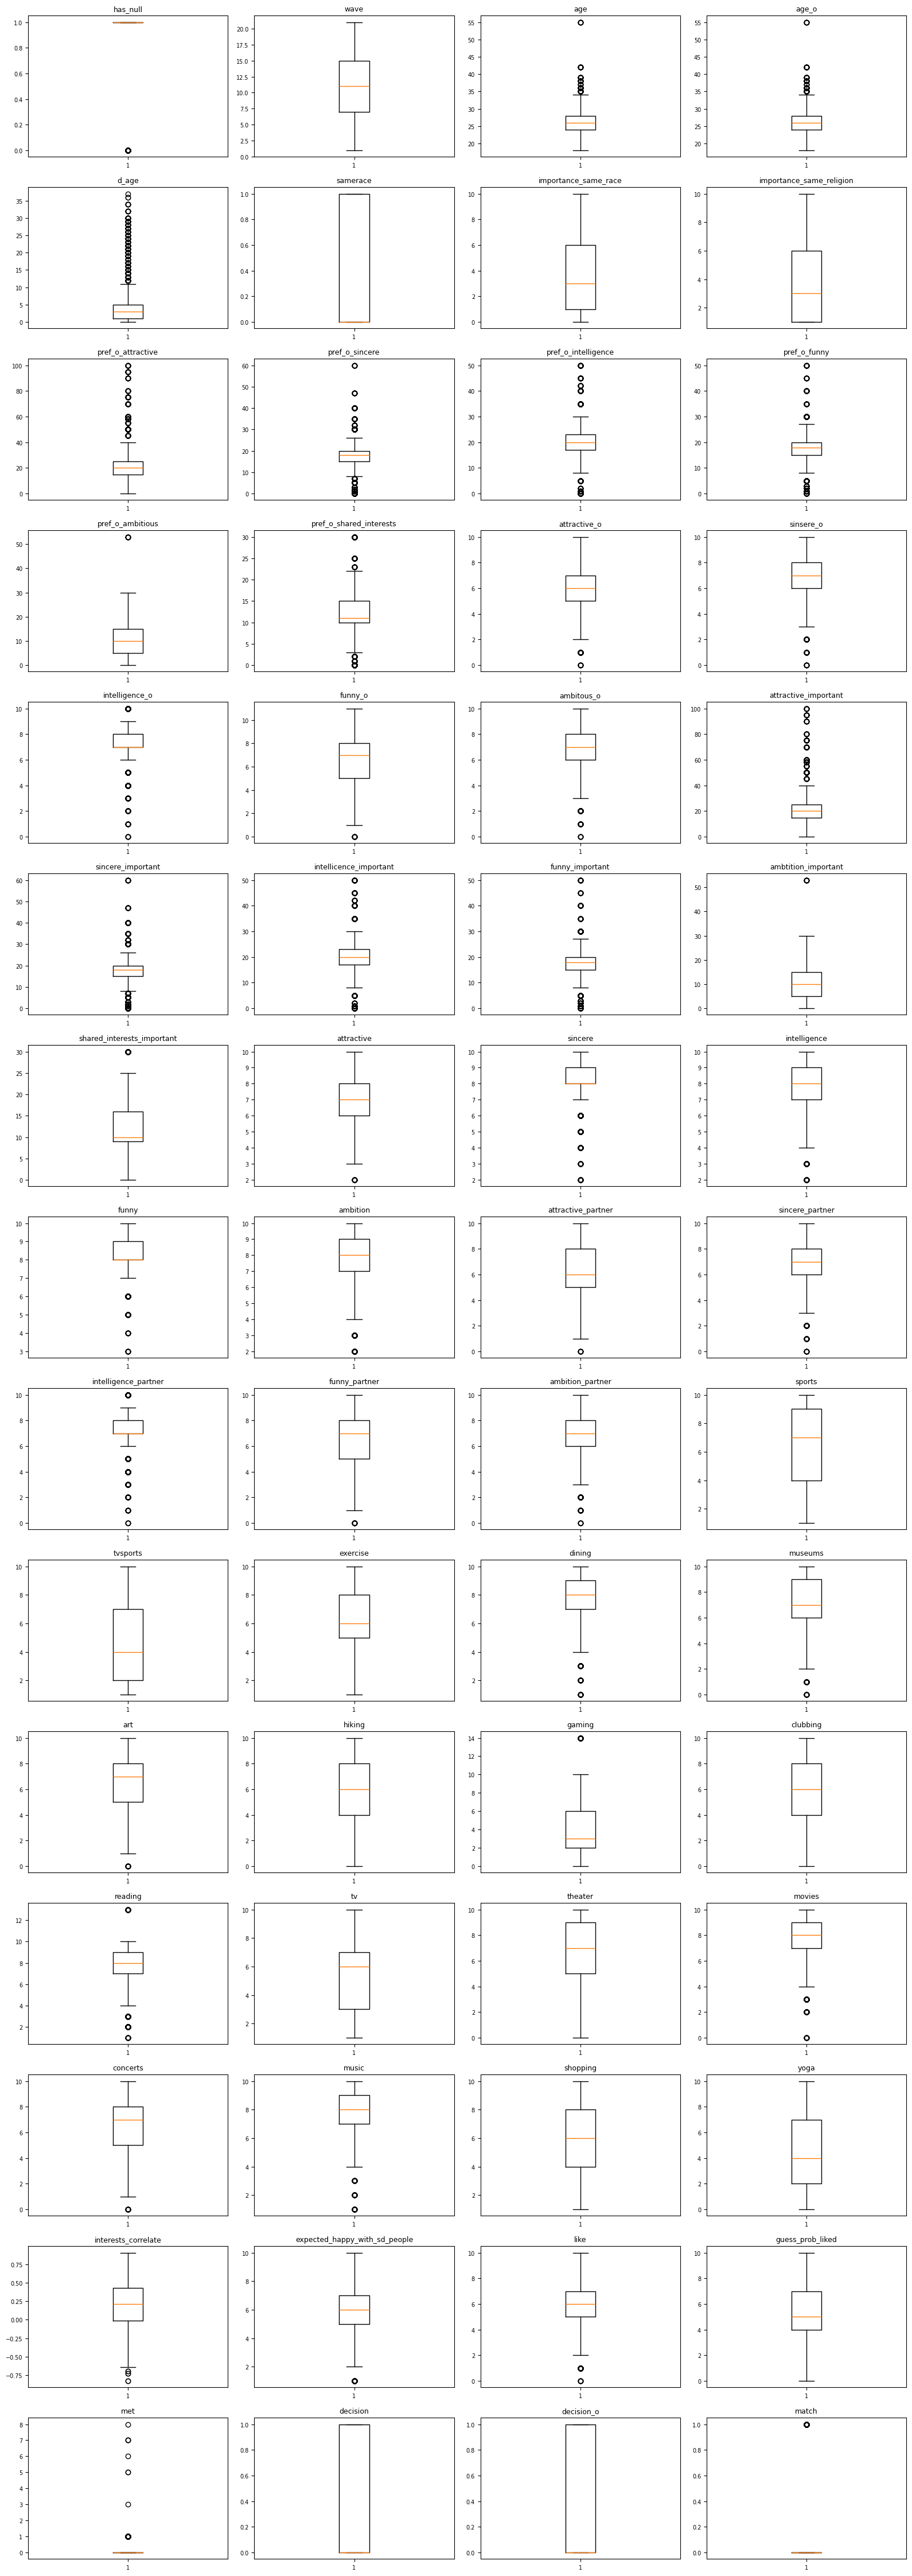

In [61]:
# построим бокспоты (ящики с усами) для всех числовых переменных для выявления экстримальных значений
n = len(num_cols)
ncols = 4
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    axes[i].boxplot(df_clean[col].dropna(), vert=True)
    axes[i].set_title(col, fontsize=9)
    axes[i].tick_params(labelsize=7)

# убрать пустые оси
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Заметим, что в опросе используются разные шкалы, поэтому числовые колонки напрямую несопоставимы по диапазону:

**Шкала 1–10** — самооценки, оценки партнёра, интересы и важность:
- самооценки: `attractive`, `sincere`, `intelligence`, `funny`, `ambition`;
- оценки партнёра: `attractive_o`, `sinsere_o`, `intelligence_o`, `funny_o`, `ambitous_o`;
- оценки, которые дал партнёр: `attractive_partner`, `sincere_partner`, `intelligence_partner`, `funny_partner`, `ambition_partner`;
- `like`, `guess_prob_liked`, `met`, `expected_happy_with_sd_people`;
- важность совпадения: `importance_same_race`, `importance_same_religion`;
- интересы/активности: `sports`, `tvsports`, `exercise`, `dining`, `museums`, `art`, `hiking`, `gaming`, `clubbing`, `reading`, `tv`, `theater`, `movies`, `concerts`, `music`, `shopping`, `yoga`.

**Шкала 0–100** — важность критериев при выборе партнёра (в сумме по блоку дают 100):
- предпочтения к партнёру: `pref_o_attractive`, `pref_o_sincere`, `pref_o_intelligence`, `pref_o_funny`, `pref_o_ambitious`, `pref_o_shared_interests`;
- важность при выборе: `attractive_important`, `sincere_important`, `intellicence_important`, `funny_important`, `ambtition_important`, `shared_interests_important`.

Отдельно стоят: возраст (`age`, `age_o`), разность возрастов (`d_age`), бинарные признаки (`has_null`, `samerace`, `decision`, `decision_o`, `match`), волна (`wave`, 1–5) и корреляция интересов (`interests_correlate`, −1…1).

In [62]:
# создадим ф-ю для расчёта жёстких выбросов 
def heavy_outliers_pct(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 3 * IQR
    upper_bound = Q3 + 3 * IQR
    mask = (df[column] < lower_bound) | (df[column] > upper_bound)
    return mask.sum() / df.shape[0] * 100

# считаем по всем числовым колонкам
outliers = pd.Series(
    {col: heavy_outliers_pct(df_clean, col) for col in num_cols}
).sort_values(ascending=False)

print(outliers.round(3))

match                            16.448
has_null                         12.628
met                               4.266
attractive_important              2.458
pref_o_attractive                 2.410
d_age                             1.928
sincere                           1.856
intelligence_o                    1.470
intelligence_partner              1.446
sincere_important                 1.193
pref_o_sincere                    1.157
pref_o_intelligence               1.121
intellicence_important            1.121
funny_important                   0.843
pref_o_funny                      0.831
age_o                             0.313
age                               0.313
funny                             0.229
movies                            0.217
ambtition_important               0.120
pref_o_ambitious                  0.096
hiking                            0.000
gaming                            0.000
clubbing                          0.000
reading                           0.000


In [63]:
cols_outliers = [
    "match",
    "has_null",
    "met",
    "attractive_important",
    "pref_o_attractive",
    "d_age",
    "sincere",
    "intelligence_o",
    "intelligence_partner",
    "sincere_important",
    "pref_o_sincere",
    "pref_o_intelligence",
    "intellicence_important",
]

,count,mean,std,min,25%,50%,75%,max
match,8299.0,0.164,0.371,0.0,0.0,0.0,0.0,1.0


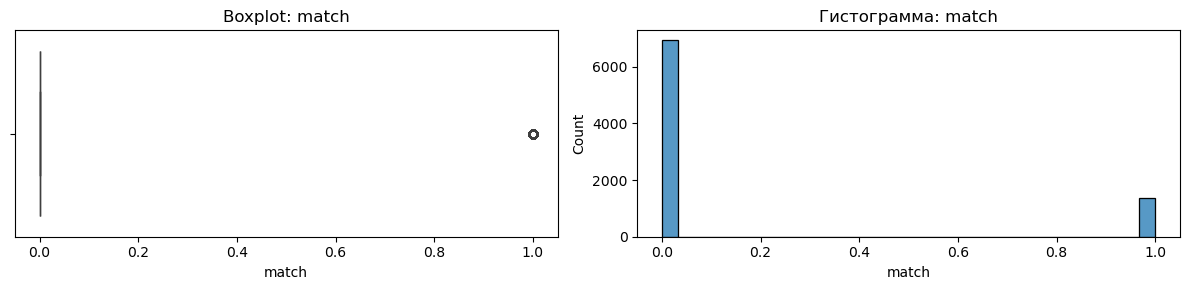

,count,mean,std,min,25%,50%,75%,max
has_null,8299.0,0.874,0.332,0.0,1.0,1.0,1.0,1.0


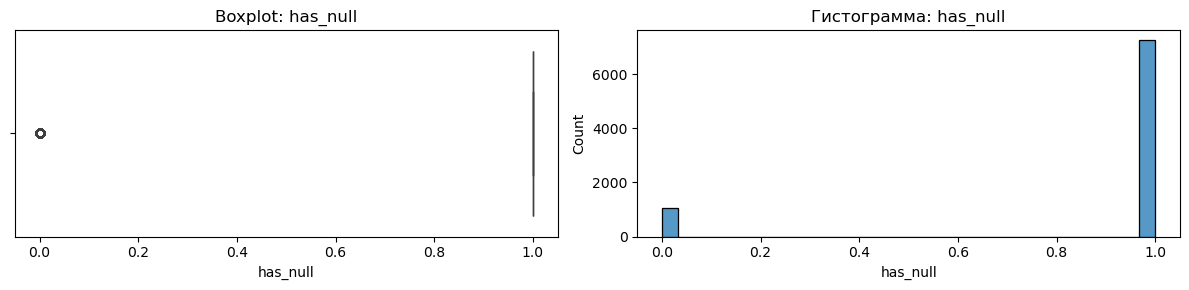

,count,mean,std,min,25%,50%,75%,max
met,8299.0,0.047,0.276,0.0,0.0,0.0,0.0,8.0


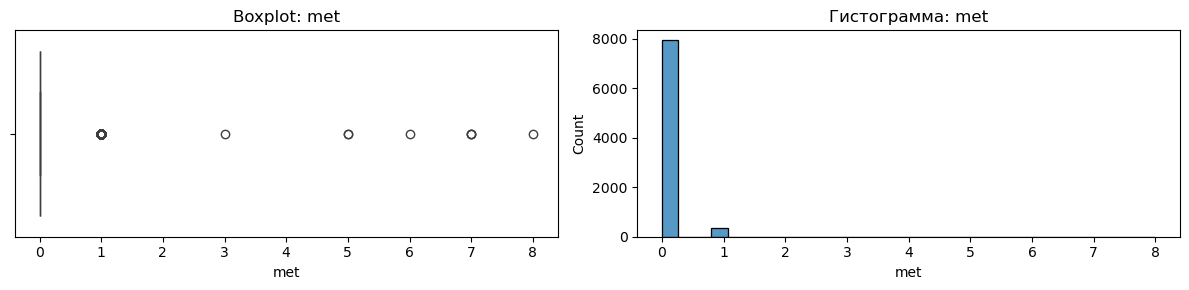

,count,mean,std,min,25%,50%,75%,max
attractive_important,8299.0,22.435,12.625,0.0,15.0,20.0,25.0,100.0


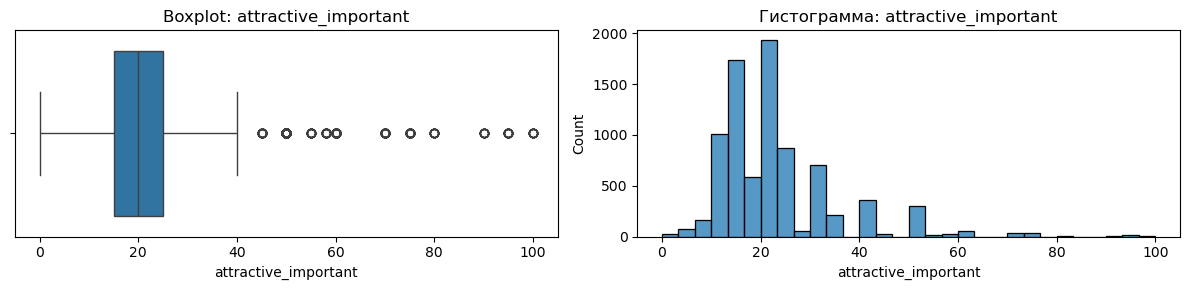

,count,mean,std,min,25%,50%,75%,max
pref_o_attractive,8299.0,22.364,12.537,0.0,15.0,20.0,25.0,100.0


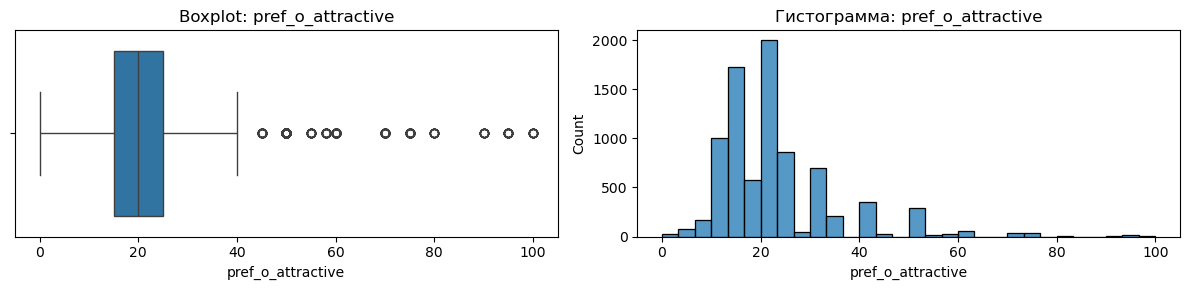

,count,mean,std,min,25%,50%,75%,max
d_age,8299.0,4.013,4.134,0.0,1.0,3.0,5.0,37.0


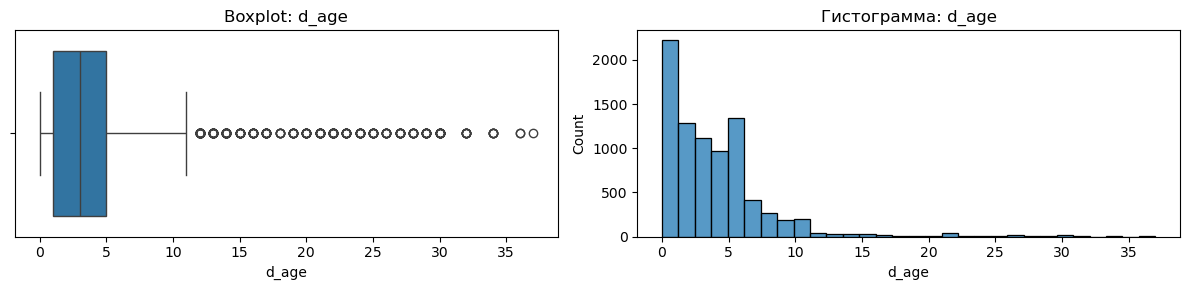

,count,mean,std,min,25%,50%,75%,max
sincere,8299.0,8.294,1.405,2.0,8.0,8.0,9.0,10.0


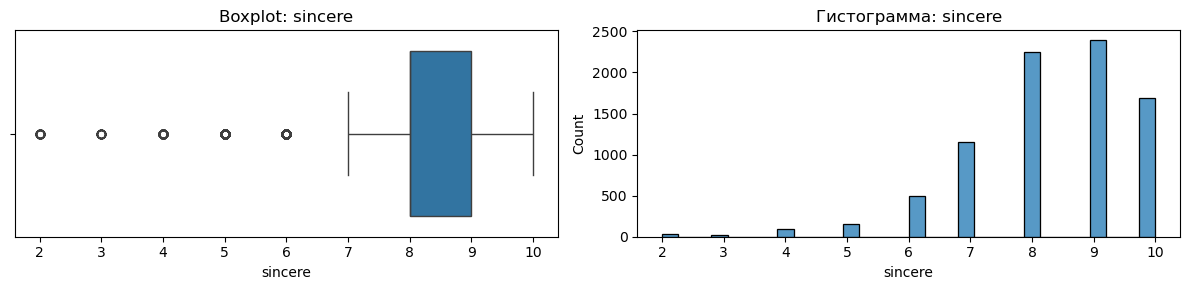

,count,mean,std,min,25%,50%,75%,max
intelligence_o,8299.0,7.355,1.526,0.0,7.0,7.0,8.0,10.0


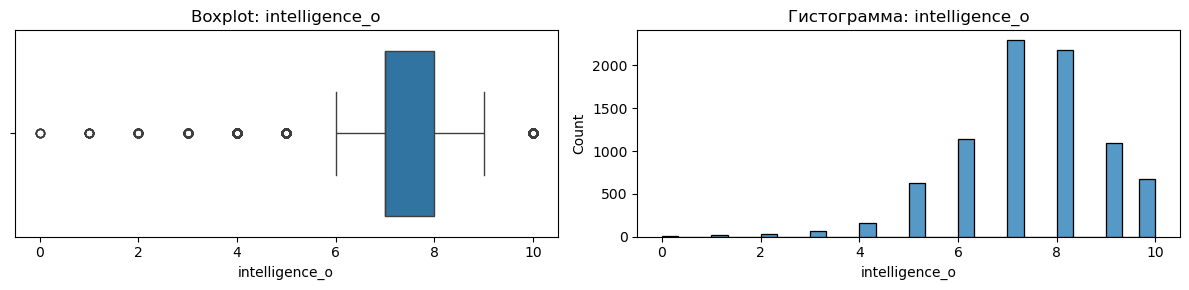

,count,mean,std,min,25%,50%,75%,max
intelligence_partner,8299.0,7.354,1.524,0.0,7.0,7.0,8.0,10.0


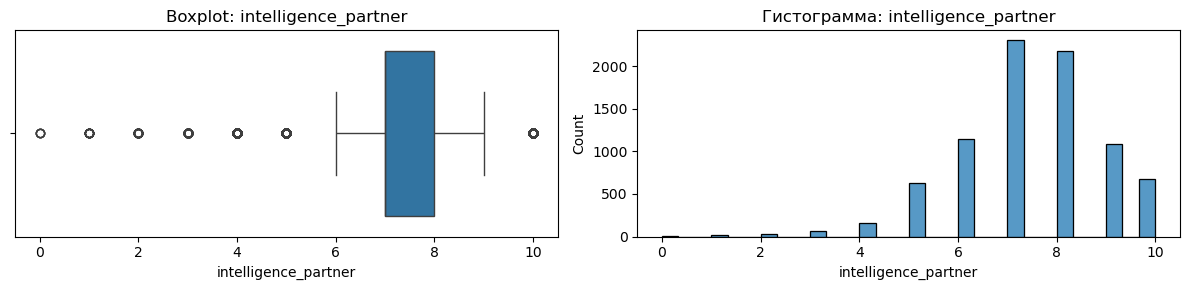

,count,mean,std,min,25%,50%,75%,max
sincere_important,8299.0,17.313,7.047,0.0,15.0,18.0,20.0,60.0


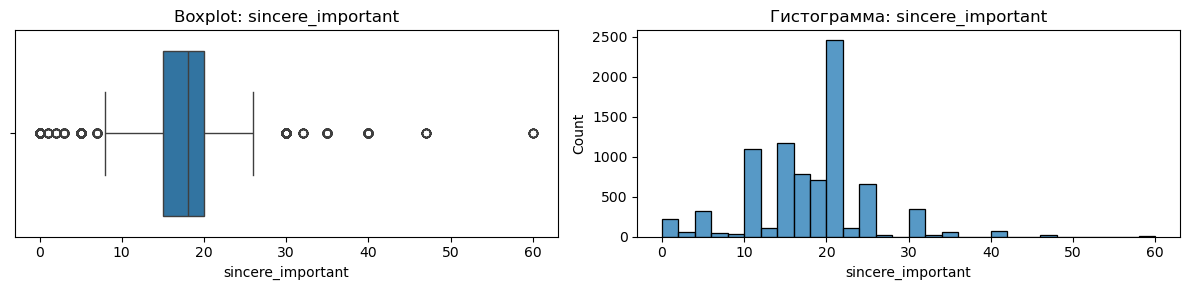

,count,mean,std,min,25%,50%,75%,max
pref_o_sincere,8299.0,17.321,6.98,0.0,15.0,18.0,20.0,60.0


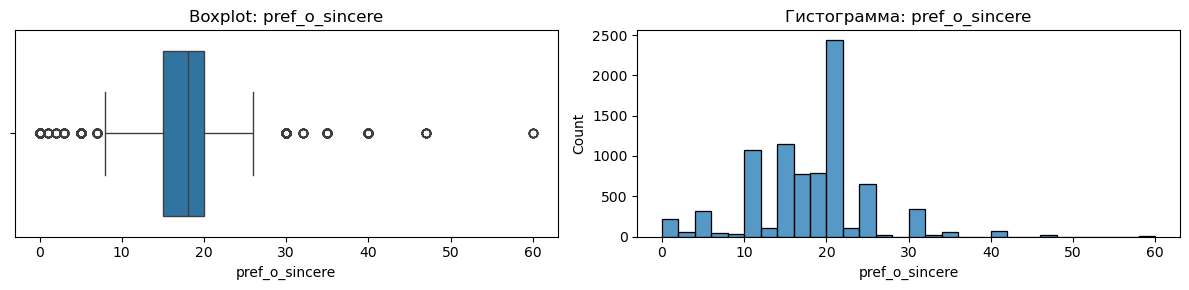

,count,mean,std,min,25%,50%,75%,max
pref_o_intelligence,8299.0,20.197,6.761,0.0,17.0,20.0,23.0,50.0


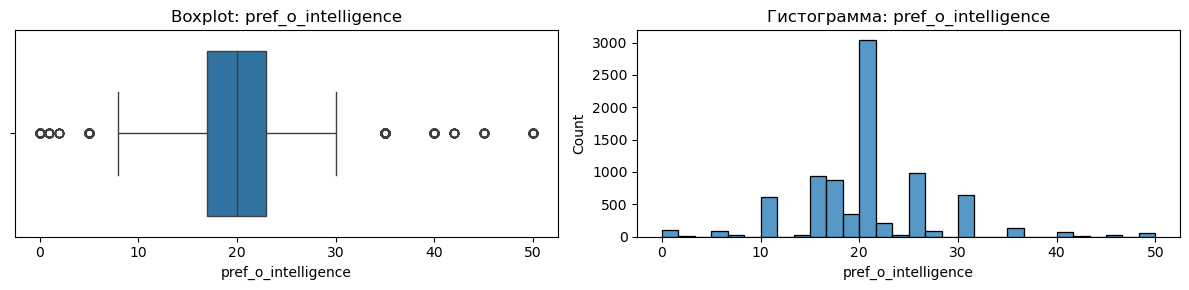

,count,mean,std,min,25%,50%,75%,max
intellicence_important,8299.0,20.185,6.796,0.0,17.0,20.0,23.0,50.0


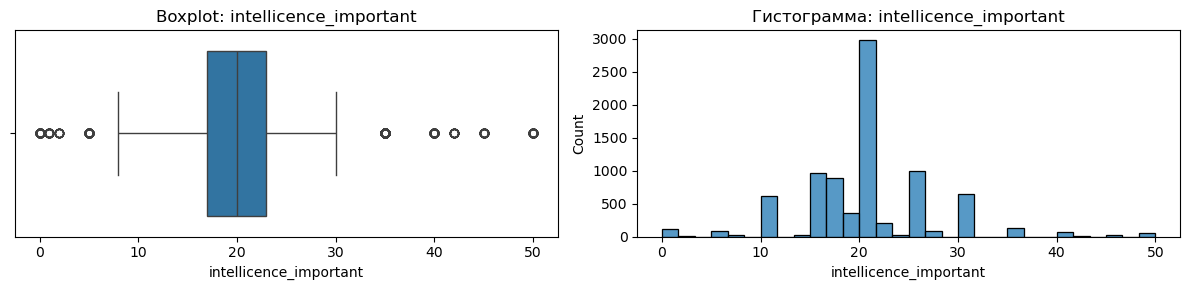

In [64]:
def heavy_outliers_desc(df, column):
    display(df[column].describe().to_frame().T.round(3))

    fig, axes = plt.subplots(1, 2, figsize=(12, 3))

    sns.boxplot(x=df[column], ax=axes[0])
    axes[0].set_title(f"Boxplot: {column}")

    sns.histplot(df[column].dropna(), bins=30, kde=False, ax=axes[1])
    axes[1].set_title(f"Гистограмма: {column}")

    plt.tight_layout()
    plt.show()


for col in cols_outliers:
    heavy_outliers_desc(df_clean, col)

По результатам анализа числовых колонок все значения находятся в пределах заданных шкал, аномалий не выявлено. Экстремальные значения также не выходят за границы шкал и представляют собой реальные, но относительно редкие ответы респондентов, поэтому данные оставлены без изменений.

In [65]:
# для категориальных признаков сделаем сводную таблицу
summary = pd.DataFrame({
    "n_unique": [df_clean[c].nunique() for c in cat_cols],
    "n_nan": [df_clean[c].isna().sum() for c in cat_cols],
    "examples": [df_clean[c].dropna().unique()[:5].tolist() for c in cat_cols],
}, index=cat_cols)

display(summary.sort_values("n_unique", ascending=False))

,n_unique,n_nan,examples
field,218,0,"[law, economics, 'masters in public administra..."
race,5,0,"['asian/pacific islander/asian-american', euro..."
race_o,5,0,"[european/caucasian-american, 'asian/pacific i..."
d_d_age,4,0,"[[4-6], [0-1], [2-3], [7-37]]"
d_ambition,3,0,"[[6-8], [0-5], [9-10]]"
d_dining,3,0,"[[9-10], [6-8], [0-5]]"
d_gaming,3,0,"[[0-5], [6-8], [9-10]]"
d_hiking,3,0,"[[0-5], [6-8], [9-10]]"
d_art,3,0,"[[0-5], [6-8], [9-10]]"
d_museums,3,0,"[[0-5], [6-8], [9-10]]"


In [66]:
df_clean['field'].unique() # рассмотрим самую многочисленную группу

array(['law', 'economics', "'masters in public administration'",
       "'masters of social work&education'", 'finance', 'business',
       "'political science'", 'money', "'operations research'",
       "'tc [health ed]'", 'psychology', "'social work'",
       "'speech language pathology'", "'educational psychology'",
       "'applied maths/econs'", 'mathematics', 'statistics',
       "'organizational psychology'", "'mechanical engineering'",
       'finanace', 'finance&economics', "'undergrad - gs'",
       "'mathematical finance'", 'medicine', 'mba', "'german literature'",
       "'business & international affairs'", "'mfa creative writing'",
       'engineering', "'electrical engineering'", 'classics',
       "'operations research [seas]'", 'chemistry', 'journalism',
       "'elementary/childhood education [ma]'", 'microbiology',
       "'masters of social work'", 'communications', 'marketing',
       "'international educational development'",
       "'education administration'", "

In [67]:
df_clean[df_clean['field'] == "'masters in public administration'"].head(5)

,has_null,wave,gender,age,age_o,d_age,d_d_age,race,race_o,samerace,importance_same_race,importance_same_religion,d_importance_same_race,d_importance_same_religion,field,pref_o_attractive,pref_o_sincere,pref_o_intelligence,pref_o_funny,pref_o_ambitious,pref_o_shared_interests,d_pref_o_attractive,d_pref_o_sincere,d_pref_o_intelligence,d_pref_o_funny,d_pref_o_ambitious,d_pref_o_shared_interests,attractive_o,sinsere_o,intelligence_o,funny_o,ambitous_o,d_attractive_o,d_sinsere_o,d_intelligence_o,d_funny_o,d_ambitous_o,d_shared_interests_o,attractive_important,sincere_important,intellicence_important,funny_important,ambtition_important,shared_interests_important,d_attractive_important,d_sincere_important,d_intellicence_important,d_funny_important,d_ambtition_important,d_shared_interests_important,attractive,sincere,intelligence,funny,ambition,d_attractive,d_sincere,d_intelligence,d_funny,d_ambition,attractive_partner,sincere_partner,intelligence_partner,funny_partner,ambition_partner,d_attractive_partner,d_sincere_partner,d_intelligence_partner,d_funny_partner,d_ambition_partner,d_shared_interests_partner,sports,tvsports,exercise,dining,museums,art,hiking,gaming,clubbing,reading,tv,theater,movies,concerts,music,shopping,yoga,d_sports,d_tvsports,d_exercise,d_dining,d_museums,d_art,d_hiking,d_gaming,d_clubbing,d_reading,d_tv,d_theater,d_movies,d_concerts,d_music,d_shopping,d_yoga,interests_correlate,d_interests_correlate,expected_happy_with_sd_people,d_expected_happy_with_sd_people,d_expected_num_interested_in_me,d_expected_num_matches,like,guess_prob_liked,d_like,d_guess_prob_liked,met,decision,decision_o,match
70,1,1,female,25,27,2,[2-3],european/caucasian-american,european/caucasian-american,1,1,1,[0-1],[0-1],'masters in public administration',35,20,20,20,0,5,[21-100],[16-20],[16-20],[16-20],[0-15],[0-15],8,7,6,6,6,[6-8],[6-8],[6-8],[6-8],[6-8],[0-5],9,18,27,18,18,9,[0-15],[16-20],[21-100],[16-20],[16-20],[0-15],7,4,8,8,8,[6-8],[0-5],[6-8],[6-8],[6-8],5,8,7,4,7,[0-5],[6-8],[6-8],[0-5],[6-8],[0-5],2,2,1,10,9,9,3,2,10,8,10,9,9,6,6,8,6,[0-5],[0-5],[0-5],[9-10],[9-10],[9-10],[0-5],[0-5],[9-10],[6-8],[9-10],[9-10],[9-10],[6-8],[6-8],[6-8],[6-8],-0.03,[-1-0],6,[5-6],[10-20],[0-2],4,5,[0-5],[5-6],0,1,0,0
71,1,1,female,25,22,3,[2-3],european/caucasian-american,european/caucasian-american,1,1,1,[0-1],[0-1],'masters in public administration',60,0,0,40,0,0,[21-100],[0-15],[0-15],[21-100],[0-15],[0-15],8,8,10,7,6,[6-8],[6-8],[9-10],[6-8],[6-8],[0-5],9,18,27,18,18,9,[0-15],[16-20],[21-100],[16-20],[16-20],[0-15],7,4,8,8,8,[6-8],[0-5],[6-8],[6-8],[6-8],8,7,7,9,6,[6-8],[6-8],[6-8],[9-10],[6-8],[6-8],2,2,1,10,9,9,3,2,10,8,10,9,9,6,6,8,6,[0-5],[0-5],[0-5],[9-10],[9-10],[9-10],[0-5],[0-5],[9-10],[6-8],[9-10],[9-10],[9-10],[6-8],[6-8],[6-8],[6-8],-0.11,[-1-0],6,[5-6],[10-20],[0-2],8,7,[6-8],[7-10],0,1,1,1
72,1,1,female,25,22,3,[2-3],european/caucasian-american,'asian/pacific islander/asian-american',0,1,1,[0-1],[0-1],'masters in public administration',19,18,19,18,14,12,[16-20],[16-20],[16-20],[16-20],[0-15],[0-15],10,10,10,10,10,[9-10],[9-10],[9-10],[9-10],[9-10],[9-10],9,18,27,18,18,9,[0-15],[16-20],[21-100],[16-20],[16-20],[0-15],7,4,8,8,8,[6-8],[0-5],[6-8],[6-8],[6-8],5,8,8,6,7,[0-5],[6-8],[6-8],[6-8],[6-8],[6-8],2,2,1,10,9,9,3,2,10,8,10,9,9,6,6,8,6,[0-5],[0-5],[0-5],[9-10],[9-10],[9-10],[0-5],[0-5],[9-10],[6-8],[9-10],[9-10],[9-10],[6-8],[6-8],[6-8],[6-8],0.42,[0.33-1],6,[5-6],[10-20],[0-2],5,5,[0-5],[5-6],0,1,1,1
73,1,1,female,25,23,2,[2-3],european/caucasian-american,european/caucasian-american,1,1,1,[0-1],[0-1],'masters in public administration',30,5,15,40,5,5,[21-100],[0-15],[0-15],[21-100],[0-15],[0-15],8,8,8,8,8,[6-8],[6-8],[6-8],[6-8],[6-8],[6-8],9,18,27,18,18,9,[0-15],[16-20],[21-100],[16-20],[16-20],[0-15],7,4,8,8,8,[6-8],[0-5],[6-8],[6-8],[6-8],8,6,5,6,6,[6-8],[6-8],[0-5],[6-8],[6-8],[0-5],2,2,1,10,9,9,3,2,10,8,10,9,9,6,6,8,6,[0-5],[0-5],[0-5],[9-10],[9-10],[9-10],[0-5],[0-5],[9-10],[6-8],[9-10],[9-10],[9-10],[6-8],[6-8],[6-8],[6-8],-0.

В колонке специальности (field) выявлены двойные ковычки в некоторых местах - уберём их.

In [68]:
df_clean["field"] = df_clean["field"].str.strip("'")

In [69]:
df_clean['field'].unique()

array(['law', 'economics', 'masters in public administration',
       'masters of social work&education', 'finance', 'business',
       'political science', 'money', 'operations research',
       'tc [health ed]', 'psychology', 'social work',
       'speech language pathology', 'educational psychology',
       'applied maths/econs', 'mathematics', 'statistics',
       'organizational psychology', 'mechanical engineering', 'finanace',
       'finance&economics', 'undergrad - gs', 'mathematical finance',
       'medicine', 'mba', 'german literature',
       'business & international affairs', 'mfa creative writing',
       'engineering', 'electrical engineering', 'classics',
       'operations research [seas]', 'chemistry', 'journalism',
       'elementary/childhood education [ma]', 'microbiology',
       'masters of social work', 'communications', 'marketing',
       'international educational development',
       'education administration', 'business [mba]', 'computer science',
       

In [70]:
# Создадим колонку с укрупнёнными направлениями


def map_field_to_group(field):
    if pd.isna(field):
        return "unknown"
    f = field.lower()

    # 1. Бизнес / финансы / экономика (проверяем раньше "international")
    if re.search(r"business|mba|finance|finanace|econ|money|marketing|management", f):
        return "business_finance_economics"
    # 2. Медицина / здоровье (раньше общих "science")
    if re.search(r"medicine|health|biomedical|microbiology|pathology|nursing|epidemiolog|physiolog|nutrition", f):
        return "medicine_health"
    # 3. Естественные науки (новое!)
    if re.search(r"biology|chemistry|physics|ecology|genetic|neuroscience|biochem|climate|environment|marine|geophys|conservation|science", f):
        return "natural_sciences"
    # 4. IT / инженерия / математика / статистика
    if re.search(r"computer|engineering|math|statistic|operations research|financial math|applied maths", f):
        return "stem_engineering_math"
    # 5. Образование (до humanities, чтобы "art education" → education)
    if re.search(r"education|teaching|childhood|tesol|curriculum", f):
        return "education"
    # 6. Социальные науки / психология / право / политика
    if re.search(r"psychology|social work|sociology|political science|law|public administration|international|anthropology|human rights|urban planning", f):
        return "social_sciences_law"
    # 7. Гуманитарные / искусства / языки
    if re.search(r"literature|german|polish|english|classics|philosophy|religion|history|art|film|journalism|communications|creative writing|mfa|theater|theatre|writing|japanese|french|american studies", f):
        return "humanities_arts"
    return "other"

df_clean["field_group"] = df_clean["field"].apply(map_field_to_group)

# проверка
print(df_clean["field_group"].value_counts(dropna=False))

field_group
social_sciences_law           2229
business_finance_economics    1933
natural_sciences               937
humanities_arts                852
stem_engineering_math          794
education                      613
medicine_health                546
other                          395
Name: count, dtype: int64


In [71]:
cat_cols.append('field_group')
cat_cols

['gender',
 'd_d_age',
 'race',
 'race_o',
 'd_importance_same_race',
 'd_importance_same_religion',
 'field',
 'd_pref_o_attractive',
 'd_pref_o_sincere',
 'd_pref_o_intelligence',
 'd_pref_o_funny',
 'd_pref_o_ambitious',
 'd_pref_o_shared_interests',
 'd_attractive_o',
 'd_sinsere_o',
 'd_intelligence_o',
 'd_funny_o',
 'd_ambitous_o',
 'd_shared_interests_o',
 'd_attractive_important',
 'd_sincere_important',
 'd_intellicence_important',
 'd_funny_important',
 'd_ambtition_important',
 'd_shared_interests_important',
 'd_attractive',
 'd_sincere',
 'd_intelligence',
 'd_funny',
 'd_ambition',
 'd_attractive_partner',
 'd_sincere_partner',
 'd_intelligence_partner',
 'd_funny_partner',
 'd_ambition_partner',
 'd_shared_interests_partner',
 'd_sports',
 'd_tvsports',
 'd_exercise',
 'd_dining',
 'd_museums',
 'd_art',
 'd_hiking',
 'd_gaming',
 'd_clubbing',
 'd_reading',
 'd_tv',
 'd_theater',
 'd_movies',
 'd_concerts',
 'd_music',
 'd_shopping',
 'd_yoga',
 'd_interests_correlate'

In [72]:
df_clean['field_group'].describe(include='all')

count                    8299
unique                      8
top       social_sciences_law
freq                     2229
Name: field_group, dtype: object

In [73]:
df_clean['race'].unique()

array(["'asian/pacific islander/asian-american'",
       'european/caucasian-american', 'other',
       "'latino/hispanic american'", "'black/african american'"],
      dtype=object)

In [74]:
df_clean['race_o'].unique()

array(['european/caucasian-american',
       "'asian/pacific islander/asian-american'",
       "'latino/hispanic american'", 'other', "'black/african american'"],
      dtype=object)

In [75]:
# Аналогично уберём дыойные ковычки в колонках с расами
df_clean["race"] = df_clean["race"].str.strip("'")
df_clean["race_o"] = df_clean["race_o"].str.strip("'")

In [76]:
df_clean['race'].unique()

array(['asian/pacific islander/asian-american',
       'european/caucasian-american', 'other', 'latino/hispanic american',
       'black/african american'], dtype=object)

In [77]:
df_clean['race_o'].unique()

array(['european/caucasian-american',
       'asian/pacific islander/asian-american',
       'latino/hispanic american', 'other', 'black/african american'],
      dtype=object)

Категориальные признаки представлены в основном разностными d_* колонками с упорядоченными диапазонами (обычно 3 группы: 0–5 / 6–8 / 9–10 либо 0–15 / 16–20 / 21–100), а также демографическими (gender, race, race_o) и field. Лишние одинарные кавычки в значениях field, race, race_o удалены; в остальных колонках аномалий не выявлено — все значения соответствуют ожидаемым категориям и диапазонам. Дополнительно на основе field создана колонка field_group с укрупнёнными группами специальностей для дальнейшего анализа.

**Вывод:** В числовых колонках все значения находятся в пределах заданных шкал, аномалий не выявлено. Экстремальные значения также не выходят за границы шкал и представляют собой реальные, но относительно редкие ответы респондентов, поэтому данные оставлены без изменений. В категориальных переменных значения соответствуют ожидаемым категориям и диапазонам; лишние одинарные кавычки в `field`, `race`, `race_o` удалены, а на основе `field` создана колонка `field_group` с укрупнёнными группами специальностей. Таким образом, явных аномалий в данных не обнаружено, и дополнительная фильтрация выбросов не требуется.

## Анализ данных

### Распределение параметров

In [78]:
# построим распределения параметров
# Числовые: гистограмма + KDE
def plot_numeric_distributions(df, cols, ncols=4, bins=30):
    n = len(cols)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows))
    axes = axes.flatten()

    for i, col in enumerate(cols):
        sns.histplot(df[col].dropna(), bins=bins, kde=True, ax=axes[i])
        axes[i].set_title(col, fontsize=9)
        axes[i].set_xlabel("")
        axes[i].tick_params(labelsize=7)

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()


# Категориальные: барчарт
def plot_categorical_distributions(df, cols, ncols=3, top_n=10):
    n = len(cols)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3 * nrows))
    axes = axes.flatten()

    for i, col in enumerate(cols):
        vc = df[col].value_counts(dropna=False).head(top_n)
        sns.barplot(x=vc.values, y=vc.index.astype(str), ax=axes[i], orient="h")
        axes[i].set_title(col, fontsize=9)
        axes[i].set_xlabel("count")
        axes[i].tick_params(labelsize=7)

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()


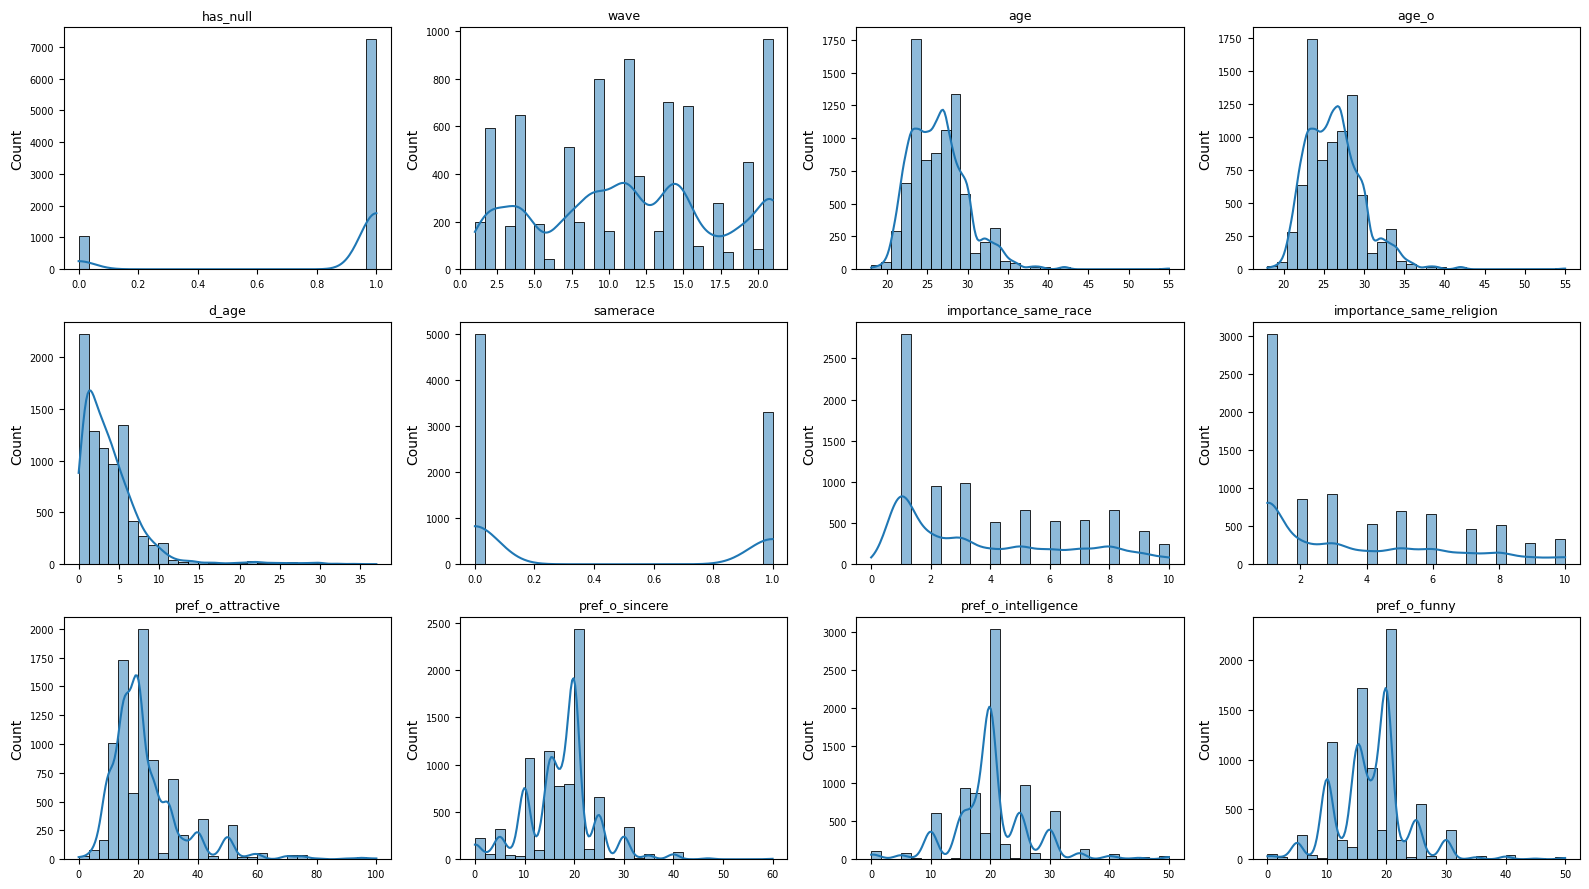

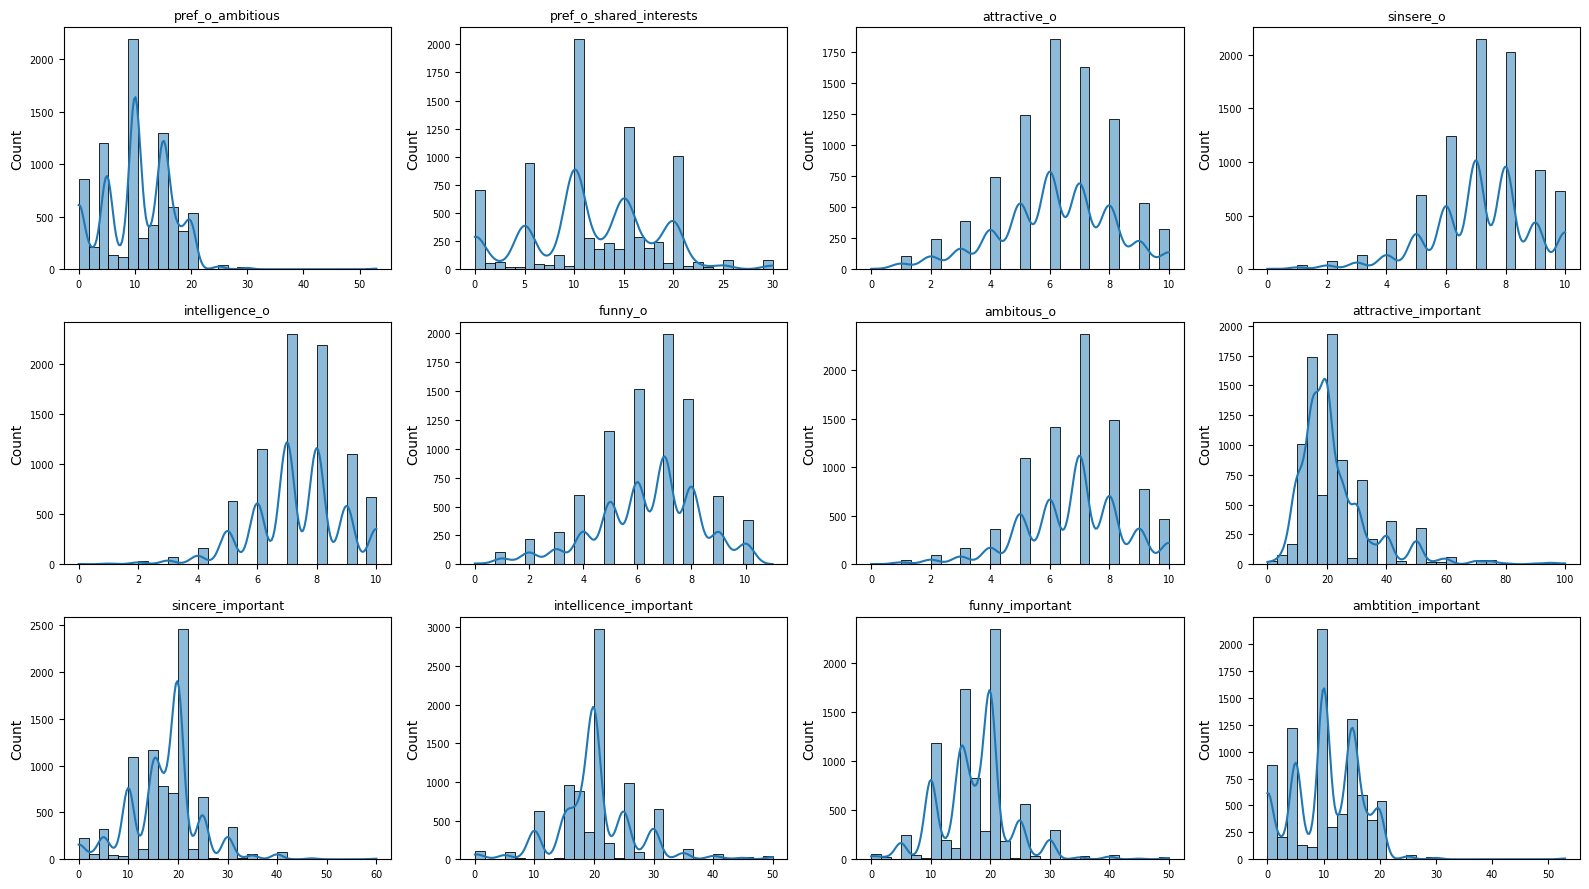

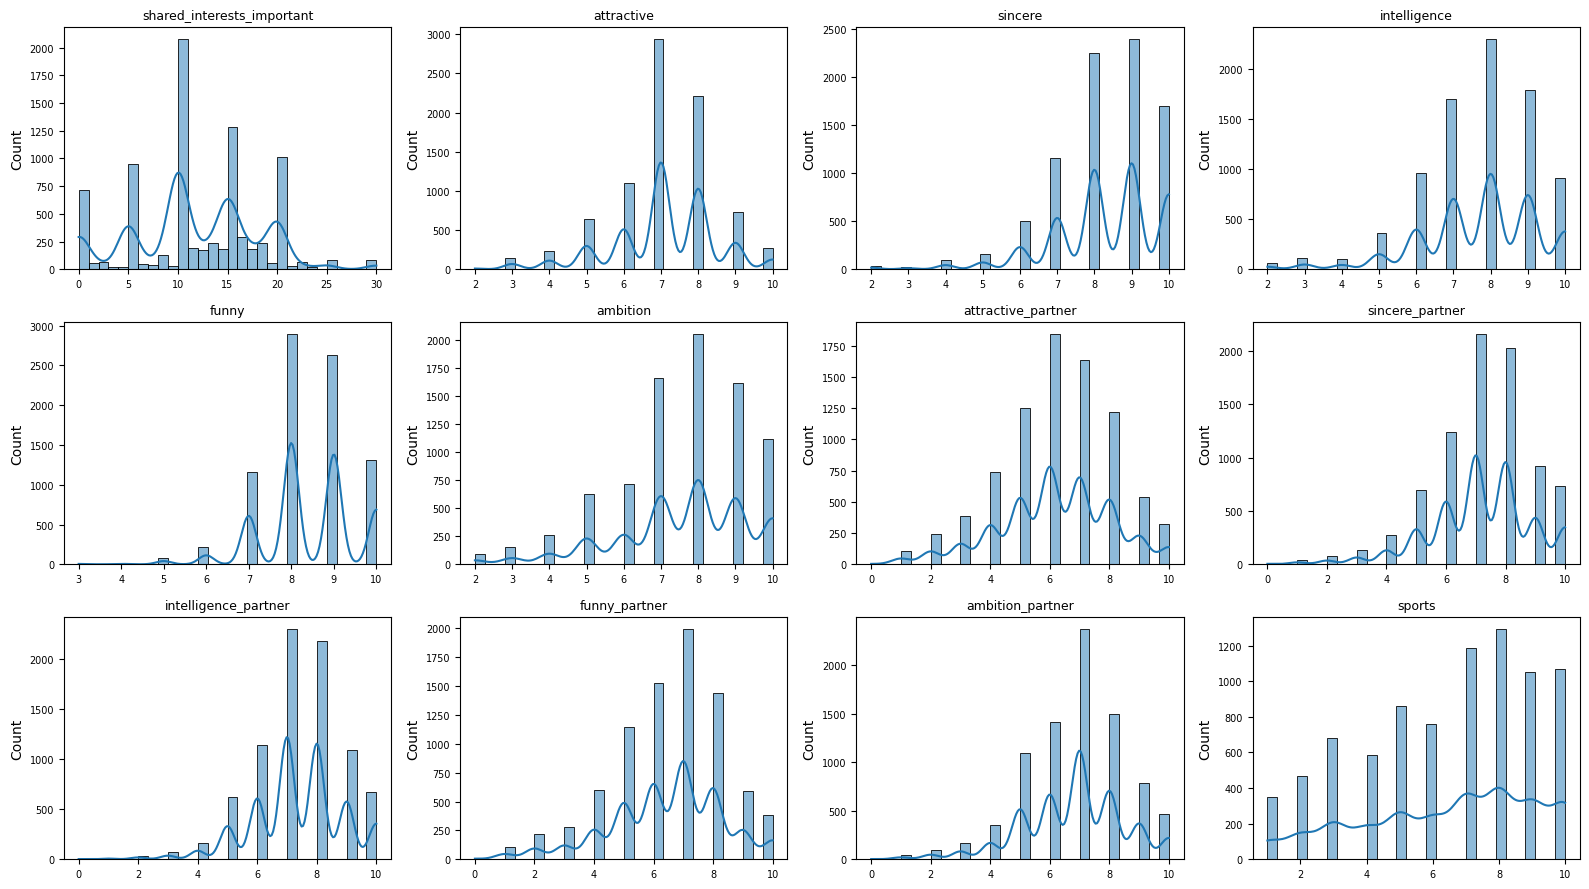

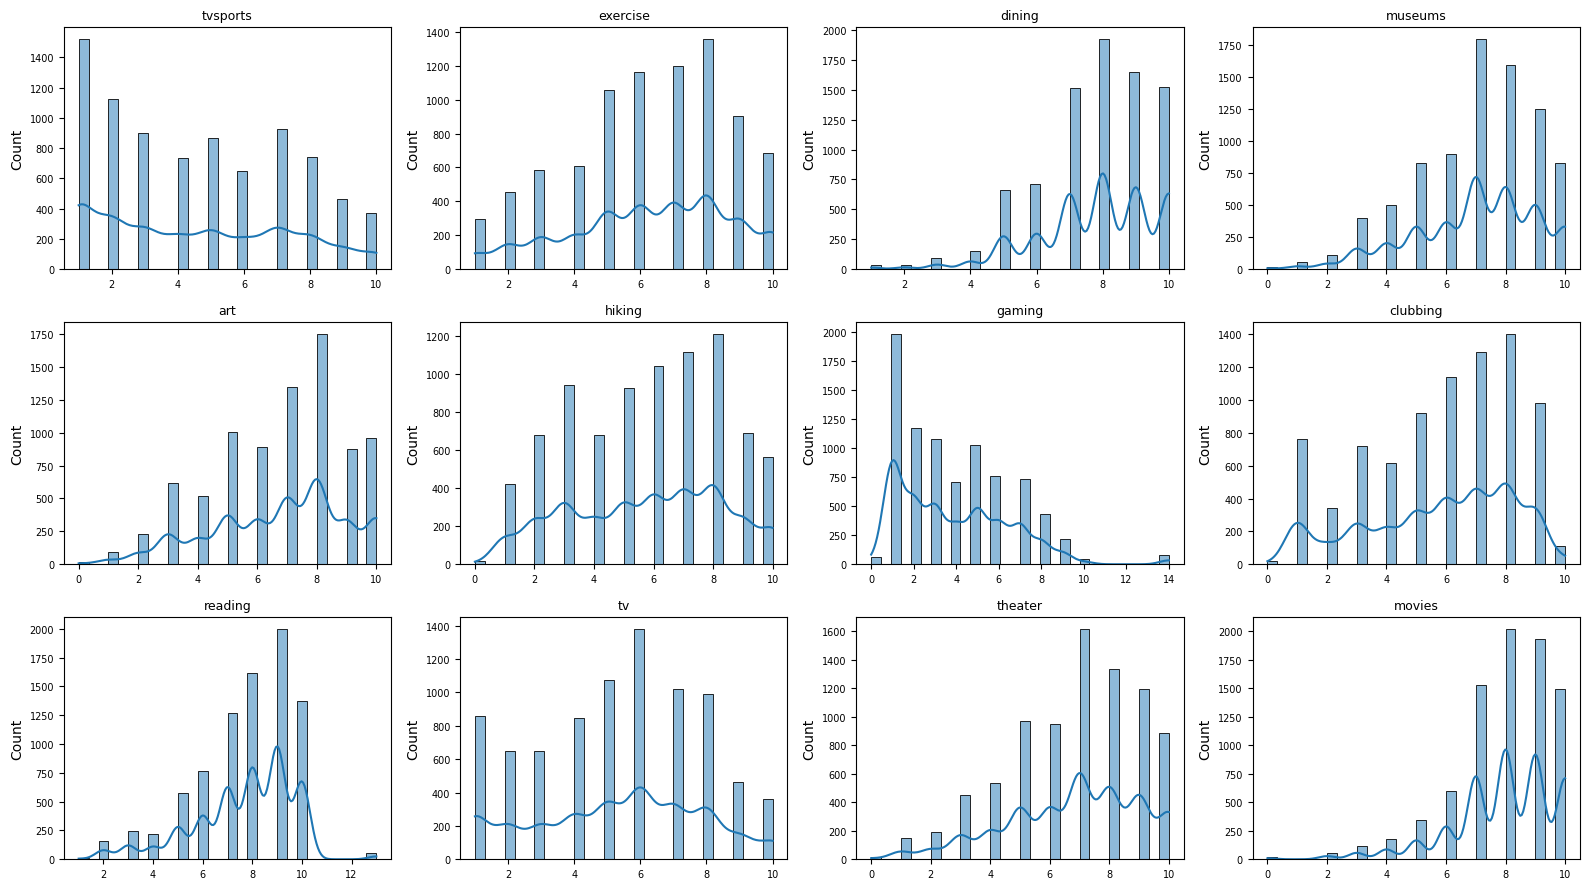

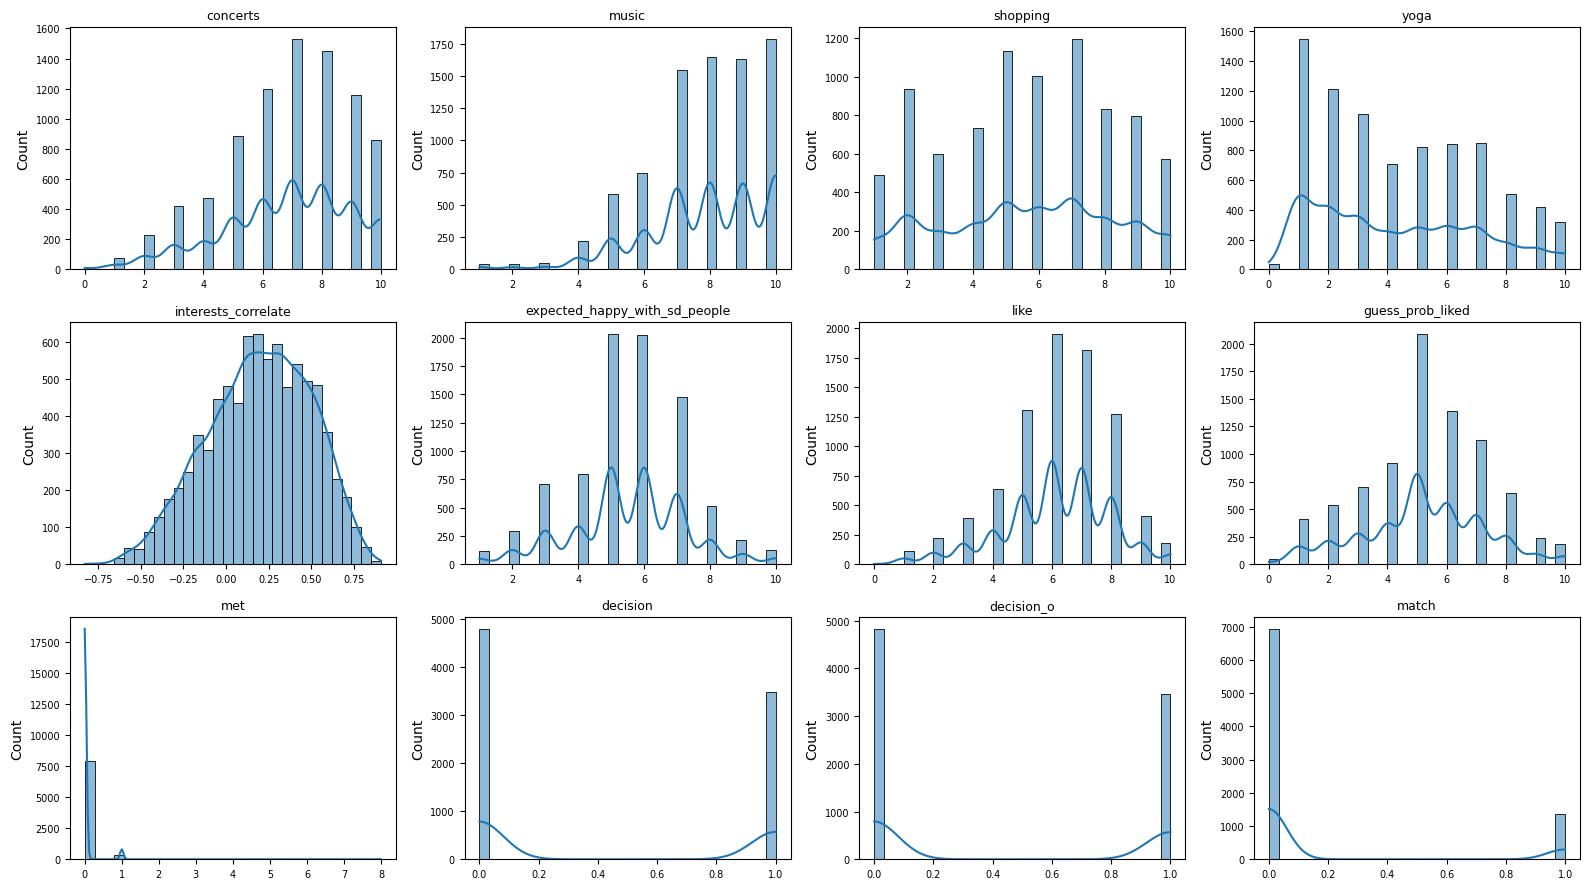

In [79]:
# числовые — порциями по 12, чтобы графики не были мелкими
for k in range(0, len(num_cols), 12):
    plot_numeric_distributions(df_clean, num_cols[k:k + 12])

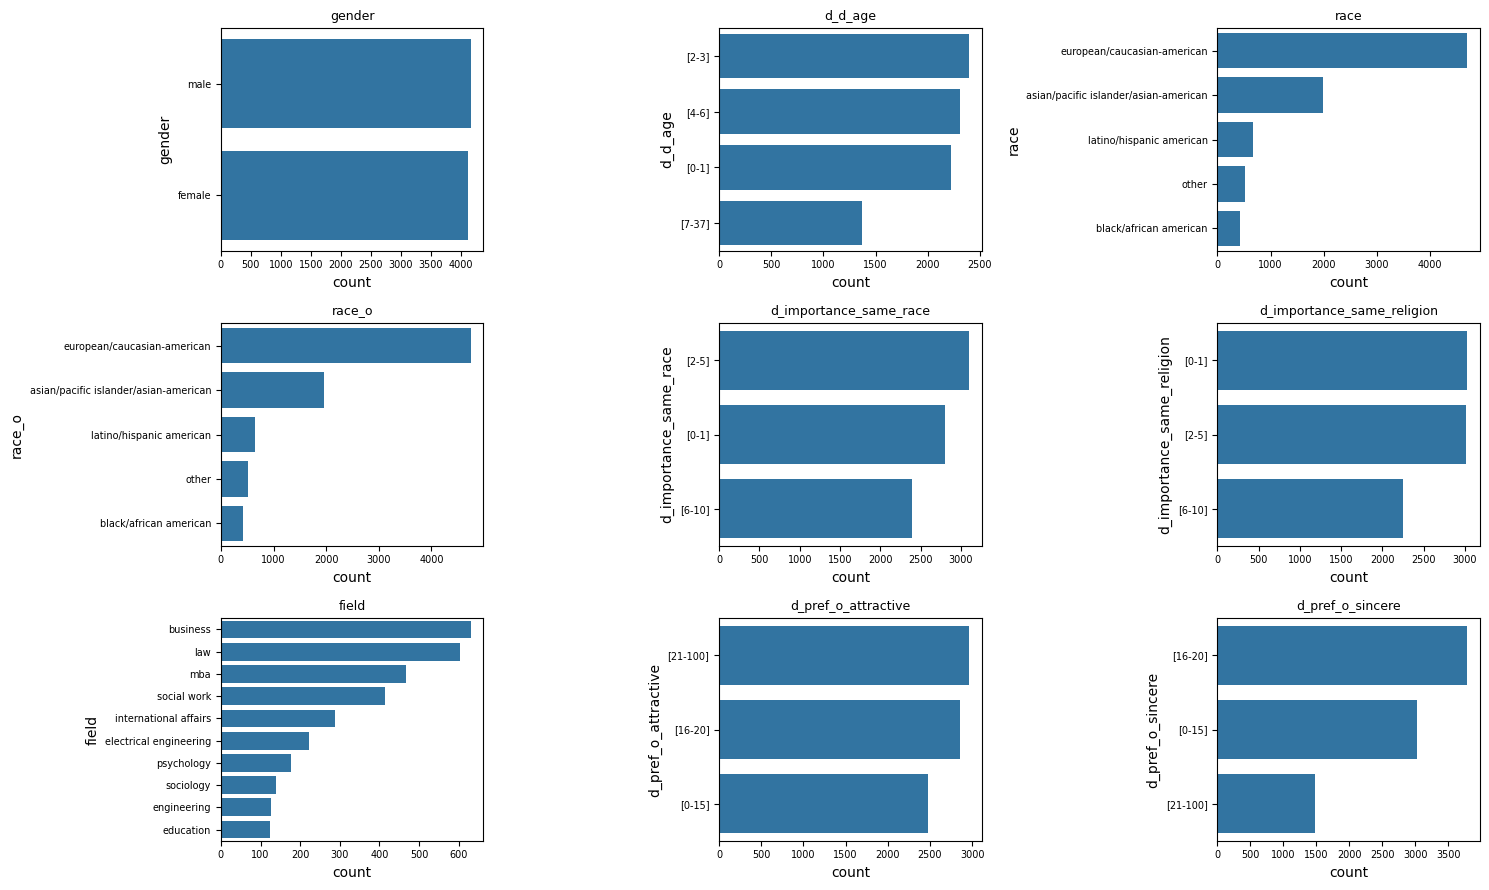

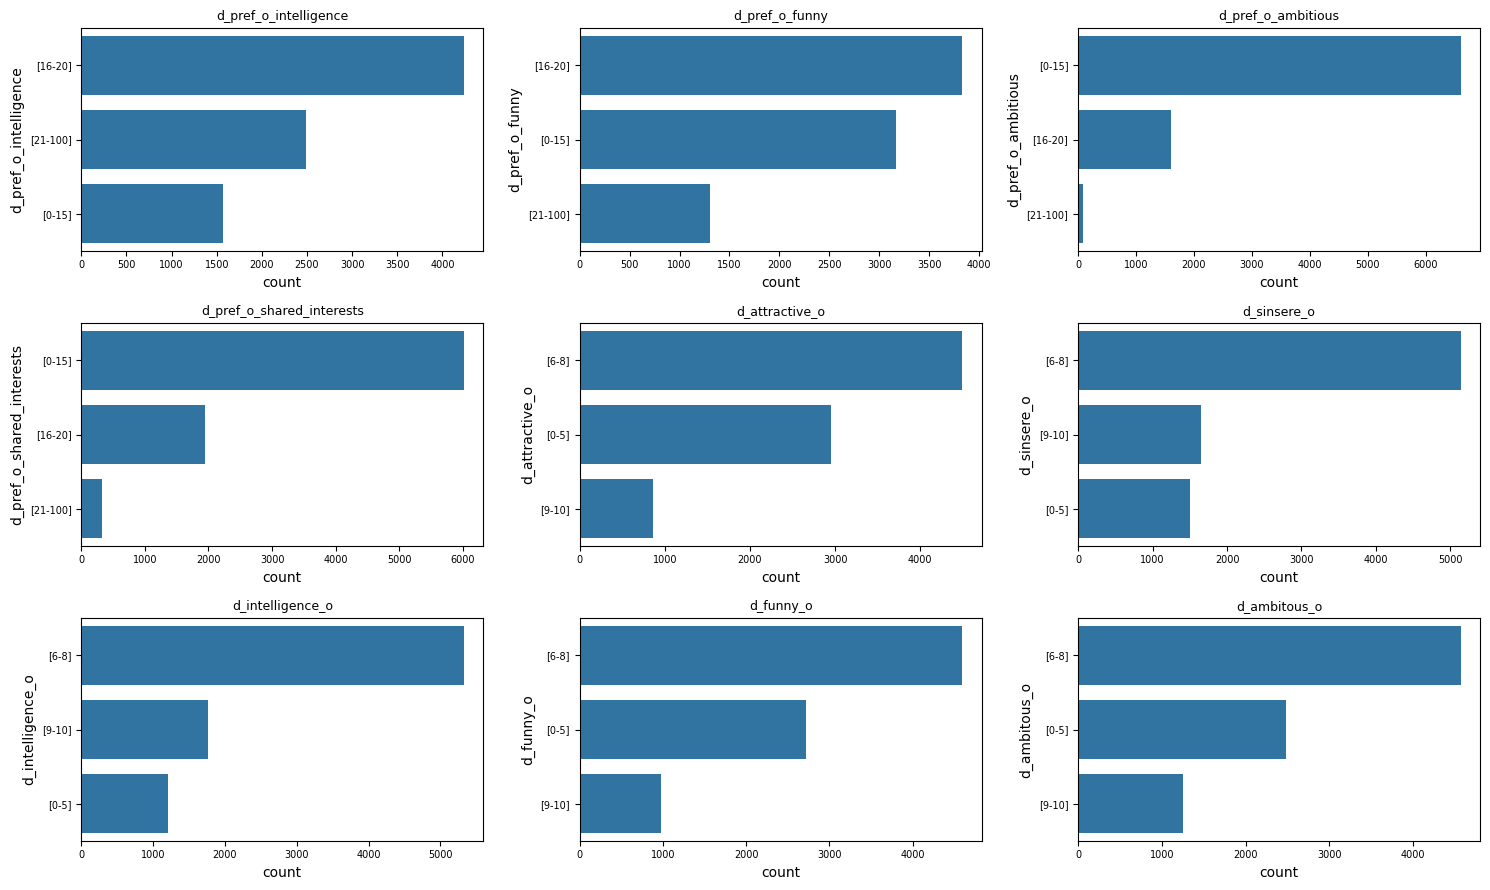

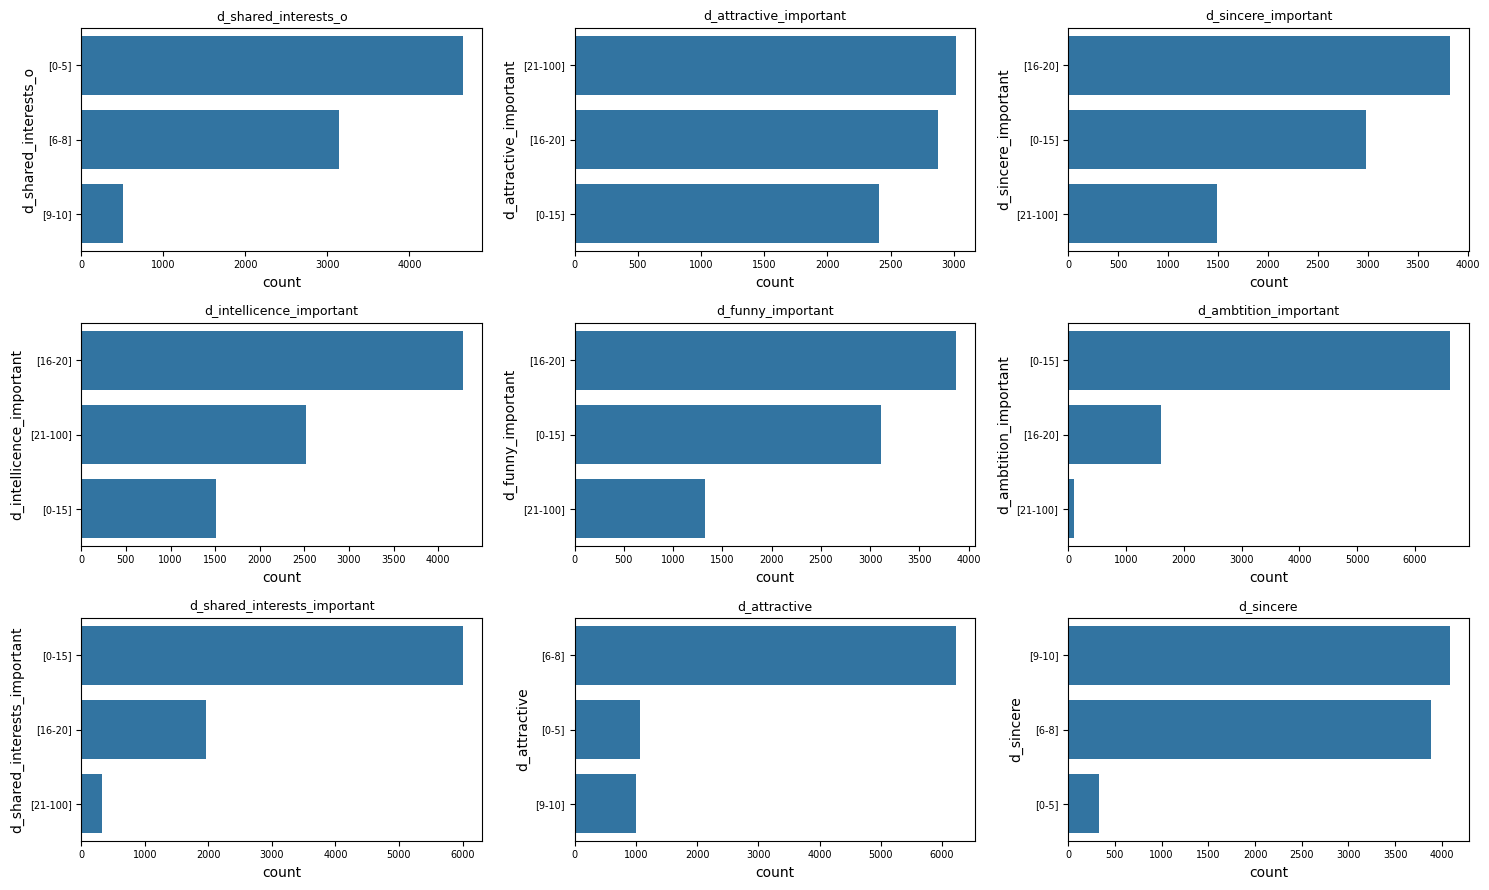

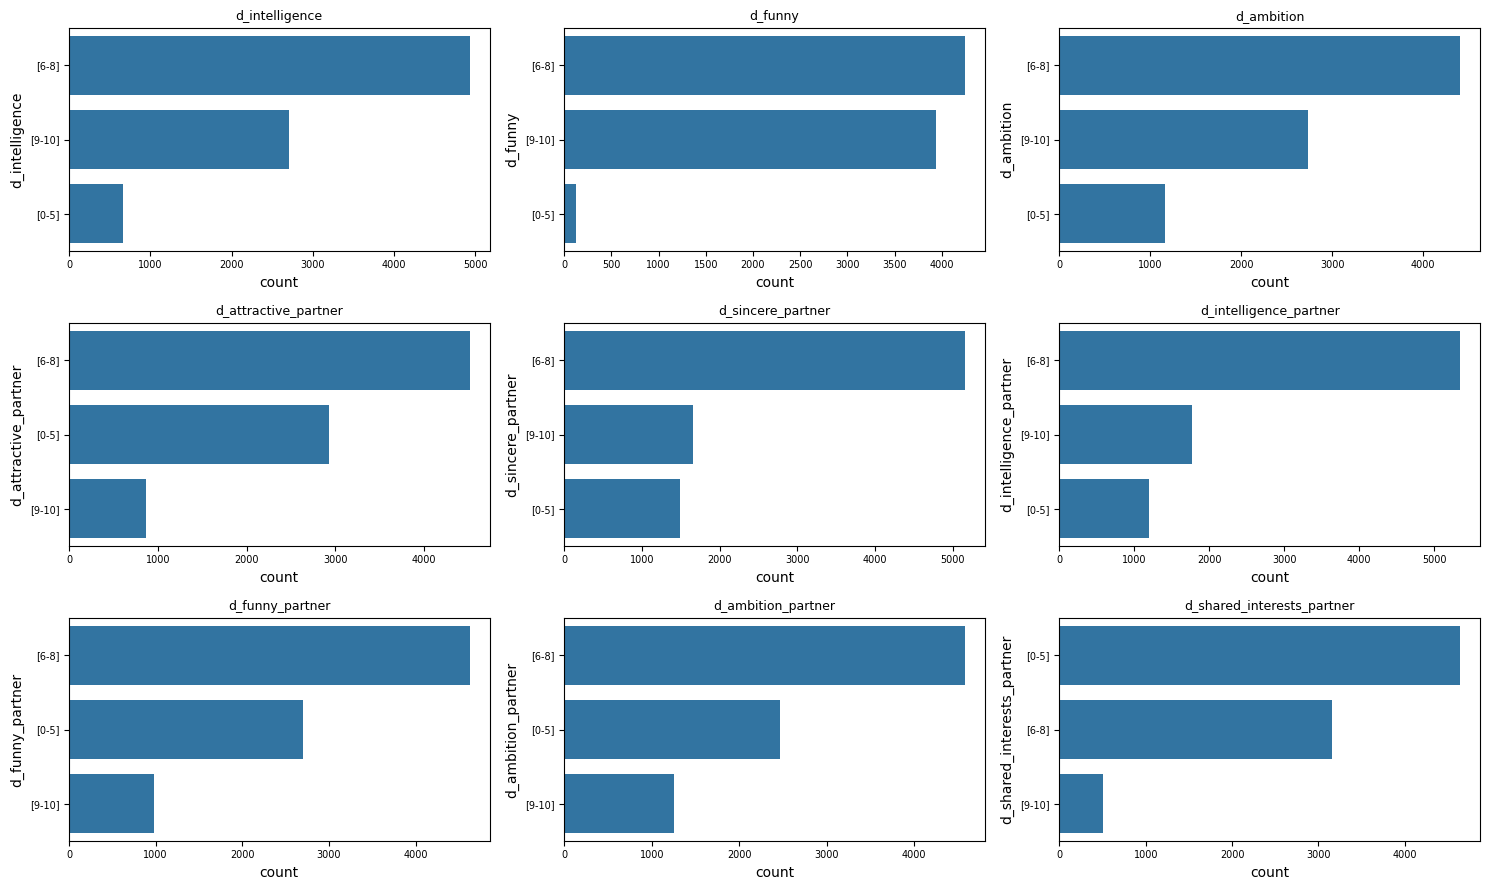

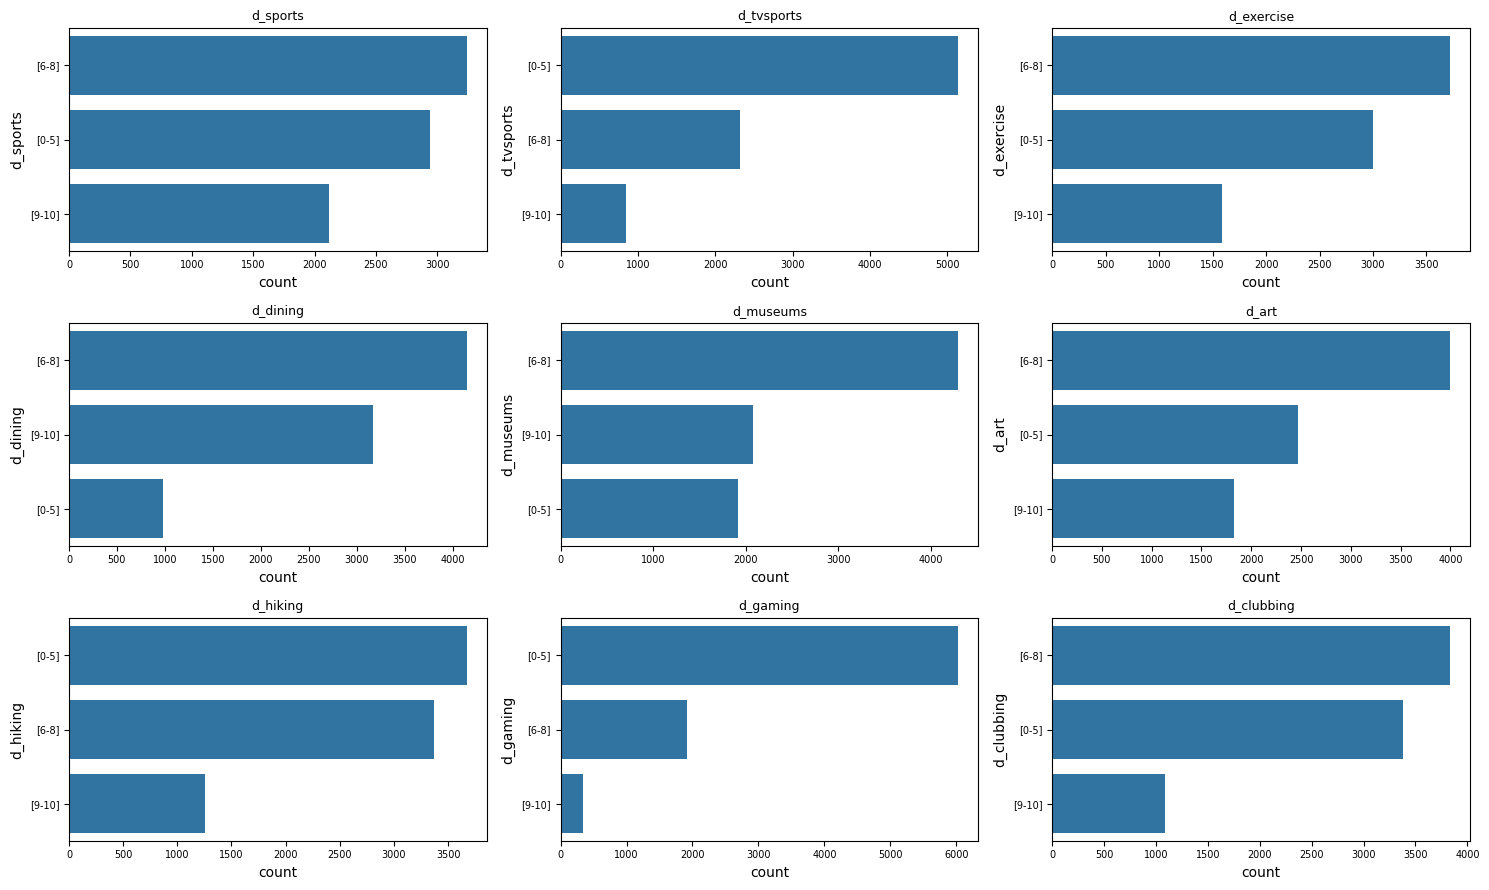

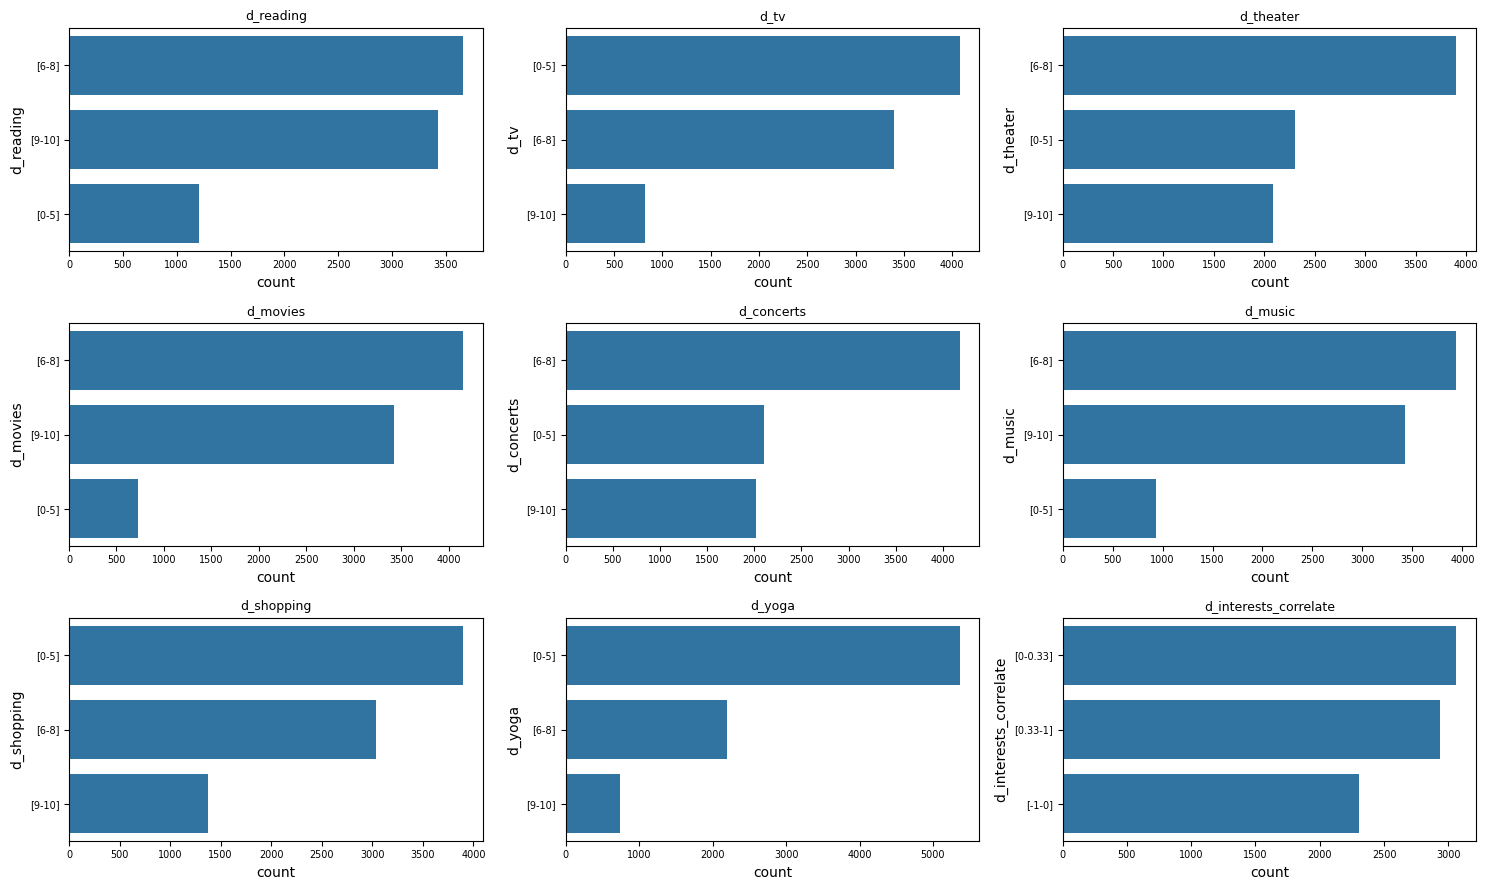

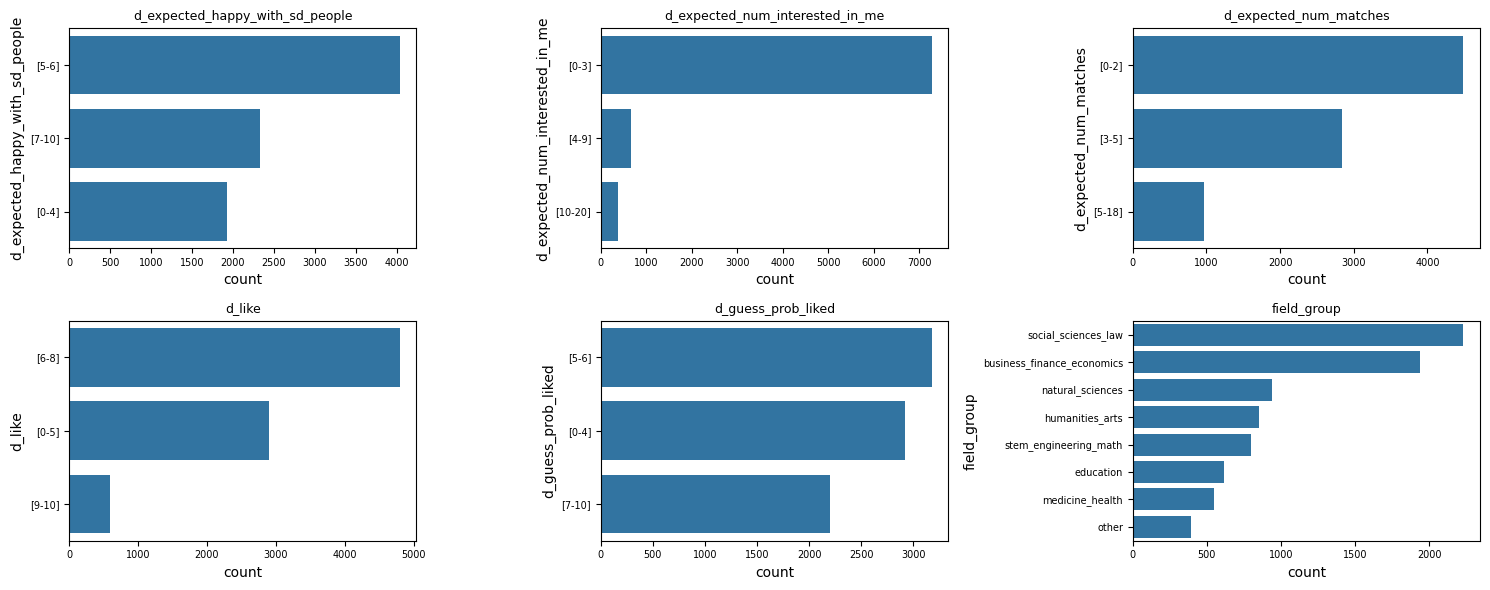

In [80]:
# категориальные — порциями по 9
for k in range(0, len(cat_cols), 9):
    plot_categorical_distributions(df_clean, cat_cols[k:k + 9])

Числовые признаки имеют преимущественно дискретный характер с заметной правосторонней асимметрией (особенно шкала важности 0–100 и возраст), а бинарные и разностные показатели распределены ожидаемо. Среди категориальных признаков пол представлен практически поровну, однако выражен дисбаланс по расе (доминируют европейцы/белые американцы) и специальностям (преобладают юриспруденция и социальная работа).

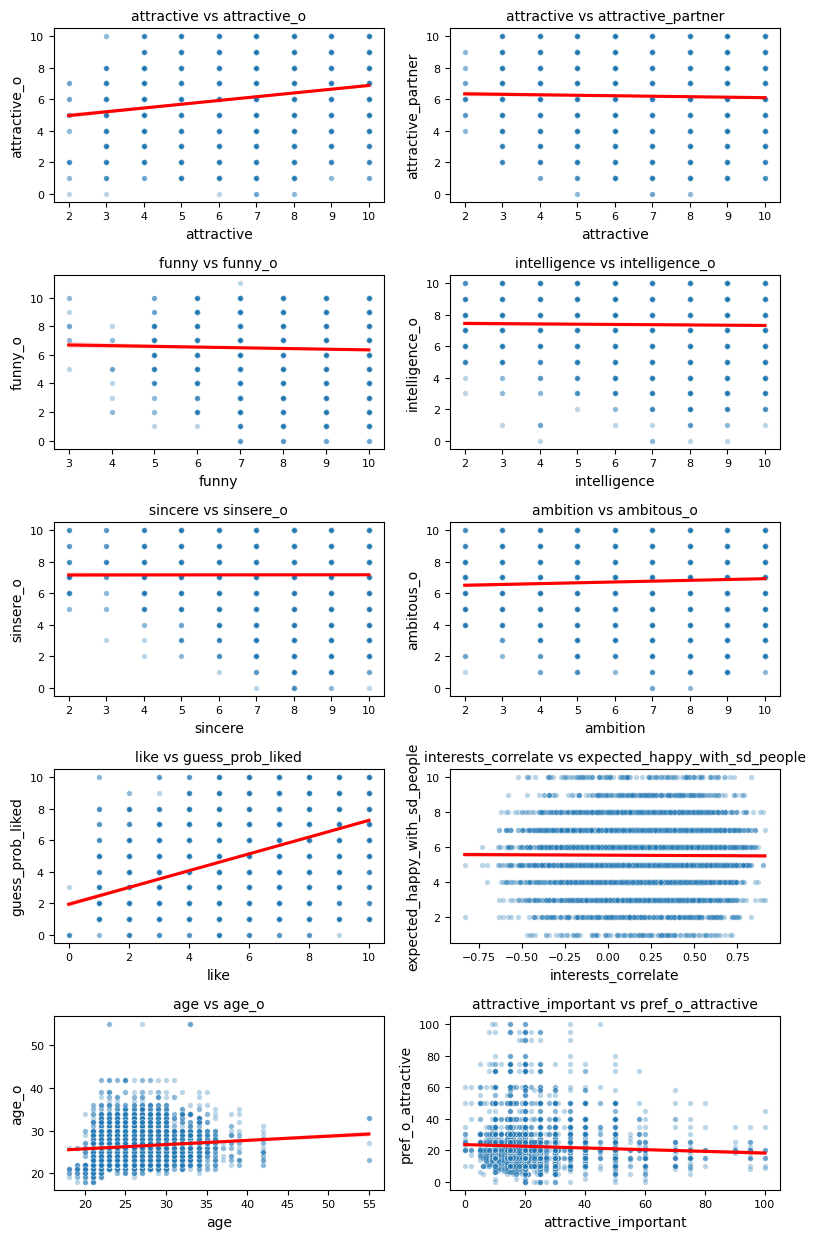

In [81]:
# рассмотрим парные распределения осмысленных пар
# выберем осмысленные пары (не все ~50×50, иначе будет каша)
pairs = [
    ("attractive", "attractive_o"),
    ("attractive", "attractive_partner"),
    ("funny", "funny_o"),
    ("intelligence", "intelligence_o"),
    ("sincere", "sinsere_o"),
    ("ambition", "ambitous_o"),
    ("like", "guess_prob_liked"),
    ("interests_correlate", "expected_happy_with_sd_people"),
    ("age", "age_o"),
    ("attractive_important", "pref_o_attractive"),
]

def plot_joint(df, pairs, ncols=2):
    n = len(pairs)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 2.5 * nrows))
    axes = axes.flatten()

    for i, (x, y) in enumerate(pairs):
        sns.scatterplot(data=df, x=x, y=y, alpha=0.3, s=15, ax=axes[i])
        sns.regplot(data=df, x=x, y=y, scatter=False, color="red", ax=axes[i])
        axes[i].set_title(f"{x} vs {y}", fontsize=10)
        axes[i].tick_params(labelsize=8)

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

plot_joint(df_clean, pairs)

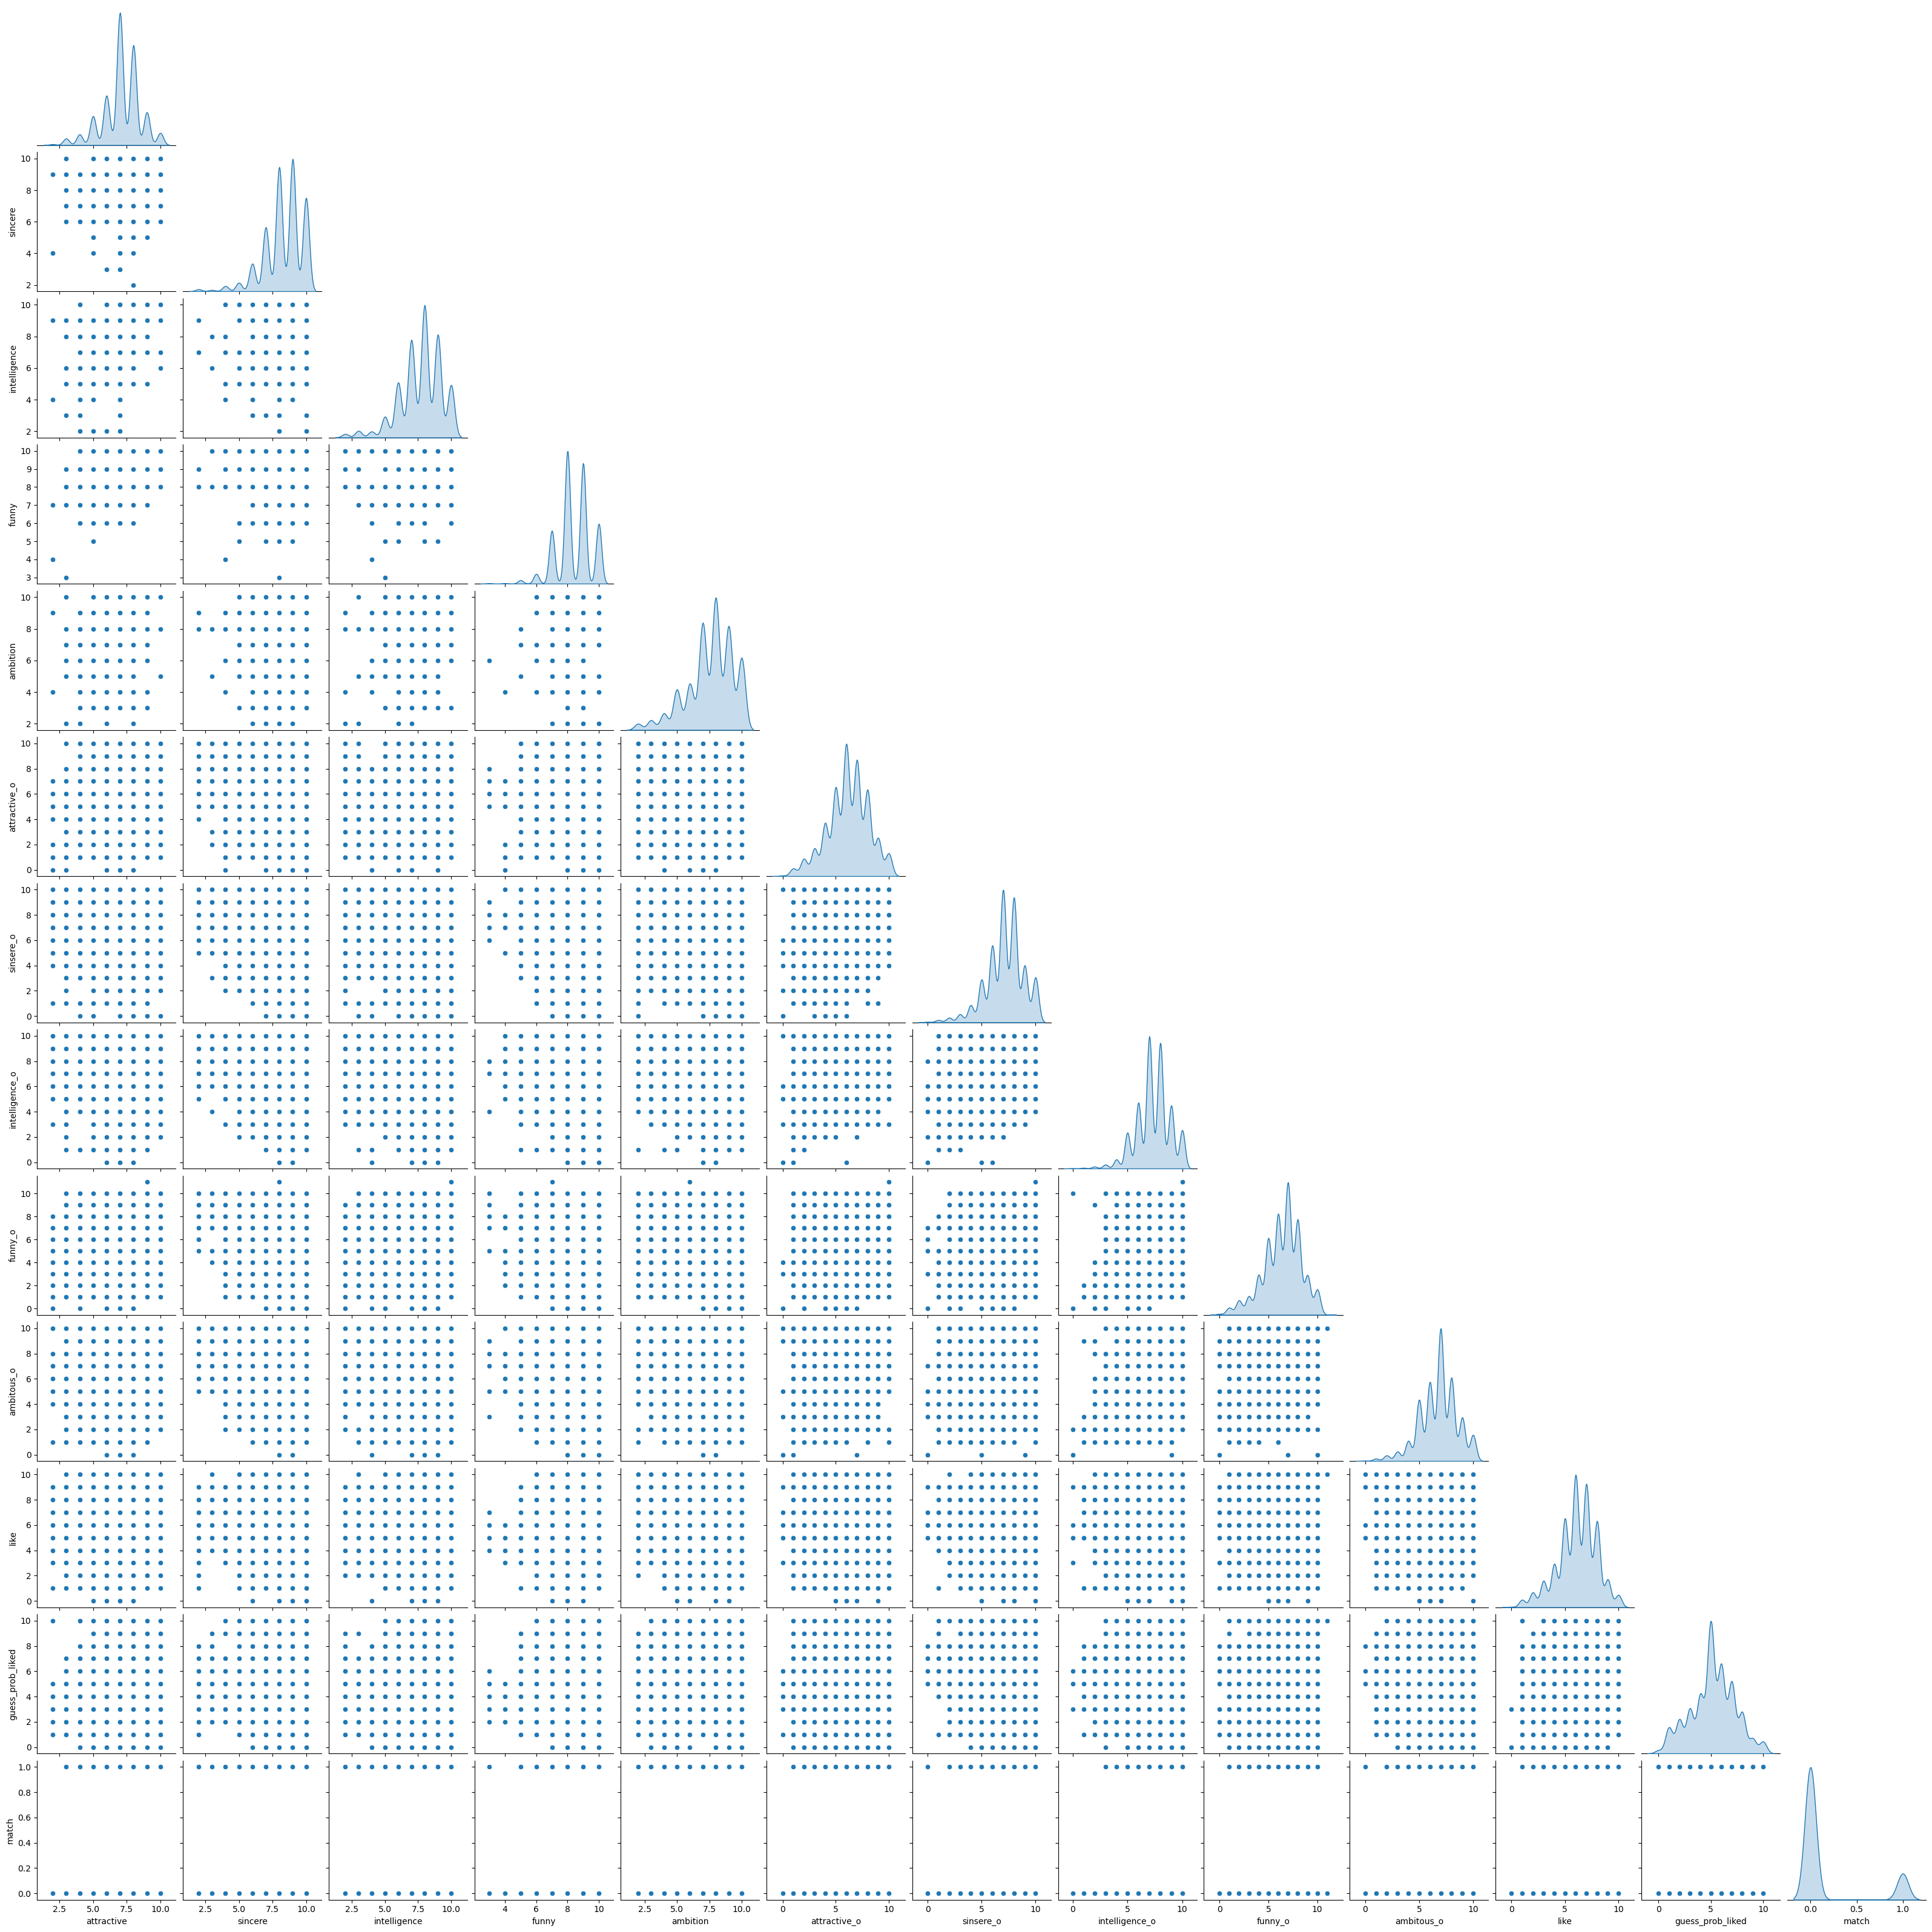

In [82]:
# посмотрим парные распределения основных параметров
subset = ["attractive", "sincere", "intelligence", "funny", "ambition",
          "attractive_o", "sinsere_o", "intelligence_o", "funny_o", "ambitous_o",
          "like", "guess_prob_liked", "match"]
sns.pairplot(df_clean[subset].dropna(), diag_kind="kde", corner=True)
plt.show()

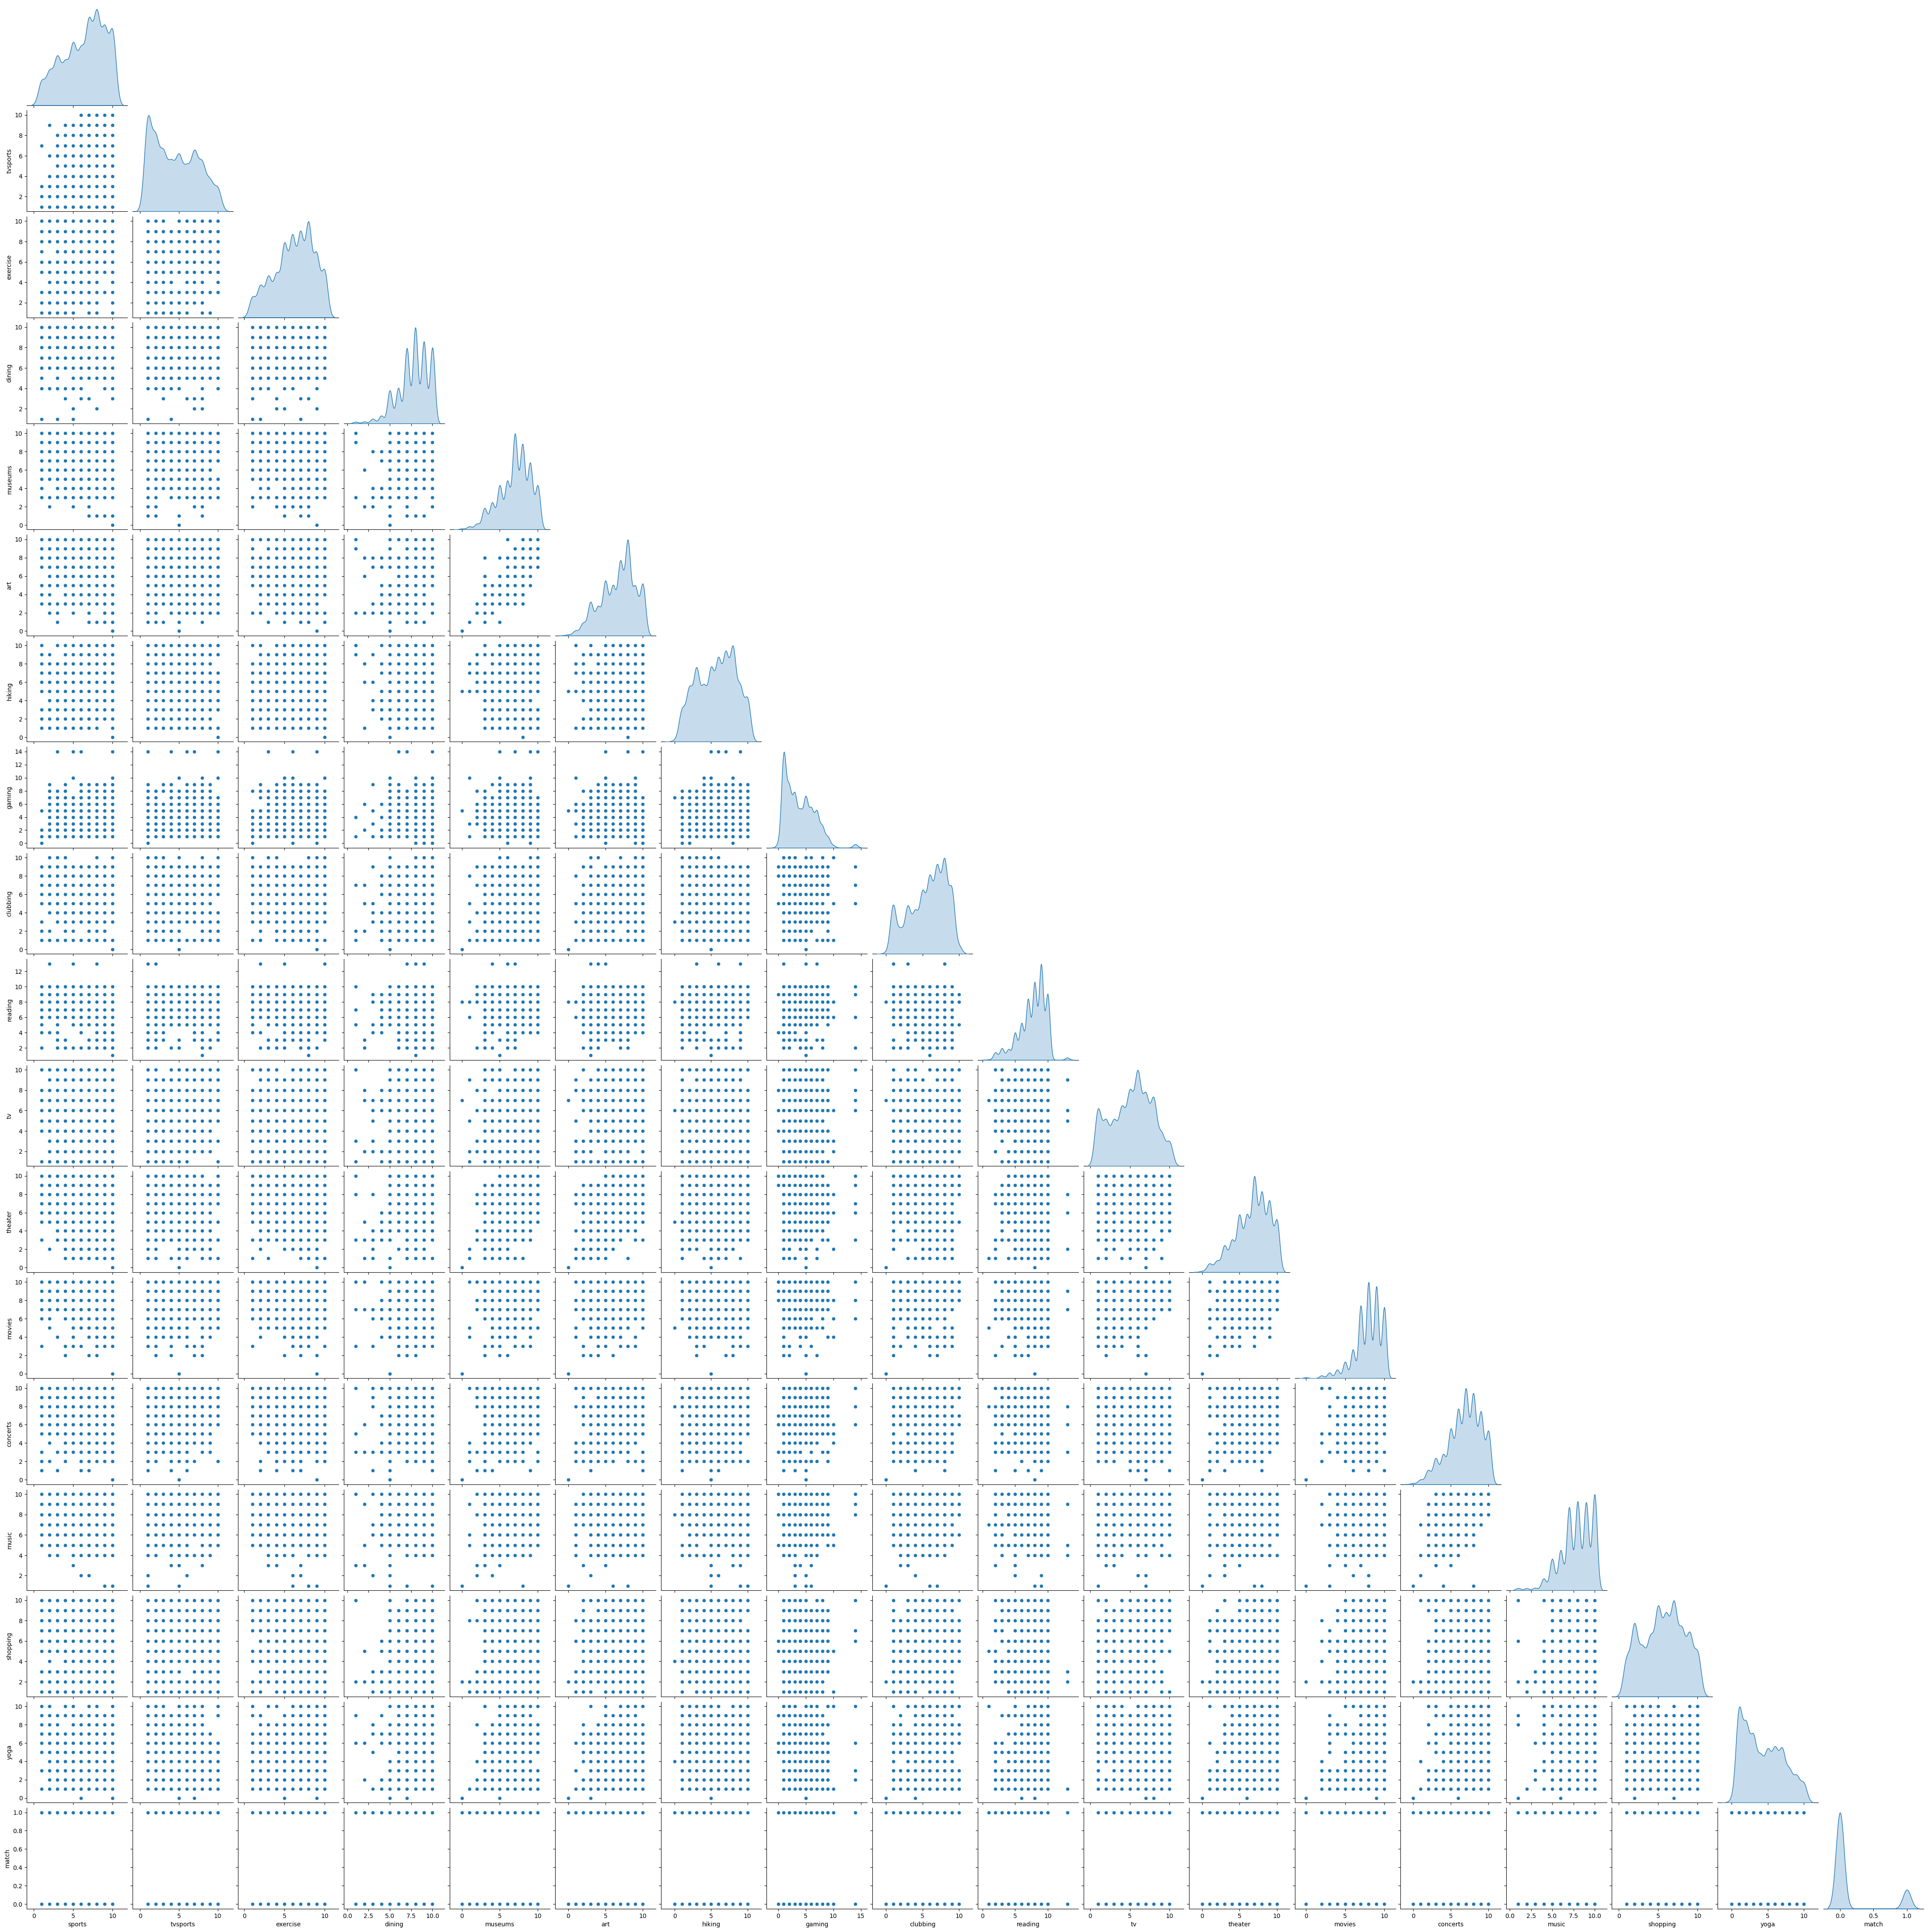

In [83]:
interests_cols = [
    "sports", "tvsports", "exercise", "dining", "museums", "art", 
    "hiking", "gaming", "clubbing", "reading", "tv", "theater", 
    "movies", "concerts", "music", "shopping", "yoga", "match"
]
sns.pairplot(df_clean[interests_cols].dropna(), diag_kind="kde", corner=True)
plt.show()

Визуальный анализ пар признаков показал, что большинство из них имеют слабую или умеренную связь, при этом заметная линейная зависимость прослеживается лишь в отдельных случаях (например, между симпатией и ожиданием взаимности, а также между возрастом респондентов). Поскольку точечные диаграммы не позволяют оценить силу и направление связей для всех переменных одновременно, перейдём к построению матрицы корреляций для комплексной количественной оценки.

Посмотрим корреляции

In [84]:
corr = df_clean[num_cols].corr(method="spearman") 

In [85]:
corr

,has_null,wave,age,age_o,d_age,samerace,importance_same_race,importance_same_religion,pref_o_attractive,pref_o_sincere,pref_o_intelligence,pref_o_funny,pref_o_ambitious,pref_o_shared_interests,attractive_o,sinsere_o,intelligence_o,funny_o,ambitous_o,attractive_important,sincere_important,intellicence_important,funny_important,ambtition_important,shared_interests_important,attractive,sincere,intelligence,funny,ambition,attractive_partner,sincere_partner,intelligence_partner,funny_partner,ambition_partner,sports,tvsports,exercise,dining,museums,art,hiking,gaming,clubbing,reading,tv,theater,movies,concerts,music,shopping,yoga,interests_correlate,expected_happy_with_sd_people,like,guess_prob_liked,met,decision,decision_o,match
has_null,1.000000,0.520429,0.146106,0.166218,0.081859,-0.014462,-0.024854,-0.059705,-0.056654,0.013742,-0.130861,0.000943,0.063978,0.089663,-0.010205,-0.000624,-0.008100,0.022904,-0.002785,-0.046037,-0.007096,-0.113533,0.039069,0.047660,0.056265,0.042853,0.040642,0.003245,0.036737,0.058799,-0.003109,-0.010494,-0.018415,0.009767,0.000267,0.024902,-0.000679,0.039153,0.038402,0.040195,0.054708,0.090354,-0.018374,-0.036487,0.056668,-0.044669,-0.021826,-0.022145,-0.019820,0.024328,0.023183,0.027075,0.050637,0.025919,-0.021276,0.034895,-0.057918,-0.001213,-0.010061,-0.013335
wave,0.520429,1.000000,0.102446,0.098171,0.038962,-0.005960,-0.031203,-0.060528,0.131359,0.014404,-0.004708,0.034396,-0.142628,-0.016669,-0.027315,-0.032605,-0.044263,-0.007643,-0.026377,0.125568,0.013757,-0.005888,0.032973,-0.138946,-0.013367,0.037803,0.058525,0.029277,-0.032495,0.041545,-0.030319,-0.035774,-0.042868,-0.009513,-0.026478,0.002991,-0.033166,-0.023829,0.120655,0.083222,0.124114,0.015791,-0.019217,-0.028621,0.004085,0.000785,0.027169,0.024747,0.064339,0.060455,0.071493,0.026231,0.045022,0.066689,-0.054719,0.013315,-0.080054,-0.013745,-0.012028,-0.017836
age,0.146106,0.102446,1.000000,0.096590,0.162123,-0.010205,-0.137740,-0.062807,-0.102175,0.040210,-0.022859,-0.020097,0.091127,0.053101,-0.037734,0.007270,0.039067,-0.033809,0.033221,0.041162,0.040349,0.028190,-0.106844,-0.089063,0.017371,0.083589,-0.014751,-0.092989,0.010628,-0.051584,0.019017,-0.009897,-0.007005,-0.013214,-0.033666,-0.032085,-0.111646,-0.000883,0.093822,0.090911,0.066797,0.046167,-0.161397,-0.056786,0.091037,-0.219718,-0.015436,-0.034574,-0.090862,-0.082476,-0.157751,0.012280,0.092972,0.010780,0.008469,0.010939,-0.070721,0.001797,-0.032187,-0.029597
age_o,0.166218,0.098171,0.096590,1.000000,0.161469,-0.009743,-0.004286,0.037701,0.045199,0.040562,0.027728,-0.107141,-0.091845,0.016187,0.015841,-0.011107,-0.009857,-0.016036,-0.036660,-0.102503,0.040152,-0.022557,-0.020222,0.091709,0.053129,0.004551,0.022042,0.001414,-0.001947,-0.004821,-0.039072,0.005697,0.038891,-0.034602,0.033724,-0.011848,-0.026632,0.028716,0.028813,0.057248,0.058257,0.033979,-0.074634,-0.030158,0.017802,-0.004648,0.040579,0.028124,0.002727,0.010884,0.026944,0.040506,0.091974,-0.021667,-0.027210,-0.002966,-0.059277,-0.034749,-0.001177,-0.031928
d_age,0.081859,0.038962,0.162123,0.161469,1.000000,0.048785,-0.043927,-0.008434,0.016383,0.009814,-0.005258,-0.010433,-0.026315,0.029392,-0.032026,-0.000796,-0.009903,-0.020664,-0.014397,0.018740,0.005814,-0.012455,-0.007225,-0.027146,0.028224,0.004550,-0.036729,-0.009884,-0.038795,-0.015309,-0.029106,-0.003918,-0.014366,-0.021622,-0.015593,-0.031273,-0.024792,-0.014978,-0.021309,0.021101,0.028387,-0.011128,-0.082307,-0.040937,0.025215,-0.017719,0.020914,0.010817,-0.000454,0.016109,-0.029952,0.052299,0.019635,0.054797,-0.045532,-0.036792,-0.103140,-0.040581,-0.047581,-0.065272
samerace,-0.014462,-0.005960,-0.010205,-0.009743,0.048785,1.000000,0.087165,0.076693,0.019653,-0.049138,0.020482,0.031976,-0.011724,-0.018358,0.050127,0.010055,0.010915,0.010750,0.008472,0.018342,-0.047377,0.024392,0.030598,-0.012244,-0.017951,0.033060,-0.023540,-0.023276,0.035647,-0.016799,0.047880,0.010869,0.012454,0.009807,0.009127,0.032999,-0.037797,0.040704,-0.052976,0.002761,0

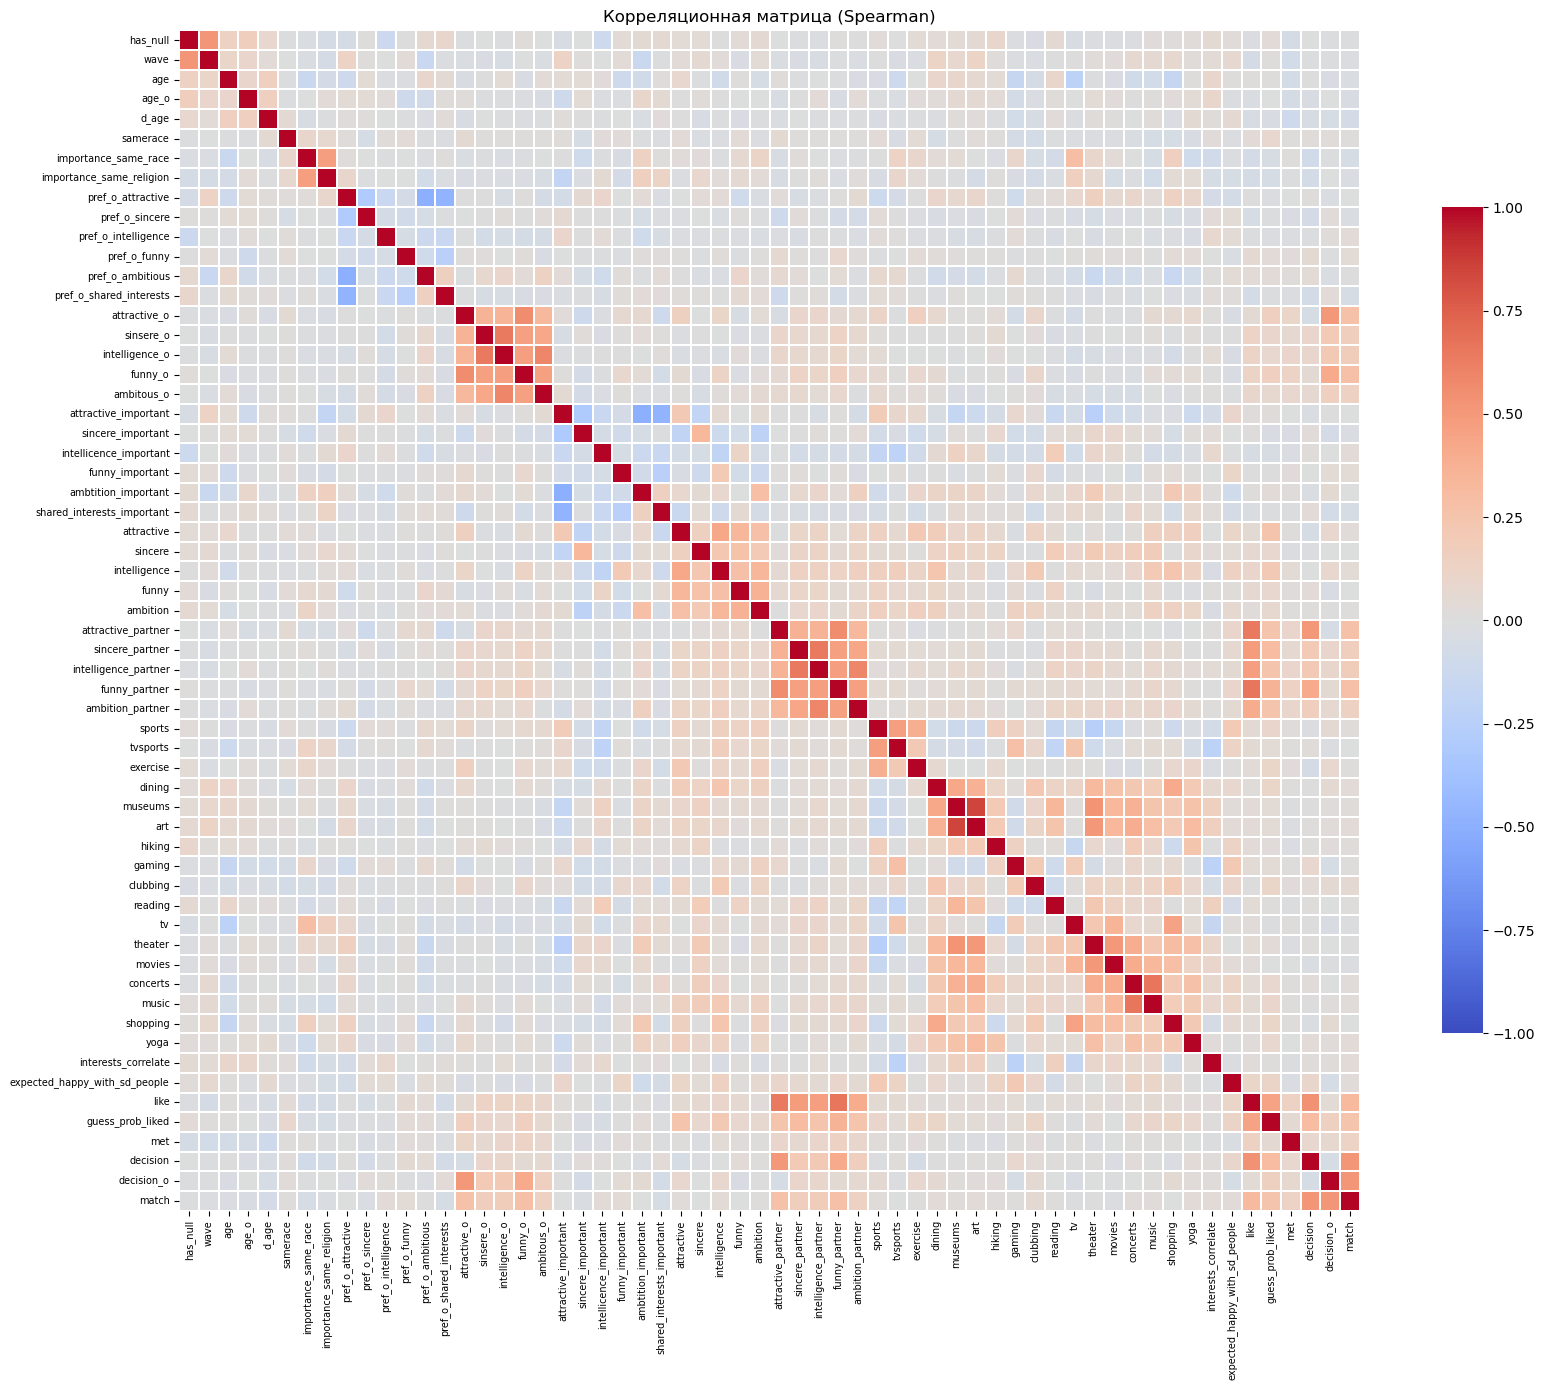

In [86]:
plt.figure(figsize=(18, 14))
sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    vmin=-1, vmax=1,
    square=True,
    linewidths=0.3,
    cbar_kws={"shrink": 0.7},
    xticklabels=True, yticklabels=True,
)
plt.xticks(fontsize=7, rotation=90)
plt.yticks(fontsize=7)
plt.title("Корреляционная матрица (Spearman)", fontsize=12)
plt.tight_layout()
plt.show()

In [87]:
# рассмотрим какие признаки имеют корреляцию выше предела
corr_matrix = df_clean[num_cols].corr(method="spearman").abs()

# Оставляем только верхний треугольник 
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Находим пары с корреляцией выше порога
threshold = 0.7
high_corr = upper.stack().reset_index()
high_corr.columns = ["feature_1", "feature_2", "corr"]
high_corr = high_corr[high_corr["corr"] > threshold].sort_values("corr", ascending=False)

if high_corr.empty:
    print(f"Признаков с корреляцией выше {threshold} не найдено.")
else:
    print(f"Найдено пар с корреляцией > {threshold}: {len(high_corr)}\n")
    display(high_corr.round(3))

Найдено пар с корреляцией > 0.7: 1



,feature_1,feature_2,corr
1560,museums,art,0.848


In [88]:
# посмотрим какие признаки сильно коррелируют с зависимой переменной
corr_match = corr["match"].drop("match").sort_values(key=abs, ascending=False)
display(corr_match.head(15).round(3).to_frame("corr_with_match"))

,corr_with_match
decision_o,0.523
decision,0.520
like,0.319
funny_partner,0.281
funny_o,0.281
attractive_o,0.270
attractive_partner,0.268
guess_prob_liked,0.252
intelligence_o,0.175
intelligence_partner,0.174


**Вывод.** 
Анализ матрицы корреляций выявил лишь одну пару признаков с очень высокой связью (|r| > 0.7): `museums` и `art` (r = 0.85), что логично объясняется пересекающимися интересами к культурным мероприятиям. Большинство остальных признаков демонстрируют слабые или умеренные связи, что указывает на отсутствие серьёзной мультиколлинеарности в данных.

При оценке связи с целевой переменной `match` наибольшие коэффициенты оказались у `decision_o` и `decision` (≈ 0.55), а также `like` (≈ 0.32) что технически ожидаемо, так как они описывают решение партнёров. Среди содержательных признаков наибольший вклад вносят субъективные оценки (внешность и чувство юмора), тогда как объективные демографические показатели (возраст, раса) почти не коррелируют с исходом свидания. 

Поскольку классические линейные корреляции не дают полной картины (особенно для бинарной целевой переменной), перейдём к более детальному рассмотрению `match`.

### Анализ зависимой переменной

In [89]:
df_clean['match'].value_counts()

match
0    6934
1    1365
Name: count, dtype: int64

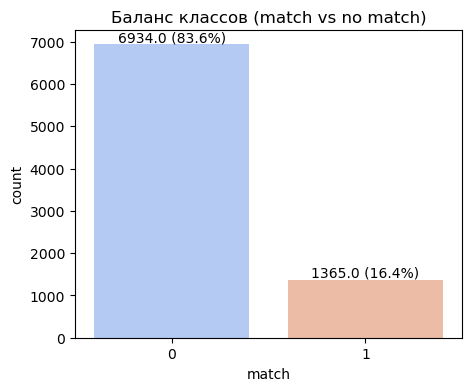

In [90]:
# Баланс классов
plt.figure(figsize=(5, 4))
ax = sns.countplot(data=df_clean, x='match', palette='coolwarm')
total = len(df_clean)
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height} ({height/total:.1%})', 
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom')
plt.title('Баланс классов (match vs no match)')
plt.show()

In [91]:
# рассмотрим деление match по группам признаков
features_partner = ['attractive_o', 'sinsere_o', 'intelligence_o', 'funny_o', 'ambitous_o']
features_partner_gives = ['attractive_partner', 'sincere_partner', 'intelligence_partner', 'funny_partner', 'ambition_partner']
features_self = ['attractive', 'sincere', 'intelligence', 'funny', 'ambition']
features_meta = ['guess_prob_liked', 'met', 'interests_correlate', 'expected_happy_with_sd_people']
features_demo = ['age', 'age_o', 'd_age', 'importance_same_race', 'importance_same_religion']

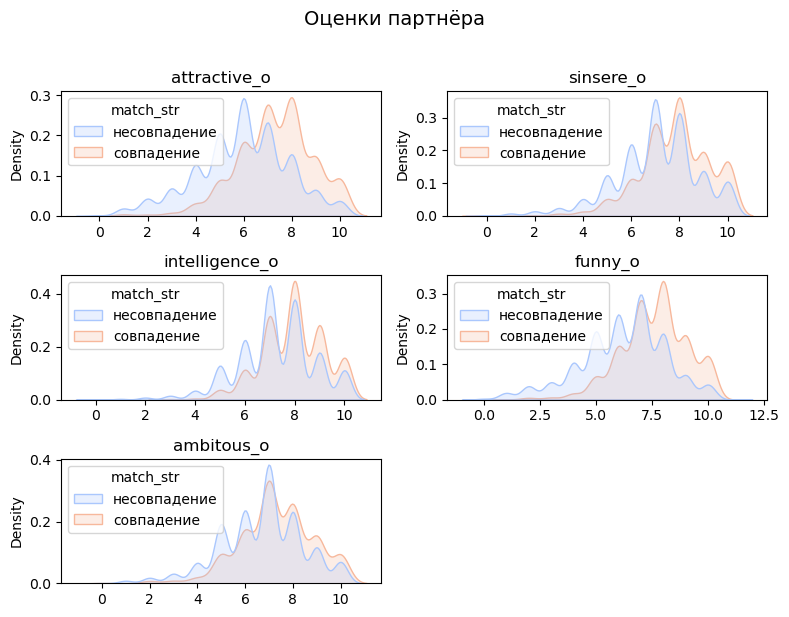

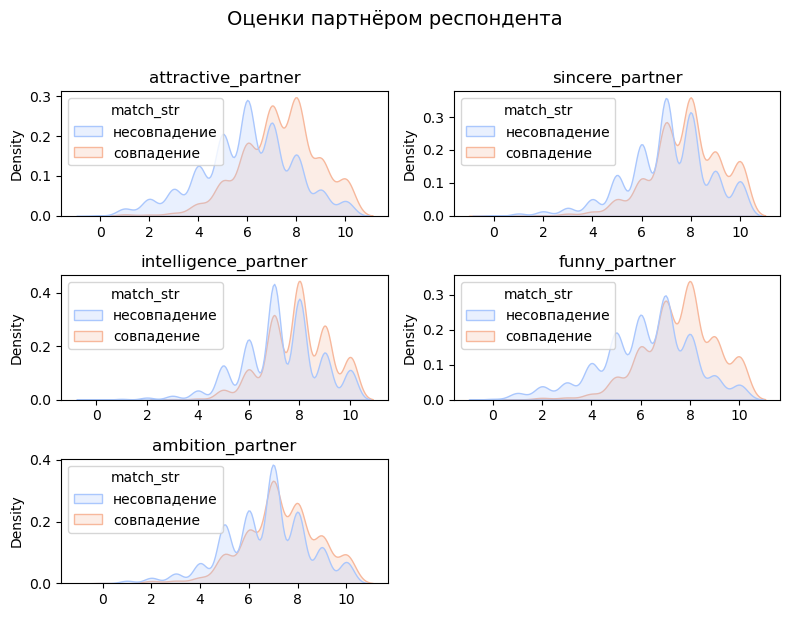

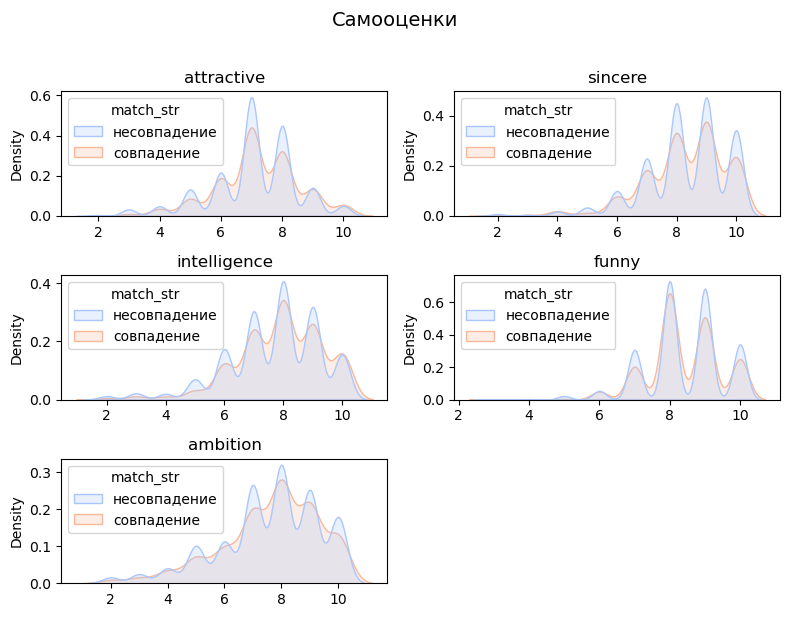

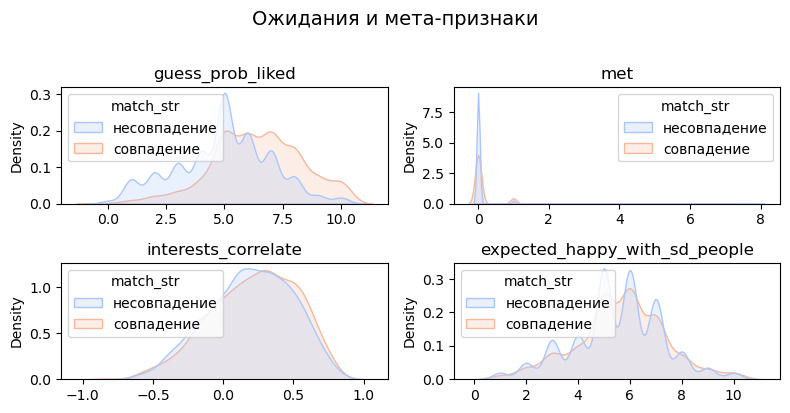

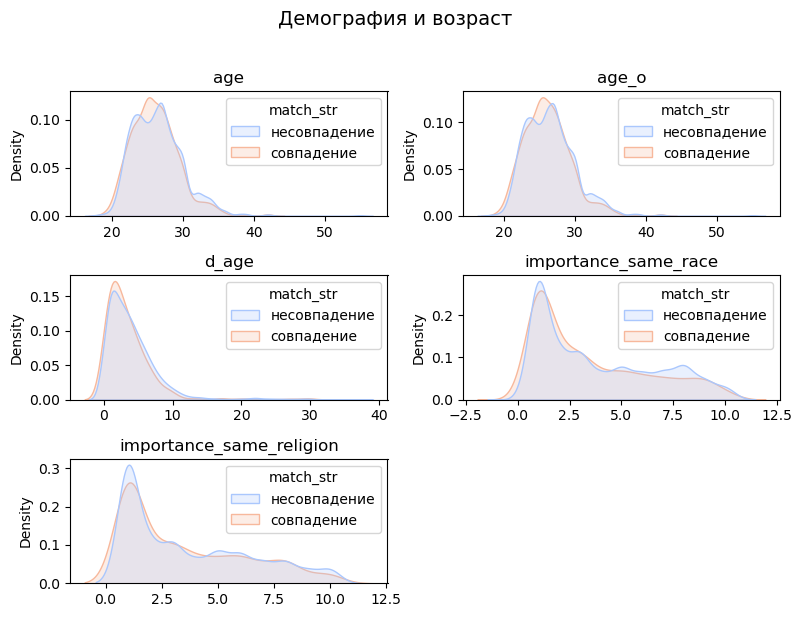

In [92]:
df_clean['match_str'] = df_clean['match'].map({0: 'несовпадение', 1: 'совпадение'})

def plot_kde_features(df, features, ncols=2, title=""):
    n = len(features)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 2 * nrows))
    axes = axes.flatten()
    
    for i, feat in enumerate(features):
        sns.kdeplot(data=df, x=feat, hue='match_str', fill=True, common_norm=False, ax=axes[i], palette='coolwarm')
        axes[i].set_title(feat)
        axes[i].set_xlabel('')
        
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])
        
    fig.suptitle(title, fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()

# Вызовы для всех групп
plot_kde_features(df_clean, features_partner, title="Оценки партнёра")
plot_kde_features(df_clean, features_partner_gives, title="Оценки партнёром респондента")
plot_kde_features(df_clean, features_self, title="Самооценки")
plot_kde_features(df_clean, features_meta, title="Ожидания и мета-признаки")
plot_kde_features(df_clean, features_demo, title="Демография и возраст")

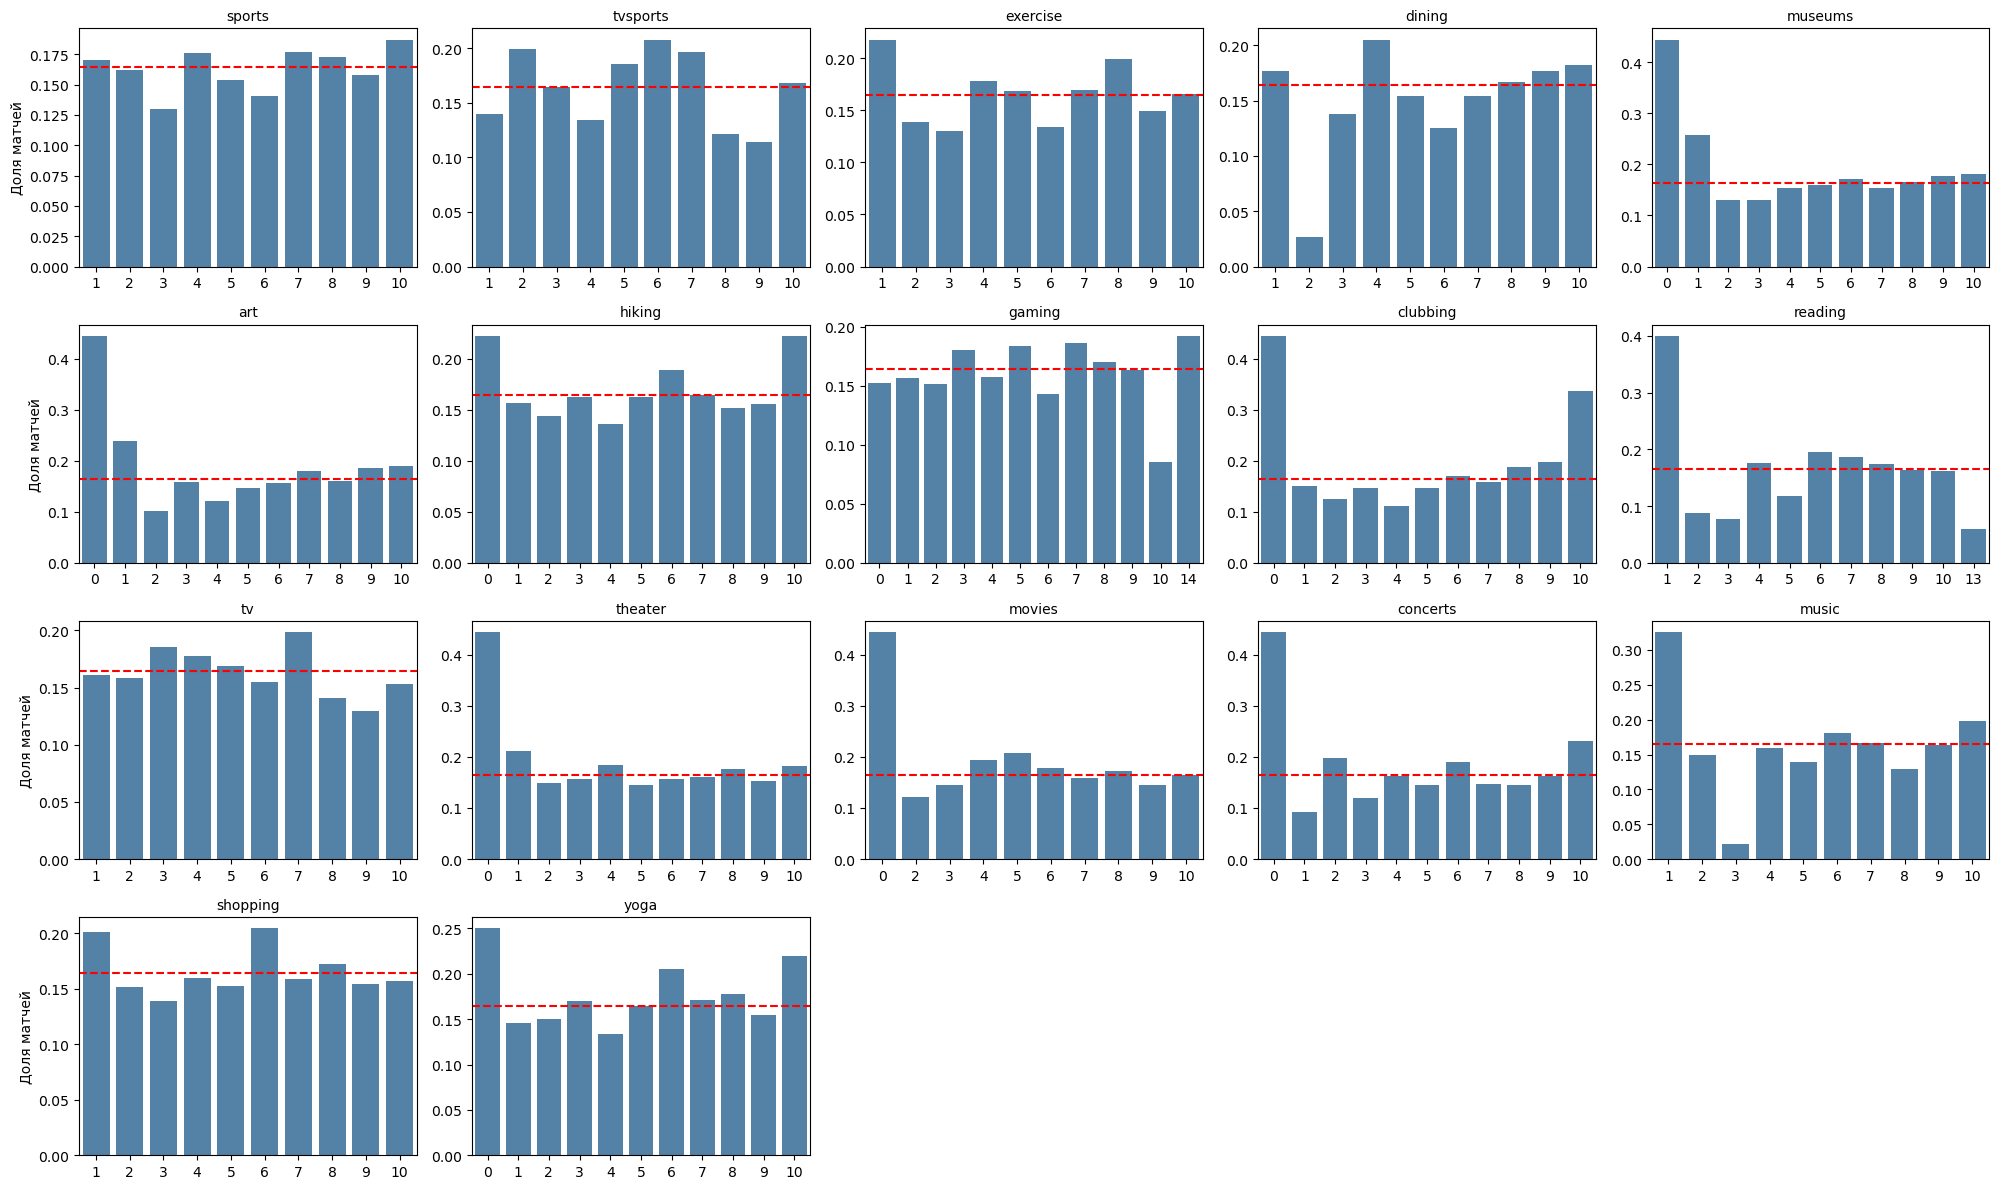

In [93]:
# доля матчей в зависимости от категории
features_interest = ['sports', 'tvsports', 'exercise', 'dining', 'museums', 
                     'art', 'hiking', 'gaming', 'clubbing', 'reading', 
                     'tv', 'theater', 'movies', 'concerts', 'music', 'shopping', 'yoga']

fig, axes = plt.subplots(4, 5, figsize=(20, 12))
axes = axes.flatten()

for i, feat in enumerate(features_interest):
    match_rate = df_clean.groupby(feat)['match'].mean().reset_index()
    sns.barplot(data=match_rate, x=feat, y='match', color='steelblue', ax=axes[i])
    axes[i].set_title(feat, fontsize=10)
    axes[i].set_ylabel('Доля матчей' if i % 5 == 0 else '')
    axes[i].set_xlabel('')
    axes[i].axhline(df_clean['match'].mean(), color='red', linestyle='--')

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Отдельно рассмотрим распределение для полов

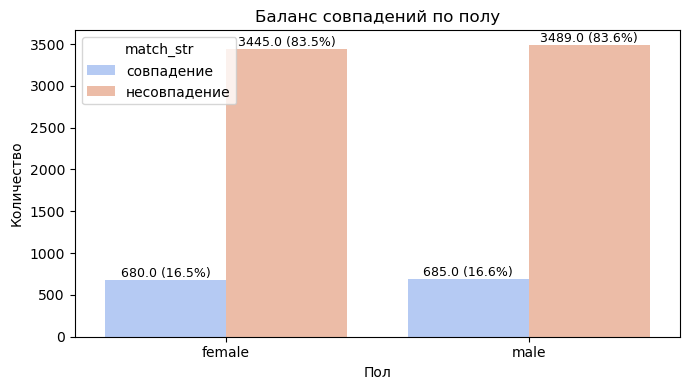

In [94]:
plt.figure(figsize=(7, 4))
ax = sns.countplot(
    data=df_clean,
    x='gender',
    hue='match_str',
    hue_order=['совпадение', 'несовпадение'], palette='coolwarm'
)

# подписи процентов
total_per_gender = df_clean.groupby('gender').size()
for p in ax.patches:
    h = p.get_height()
    if h > 0:
        gender = ax.get_xticklabels()[int(p.get_x() + p.get_width() / 2)].get_text()
        ax.annotate(f'{h} ({h / total_per_gender[gender]:.1%})',
                    (p.get_x() + p.get_width() / 2., h),
                    ha='center', va='bottom', fontsize=9)

plt.title('Баланс совпадений по полу')
plt.xlabel('Пол')
plt.ylabel('Количество')
plt.tight_layout()
plt.show()

**Вывод по распределениям признаков в разрезе `match`**

Целевая переменная несбалансирована: совпадение встречается примерно в 16,4% случаев. Анализ распределений показал, что на вероятность взаимной симпатии заметно влияет как симпатия самого респондента (особенно высокие оценки внешности и чувства юмора партнёра), так и симпатия партнёра. Если респондент высоко оценивает качества партнёра, а партнёр, в свою очередь, высоко оценивает респондента, вероятность матча заметно возрастает. При этом самооценки респондента почти не различаются между группами, что говорит о решающей роли именно взаимной симпатии с обеих сторон, а не оценки самого себя. Демографические признаки (возраст, пол, разница в возрасте) и общие интересы (`interests_correlate`, факт знакомства `met`) не показывают заметной связи с исходом свидания. Анализ интересов к хобби не выявил устойчивых закономерностей: для большинства активностей доля матчей слабо зависит от уровня интереса, а наблюдаемые колебания (например, пики при отдельных значениях в `gaming`, `yoga`, `art`) носят разрозненный характер и не образуют общего тренда. Пол на вероятность совпадения не влияет (женщины — 16,5%, мужчины — 16,6%). Таким образом, ключевыми факторами взаимной симпатии выступают высокий уровень взаимных оценок партнёров и совпадение симпатий, а не самооценка или формальные характеристики.

Таким образом, следующим шагом проанализируем взаимную симпатию.

### Анализ взаимности и симпатии

Хотя первичный анализ в разрезе целевой переменной match выявил ключевые паттерны, для более глубокого понимания механизма возникновения совпадений необходимо рассмотреть саму природу взаимной и односторонней симпатии. Перейдём к детальному анализу взаимных оценок, роли общих интересов и того, насколько точно участники угадывают отношение к себе со стороны партнёра.

Целевая переменная `match` - бинарный признак, показывающий, возникло ли **взаимное совпадение**: `1`, если оба участника свидания (респондент и его партнёр) поставили друг другу `decision = 1` («да, хочу встретиться ещё»), и `0` - если хотя бы один из них сказал «нет».

In [95]:
# Создаём категории для типа симпатии
def get_interest_type(row):
    if row['decision'] == 1 and row['decision_o'] == 1: return 'Взаимная'
    elif row['decision'] == 1 and row['decision_o'] == 0: return 'Односторонняя (я)'
    elif row['decision'] == 0 and row['decision_o'] == 1: return 'Односторонняя (партнёр)'
    else: return 'Нет симпатии'

df_clean['interest_type'] = df_clean.apply(get_interest_type, axis=1)
order = ['Нет симпатии', 'Односторонняя (партнёр)', 'Односторонняя (я)', 'Взаимная']

Рассмотрим распределения взаимных оценок для взаимных и невзаимных случаев

In [96]:
describe_cols(['attractive_o', 'sinsere_o', 'intelligence_o', 'funny_o', 'ambitous_o',
    'attractive_partner', 'sincere_partner', 'intelligence_partner', 
    'funny_partner', 'ambition_partner'])

,описание
столбец,
attractive_o,оценка партнёром моей привлекательности
sinsere_o,оценка партнёром моей искренности
intelligence_o,оценка партнёром моего интеллекта
funny_o,оценка партнёром моего юмора
ambitous_o,оценка партнёром моей амбициозности
attractive_partner,моя оценка привлекательности партнёра
sincere_partner,моя оценка искренности партнёра
intelligence_partner,моя оценка интеллекта партнёра
funny_partner,моя оценка юмора партнёра


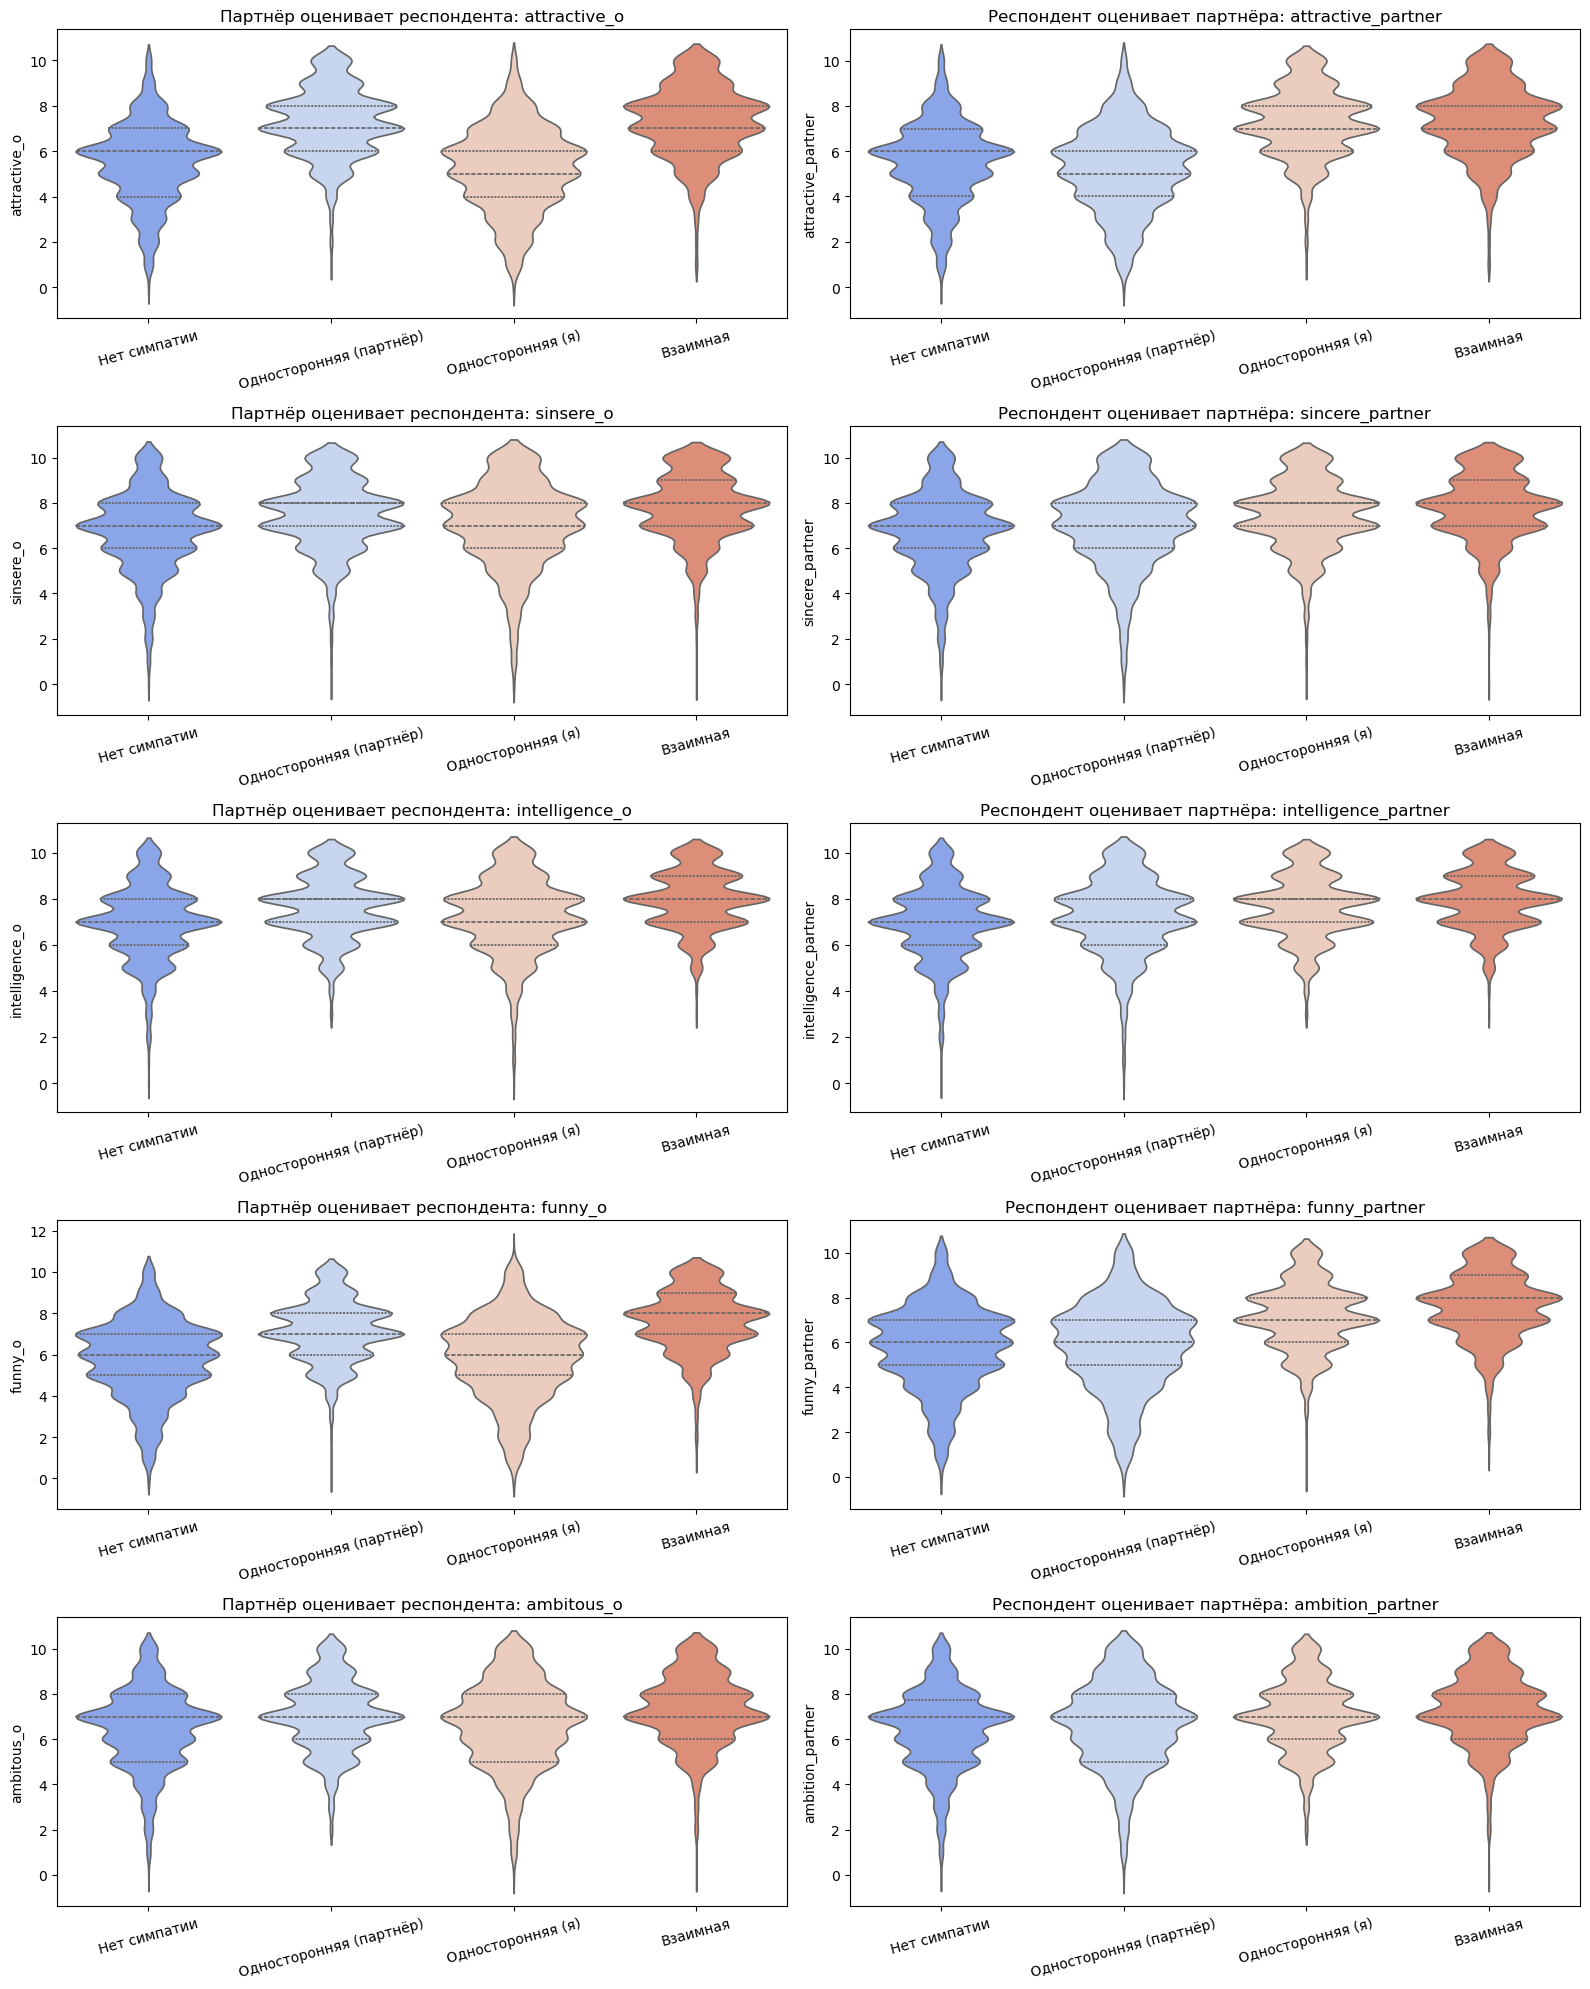

In [97]:
# Объединяем в пары для удобства: (оценка партнёра, оценка партнёром)
pairs = [
    ('attractive_o', 'attractive_partner'),
    ('sinsere_o', 'sincere_partner'),
    ('intelligence_o', 'intelligence_partner'),
    ('funny_o', 'funny_partner'),
    ('ambitous_o', 'ambition_partner'),
]

fig, axes = plt.subplots(5, 2, figsize=(16, 20))

for i, (col_o, col_partner) in enumerate(pairs):
    # Слева — как партнёр оценивает респондента 
    sns.violinplot(data=df_clean, x='interest_type', y=col_o, order=order, palette='coolwarm', inner='quart', ax=axes[i, 0])
    axes[i, 0].set_title(f'Партнёр оценивает респондента: {col_o}')
    axes[i, 0].set_xlabel('')
    axes[i, 0].tick_params(axis='x', rotation=15)
    
    # Справа — как респондент оценивает партнёра
    sns.violinplot(data=df_clean, x='interest_type', y=col_partner, order=order, palette='coolwarm', inner='quart', ax=axes[i, 1])
    axes[i, 1].set_title(f'Респондент оценивает партнёра: {col_partner}')
    axes[i, 1].set_xlabel('')
    axes[i, 1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

In [98]:
order = ['Нет симпатии', 'Односторонняя (партнёр)', 'Односторонняя (я)', 'Взаимная']

# Все 10 признаков оценок (партнёра и партнёром)
cols_to_summarize = [
    'attractive_o', 'sinsere_o', 'intelligence_o', 'funny_o', 'ambitous_o',
    'attractive_partner', 'sincere_partner', 'intelligence_partner', 
    'funny_partner', 'ambition_partner'
]

# Средние значения по типам симпатии
pivot_mean = df_clean.groupby('interest_type')[cols_to_summarize].mean().reindex(order).round(2)

# Медианы (менее чувствительны к выбросам)
pivot_median = df_clean.groupby('interest_type')[cols_to_summarize].median().reindex(order).round(2)

# Количество наблюдений в каждой группе
pivot_count = df_clean.groupby('interest_type').size().reindex(order).to_frame('Количество')

print("Средние значения оценок по типам симпатии")
display(pivot_mean)

print("\nМедианные значения оценок по типам симпатии")
display(pivot_median)

print("\nКоличество наблюдений")
display(pivot_count)

Средние значения оценок по типам симпатии


,attractive_o,sinsere_o,intelligence_o,funny_o,ambitous_o,attractive_partner,sincere_partner,intelligence_partner,funny_partner,ambition_partner
interest_type,,,,,,,,,,
Нет симпатии,5.51,6.73,6.96,5.74,6.46,5.51,6.73,6.95,5.74,6.45
Односторонняя (партнёр),7.26,7.45,7.62,7.16,7.04,5.24,7.03,7.22,5.81,6.66
Односторонняя (я),5.24,7.03,7.23,5.81,6.66,7.26,7.45,7.62,7.16,7.04
Взаимная,7.31,7.80,7.94,7.58,7.31,7.31,7.80,7.94,7.59,7.31



Медианные значения оценок по типам симпатии


,attractive_o,sinsere_o,intelligence_o,funny_o,ambitous_o,attractive_partner,sincere_partner,intelligence_partner,funny_partner,ambition_partner
interest_type,,,,,,,,,,
Нет симпатии,6.0,7.0,7.0,6.0,7.0,6.0,7.0,7.0,6.0,7.0
Односторонняя (партнёр),7.0,8.0,8.0,7.0,7.0,5.0,7.0,7.0,6.0,7.0
Односторонняя (я),5.0,7.0,7.0,6.0,7.0,7.0,8.0,8.0,7.0,7.0
Взаимная,7.0,8.0,8.0,8.0,7.0,7.0,8.0,8.0,8.0,7.0



Количество наблюдений


,Количество
interest_type,
Нет симпатии,2698
Односторонняя (партнёр),2106
Односторонняя (я),2130
Взаимная,1365


Анализ выявил чёткую асимметрию: при односторонней симпатии одна сторона ставит высокие баллы (7,0–7,6), а другая — низкие (5,2–7,2). Взаимная симпатия возникает только при совпадении высоких оценок с обеих сторон — средние значения достигают 7,6–7,9, а медианы равны 8. В группе «Нет симпатии» оценки обеих сторон держатся на уровне 5,4–7,0. При этом амбициозность почти не влияет на исход: её медианы везде равны 7, тогда как внешность и юмор оказываются решающими факторами.

Рассмотрим роль общих интересов через корреляцию интересов и разностные диапазоны

In [99]:
ru('interests_correlate')

'корреляция интересов'

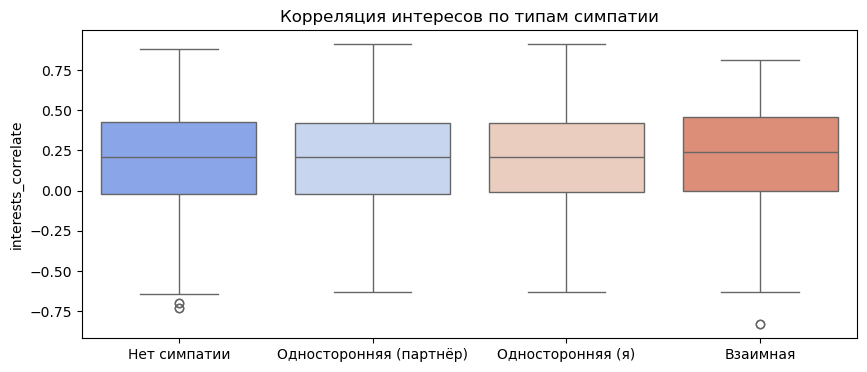

In [100]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=df_clean, x='interest_type', y='interests_correlate', order=order, palette='coolwarm')
plt.title('Корреляция интересов по типам симпатии')
plt.xlabel('')
plt.show()

In [101]:
pivot_corr = df_clean.groupby('interest_type')['interests_correlate'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
).reindex(order).round(3)

pivot_corr.columns = ['Количество', 'Среднее', 'Медиана', 'Ст. отклонение', 'Минимум', 'Максимум']
display(pivot_corr)

,Количество,Среднее,Медиана,Ст. отклонение,Минимум,Максимум
interest_type,,,,,,
Нет симпатии,2698,0.190,0.21,0.308,-0.73,0.88
Односторонняя (партнёр),2106,0.194,0.21,0.298,-0.63,0.91
Односторонняя (я),2130,0.193,0.21,0.296,-0.63,0.91
Взаимная,1365,0.217,0.24,0.305,-0.83,0.81


In [102]:
cols_interest_diff = [
    "d_sports", "d_tvsports", "d_exercise", "d_dining", "d_museums", 
    "d_art", "d_hiking", "d_gaming", "d_clubbing", "d_reading", 
    "d_tv", "d_theater", "d_movies", "d_concerts", "d_music", 
    "d_shopping", "d_yoga"
]

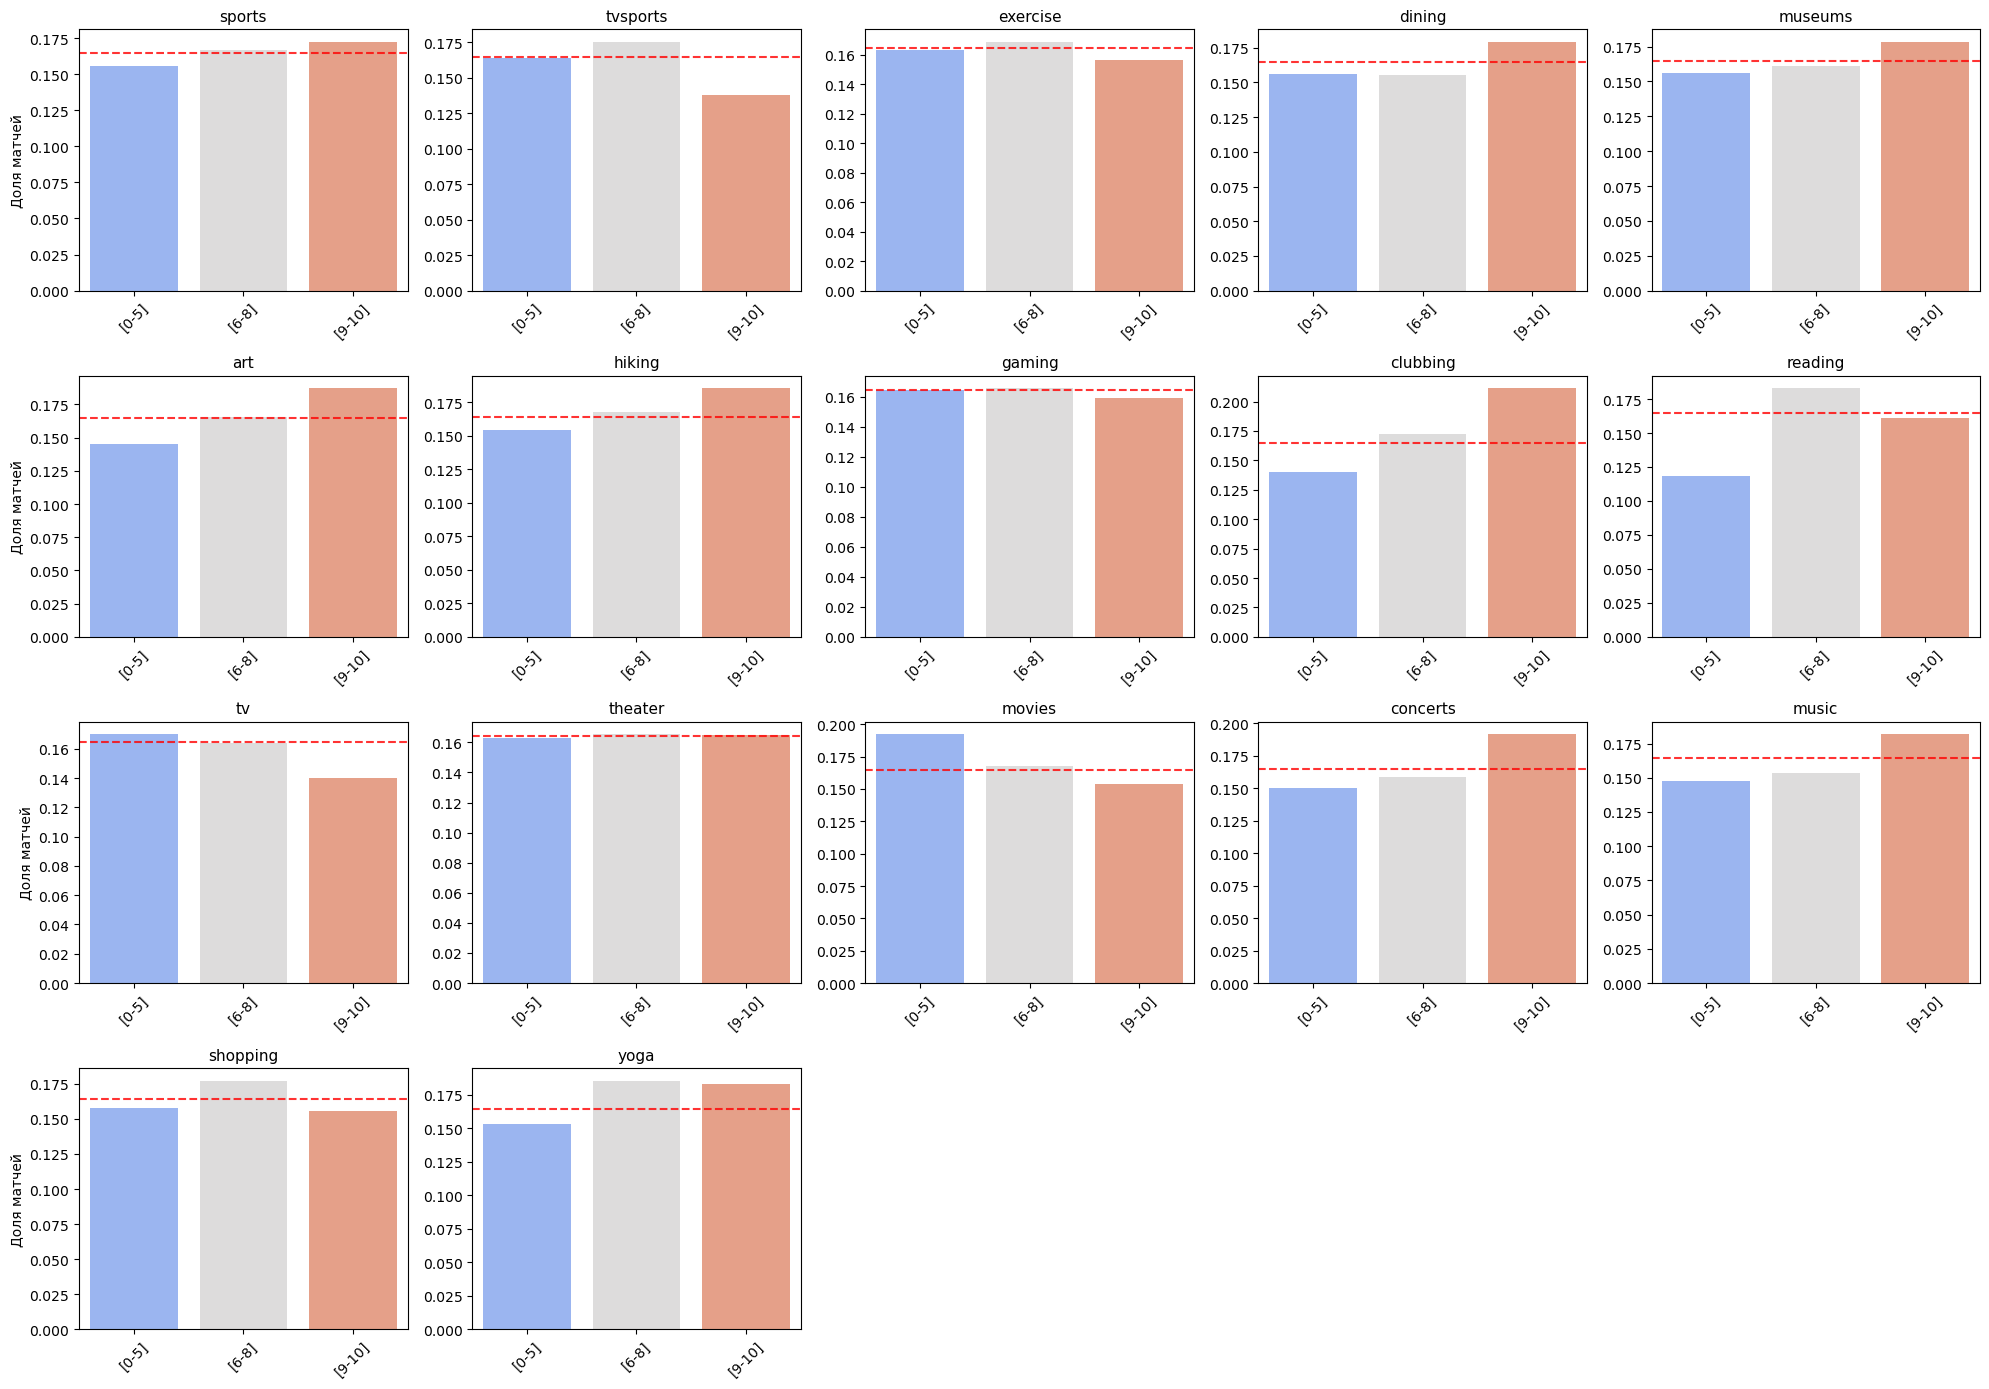

In [103]:
fig, axes = plt.subplots(4, 5, figsize=(20, 14))
axes = axes.flatten()

for i, col in enumerate(cols_interest_diff):
    # Считаем долю матчей для каждой категории разницы
    match_rate = df_clean.groupby(col)['match'].mean().reset_index()
    
    # Сортируем категории по возрастанию (если нужно)
    # match_rate = match_rate.sort_values(col) 
    
    sns.barplot(data=match_rate, x=col, y='match', palette='coolwarm', ax=axes[i])
    
    axes[i].set_title(col.replace('d_', ''), fontsize=11)
    axes[i].set_ylabel('Доля матчей' if i % 5 == 0 else '')
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=45)
    
    # Добавляем горизонтальную линию среднего уровня матчей
    axes[i].axhline(df_clean['match'].mean(), color='red', linestyle='--', alpha=0.8)

# Удаляем пустые оси
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Анализ показал, что общие интересы играют второстепенную роль в возникновении взаимной симпатии. Суммарная корреляция интересов у взаимных пар хоть и выше (0,182 против ~0,15), но разница незначительна, а медианы почти совпадают. Разностные признаки по отдельным хобби также не выявляют чёткого паттерна: для большинства активностей доля матчей слабо зависит от разницы в интересах. Исключение составляют лишь отдельные сферы (искусство, музыка, концерты), где при большей разнице доля матчей даже возрастает, однако эти эффекты слабовыражены. 

In [104]:
ru('like')

'понравился ли партнёр'

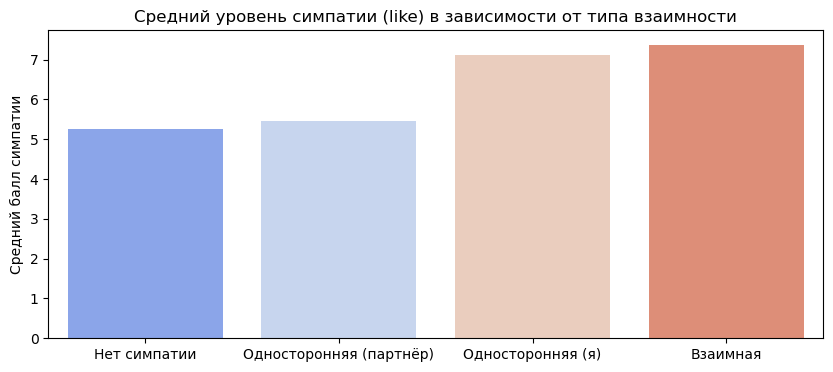

In [105]:
# Сравнение односторонней и взаимной симпатии
plt.figure(figsize=(10, 4))
# Смотрим на среднюю симпатию к партнёру
sns.barplot(data=df_clean, x='interest_type', y='like', order=order, palette='coolwarm', errorbar=None)
plt.title('Средний уровень симпатии (like) в зависимости от типа взаимности')
plt.xlabel('')
plt.ylabel('Средний балл симпатии')
plt.show()

Сравнение односторонней и взаимной симпатии. Уровень симпатии (like) чётко отражает исход: самый низкий он при отсутствии симпатии (5,2), а самый высокий при взаимной (7,4). Важно, что при односторонней симпатии со стороны партнёра уровень like остаётся низким (5,4), то есть человека не заставляет симпатизировать ответный интерес, и лишь собственная высокая оценка (категория «Односторонняя (я)» с уровнем 7,2) двигает к взаимности.

In [106]:
ru('guess_prob_liked')

'оценка вероятности, что я нравлюсь партнёру'

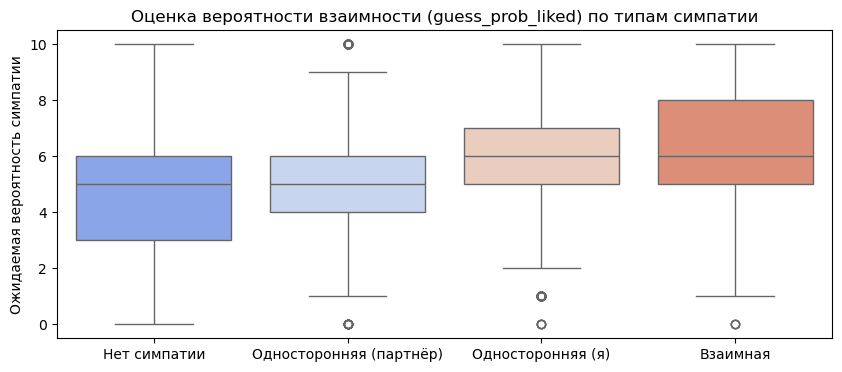

In [107]:
# Насколько участники угадывают интерес
plt.figure(figsize=(10, 4))
sns.boxplot(data=df_clean, x='interest_type', y='guess_prob_liked', order=order, palette='coolwarm')
plt.title('Оценка вероятности взаимности (guess_prob_liked) по типам симпатии')
plt.xlabel('')
plt.ylabel('Ожидаемая вероятность симпатии')
plt.show()

Насколько участники угадывают интерес. Участники достаточно точно считывают отношение к себе. Медианное ожидание взаимности (guess_prob_liked) минимально при отсутствии симпатии (4) и максимально при взаимной (6), причём разброс при взаимности самый плотный и сдвинут вверх. При односторонней симпатии респонденты склонны занижать свои шансы (медиана 5).

**Общий вывод по разделу:** Исследование показало, что для возникновения взаимной симпатии критически важно совпадение высоких оценок с обеих сторон: если оба участника высоко оценивают привлекательность, юмор и интеллект друг друга, вероятность матча резко возрастает. При односторонней симпатии наблюдается асимметрия: одна сторона даёт высокие баллы, а другая низкие, и матч не случается. При этом уровень симпатии напрямую отражает исход: он минимален при отсутствии интереса и максимален при взаимности. Важно, что ответная симпатия партнёра сама по себе не повышает уровень симпатии у респондента — к матчу ведёт именно собственная высокая оценка партнёра. Общие интересы играют второстепенную роль: хотя у взаимных пар суммарная корреляция интересов чуть выше, разница незначительна, а разностные признаки по большинству хобби не выявляют чёткого паттерна. Участники при этом достаточно точно считывают отношение к себе: ожидание взаимности минимально при отсутствии симпатии и максимально при взаимной, хотя при односторонней симпатии респонденты склонны слегка занижать свои шансы.

## Построение моделей

Опираясь на предыдущие выводы (слабая роль демографии, общих интересов, важность взаимных оценок и уверенности в себе), можно сформулировать следующие гипотезы для проверки и построения моделей:

**Гипотеза 1. Взаимные субъективные оценки важнее самооценок.**  
Для возникновения матча критически важны высокие оценки партнёра с обеих сторон (внешность, юмор, интеллект). При этом то, насколько человек высоко оценивает *себя*, само по себе не гарантирует матч.  
*Ожидаемый результат:* признаки группы `*_o` (оценки партнёра) и `*_partner` (оценки партнёром) окажутся наиболее значимыми в моделях, а самооценки — слабыми предикторами.

**Гипотеза 2. `like` и `guess_prob_liked` — late-proxy признаки, искусственно завышающие качество.**  
Переменная `like` (насколько партнёр понравился участнику) и `guess_prob_liked` (ожидание взаимности) становятся известны только *после* свидания и фактически предсказывают `match` почти напрямую. Их включение в основную модель даст нереалистично высокие метрики, поэтому в базовое решение они не войдут.  
*Ожидаемый результат:* при обучении основной модели без прокси-признаков метрики будут заметно ниже, чем в late-proxy эксперименте; сравнение двух подходов продемонстрирует искусственное упрощение задачи.

**Гипотеза 3. Демография и общие интересы не значимы.**  
Возраст, пол, раса и разница в возрасте не влияют на вероятность матча. Общие интересы (корреляция хобби) и разница в интересах также не являются значимыми предикторами — их вклад в модель будет близок к нулю.  
*Ожидаемый результат:* низкая важность этих признаков; возможное исключение их из финальной модели без потери качества.

**Гипотеза 4. Амбициозность — вторичный фактор.**  
В отличие от внешности и юмора, амбициозность (своя и партнёра) слабо влияет на исход свидания. Мы не ожидаем, что этот признак войдёт в топ значимых.  
*Ожидаемый результат:* низкие коэффициенты важности у `ambition`, `ambitous_o`, `ambition_partner`.

**Гипотеза 5. Различия в хобби важнее их сходства (для отдельных сфер).**  
Хотя суммарная корреляция интересов слабо влияет на матч, для некоторых активностей (искусство, музыка, концерты) большая разница в интересах может даже повышать вероятность матча (эффект «интересного дополнения»).  
*Ожидаемый результат:* нелинейные зависимости для отдельных `d_*` признаков (например, `d_art`, `d_music`), которые могут проявиться в древовидных моделях.

**Гипотеза 6. Несбалансированность классов требует особого подхода.**  
Поскольку матчи составляют около 16% наблюдений, стандартные модели могут смещаться в сторону класса «несовпадение».  
*Ожидаемый результат:* для качественного прогноза потребуется балансировка классов (`class_weight`, SMOTE и т.д.) и использование метрик вроде PR-AUC, F1-score, ROC-AUC вместо Accuracy.

**Гипотеза 7. Пол не влияет на вероятность матча.**  
Пол респондента не является значимым предиктором взаимной симпатии: мужчины и женщины имеют практически одинаковую долю совпадений. Мы ожидаем, что после кодирования признака `gender` его коэффициент в модели окажется статистически незначимым и близким к нулю, а включение пола не улучшит качество прогноза.  
*Ожидаемый результат:* низкая важность признака `gender` в моделях, отсутствие статистически значимой разницы между группами при проверке гипотез (например, критерий хи-квадрат), возможность исключить его без потери качества.

**Гипотеза 8. Инжиниринг парных признаков улучшит модель.**  
Исходные оценки сами по себе содержат много шума; производные признаки (например, разности между самооценкой и оценкой партнёра, средние оценки пары по каждому качеству, абсолютные разницы) лучше отражают взаимную совместимость и повысят качество модели по сравнению с использованием только исходных оценок.  
*Ожидаемый результат:* сравнение на одном split покажет прирост PR-AUC у модели с engineered pair features относительно модели только на исходных оценках.